# 01 — The problem and the data: sources, cleaning rules and the readiness gates

Every file the project uses is fetched, checked and documented here; the LBNL queue file is cleaned by the numbered rules R1–R9; the 2026 edition is reconciled with the frozen 2025 file; and the readiness gates (v1 sources, v3 sources) are written to `docs/data_readiness.md`. No modelling starts before GO.

**Inputs → Outputs**

| Part | Was | What it does |
|---|---|---|
| A | notebook 01 | Get the data and pass the readiness gate |
| B | notebook 02 | Clean the queue data |
| C | notebook 01b | The LBNL 2026 data file beside the frozen 2025 file |
| D | new (2026-10-12) | The v5 energy sources: BSEE production, EIA-923, prices, eGRID, the manifest |
| E | new (2026-10-12) | The energy panel: real dollars, Texas generators, release lags, audits R10–R13, the v5 gate |

*Execution order:* Runs first. Paths are relative to the repository root.

*Part A*

| | Path | Notes |
|---|---|---|
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | LBNL Queued Up 2025, placed by hand (decision #10) |
| in | EIA API v2 `electricity/operating-generator-capacity` | key read from `.env`, never shown |
| out | `data/raw/lbnl/SHA256.txt` | checksum of the frozen file |
| out | `data/raw/eia860m/api_<period>_page<N>.json`, `eia860m_<period>.parquet` | API pages as returned + combined table (cached) |
| out | `data/processed/technology_crosswalk.csv`, `linkage_test_matches.csv` | EIA technology → LBNL type; quick-linkage results |
| out | `results/audit_counts.json`, `event_date_coverage.csv`, `headline_checks.json`, `ir_to_cod_by_year.csv`, `naive_mockup.csv`, `eia860m_profile.json`, `linkage_test.csv`, `readiness_checks.csv` | numbers the readiness report cites |
| out | `figures/01_problem_and_data/*.png|svg`, `report/figure_notes.md` | 22 exploratory figures + caption stubs |
| out | `data/README.md` (dictionary section), `docs/data_readiness.md` | data access statement + dictionary; the gate |

*Part B*

| | Path | Notes |
|---|---|---|
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | frozen release, verified by SHA-256 |
| out | `data/interim/queue_clean.parquet` | clean table, one row per generation request |
| out | `results/clean_log.csv` | rows touched by each rule (pinned by `tests/test_cleaning.py`) |
| out | `results/clean_checks.csv` | the notebook's acceptance checks, PASS/FAIL |
| out | `figures/01_problem_and_data/*.png|svg`, `report/figure_notes.md` | 9 exploratory figures + caption stubs |

*Part C*

| | Path | Notes |
|---|---|---|
| in | `data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx` | the frozen 2025 edition (S1) |
| in | `data/raw/lbnl/LBNL_Ix_Queue_Data_File_thru2025.xlsx` | the 2026 edition (S6), SHA-256 checked against `src/config.py` |
| in | `data/interim/queue_clean.parquet`, `data/interim/trackA.parquet` | notebooks 02/04 — the 2025 file cleaned and coded |
| out | `data/interim/queue_clean_2026.parquet`, `results/clean_log_2026.csv` | the 2026 file through rules R2–R9 (R1 is not needed: its dates are real dates) |
| out | `results/lbnl_2026_layout.csv` | column differences between the editions |
| out | `results/lbnl_2026_reconciliation.csv`, `results/lbnl_2026_status_transitions.csv`, `results/lbnl_2026_date_changes.csv` | the same requests in both editions |
| out | `results/lbnl_2026_date_coverage.csv` | event-date coverage by region, both editions |
| out | `docs/data_readiness.md` (section "v3 sources") | the S6 readiness lines, PASS/FAIL |
| out | `figures/01_problem_and_data/*` | this notebook's figures |
| out | `results/lbnl_2026_checks.csv` | this notebook's checks |

*Part D*

| | Path | Notes |
|---|---|---|
| in | `data/raw/bsee/ogora<year>delimit.zip` (2010–2024), `data/raw/eia923/*`, `data/raw/prices/*.xls`, `data/raw/ercot/*.parquet`, `data/raw/egrid/*.xlsx` | S13–S17, fetched or verified by `src/energy_data.py` |
| out | `data/interim/upstream_monthly.parquet`, `data/interim/generation_monthly.parquet`, `data/interim/egrid_plants_tx.parquet` | lease-months, plant × prime-mover months, Texas plants |
| out | `results/v5_bsee_by_year.csv`, `results/v5_texas_plants_by_technology.csv`, `results/v5_egrid_tx_summary.csv` | counts the report cites |
| out | `data/raw/manifest_v5.json` | URL, retrieval date, vintage, SHA-256, units, grain per source |
| out | `figures/01_problem_and_data/01_D1…01_D3` | production, generation and prices with provenance labels |

*Part E*

| | Path | Notes |
|---|---|---|
| in | `data/raw/prices/bls_CUUR0000SA0_2016-2024.json`, `data/raw/eia860m/eia860m_<period>.parquet` | S18 CPI-U; S2 generators |
| out | `data/interim/market_monthly.parquet`, `data/interim/cpi_monthly.parquet`, `data/interim/plant_generators_tx.parquet` | prices nominal and real 2024; Texas generators |
| out | `data/processed/release_lags.csv`, `data/processed/energy_panel_summary.csv` | committed, small |
| out | `results/v5_panel_audits.csv`, `results/v5_readiness_checks.csv`, `docs/data_readiness.md` (section "v5 sources") | audits R10–R13 and the gate, GO/NO-GO |

# Part A — Get the data and pass the readiness gate (was notebook 01)

This notebook gathers both required sources (the LBNL queue file and EIA-860M
through the EIA API), checks that they can carry a time-to-event model of
interconnection queues, and records a GO/NO-GO before any modeling starts.

## Setup

Imports come from the project's `src/` package; every path comes from
`src/paths.py`, so nothing below hard-codes a location. `save()` is a
two-line wrapper that files every figure of this notebook under
`figures/01_problem_and_data/` and adds its caption stub to `report/figure_notes.md`.

In [1]:
import json
import re
import subprocess
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import audit_queue, config, eia_api, get_lbnl, linkage, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "01_problem_and_data"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/01_problem_and_data/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"


def year_ticks(ax, start, stop, step=5):
    """Whole-year ticks on the x axis."""
    ax.set_xticks(range(start, stop + 1, step))


def region_name(region):
    """Region name as it reads in a sentence ("the West", but "PJM")."""
    return f"the {region}" if region in ("West", "Southeast") else region

## 1. Set-up and secrets

The EIA key is personal and must never appear in an output. `eia_api.load_api_key()` reads it
from `.env` and stops with instructions if it is missing; the cell prints only
whether it was found.

In [2]:
eia_key = eia_api.load_api_key()
print("EIA_API_KEY found in .env:", bool(eia_key))

EIA_API_KEY found in .env: True


## 2. The LBNL file (source S1)

`get_lbnl.download()` uses the workbook already in `data/raw/lbnl/`, checks
its SHA-256 against the frozen release (decision #2) and writes `SHA256.txt`.
The release check only *looks* at the LBNL page; it never switches files. A
different file on the page would be an open item for Alan.

In [3]:
lbnl_path = get_lbnl.download()
release = get_lbnl.check_for_newer_release()

print("File:", lbnl_path.relative_to(paths.REPO).as_posix())
print(f"Size: {lbnl_path.stat().st_size / 2**20:.1f} MiB")
print("SHA-256 matches the frozen release:", get_lbnl.sha256(lbnl_path) == config.LBNL_SHA256)
print("Release check on the LBNL page:", release["status"], release["detail"])
if release["status"] == "newer":
    print("ASK ALAN — the page offers a different file:", release["links"])

File: data/raw/lbnl/lbnl_ix_queue_data_file_thru2024_v2.xlsx
Size: 13.4 MiB
SHA-256 matches the frozen release: True
Release check on the LBNL page: unreachable HTTP 403 (bot filter or page change)


## 3. First look at the LBNL file

### 3.1 Shape, columns and the codebook

Sheet `03. Complete Queue Data`, read with `header=1` (row 0 is a banner).
The codebook sheet lists every field LBNL documents; comparing the two shows
what the public file leaves out.

In [4]:
raw = get_lbnl.load_queue(lbnl_path)
codebook = pd.read_excel(lbnl_path, sheet_name="04. Data Codebook", header=1).dropna(how="all")
codebook.columns = ["field", "description"]

print("Shape:", raw.shape)
print("Columns:", ", ".join(raw.columns))
print("In the codebook but not in sheet 03:", sorted(set(codebook["field"]) - set(raw.columns)))

Shape: (36441, 31)
Columns: q_id, q_status, q_date, prop_date, on_date, wd_date, ia_date, IA_status_raw, IA_status_clean, county, state, county_state_pairs, fips_codes, poi_name, region, project_name, utility, entity, developer, cluster, service, project_type, type1, type2, type3, mw1, mw2, mw3, type_clean, q_year, prop_year
In the codebook but not in sheet 03: ['interconnecting_entity', 'interconnection_voltage_kv', 'latitude', 'longitude']


### 3.2 Counts against the 2026-10-03 audit

The gate's second check: the file must reproduce the audit's counts exactly.
The counts are saved to `results/audit_counts.json`, which
`tests/test_cleaning.py::test_audit_counts` pins.

In [5]:
counts = audit_queue.audit_counts(raw)
(paths.RESULTS / "audit_counts.json").write_text(json.dumps(counts, indent=2), encoding="utf-8")

rows = []
for item, expected in config.AUDIT_EXPECTED.items():
    if isinstance(expected, dict):
        rows += [{"item": f"{item} = {key}", "expected": value, "observed": counts[item].get(key, 0)}
                 for key, value in expected.items()]
    else:
        rows.append({"item": item, "expected": expected, "observed": counts[item]})
audit_table = pd.DataFrame(rows).assign(match=lambda t: t["expected"] == t["observed"])
print(f"{audit_table['match'].sum()} of {len(audit_table)} audit items match")
audit_table

18 of 18 audit items match


,item,expected,observed,match
0,n_rows,36441,36441,True
1,n_cols,31,31,True
2,q_status = withdrawn,20921,20921,True
3,q_status = active,10538,10538,True
4,q_status = operational,4432,4432,True
5,q_status = suspended,546,546,True
6,q_status = unknown,4,4,True
7,region = PJM,8152,8152,True
8,region = West,7675,7675,True
9,region = MISO,4978,4978,True


In [6]:
other = {k: counts[k] for k in ["missing_q_date", "zero_mw_rows", "mw_over_5000_rows", "max_mw",
                                "duplicate_key_rows", "missing_q_year"]}
print("Other facts for notebook 02:", other)
raw["type_clean"].value_counts().head(12).to_frame("projects")

Other facts for notebook 02: {'missing_q_date': 607, 'zero_mw_rows': 0, 'mw_over_5000_rows': 2, 'max_mw': 16875.0, 'duplicate_key_rows': 2, 'missing_q_year': 607}


,projects
type_clean,
Solar,13564
Wind,6317
Battery,5536
Solar+Battery,3698
Gas,3326
Other,1721
Hydro,493
Coal,426
Offshore Wind,235


**Reading this.** All 18 audit items match exactly: 36,441 rows × 31 columns, the five status counts, the nine region counts, 204 placeholder request dates and 17 negative-MW rows. Three facts differ from how PLAN.md words them, and they go to notebook 02: there are **2** rows above 5,000 MW (the largest is 16,875 MW), not one; the "607 year mismatches" are in fact 607 rows with no `q_year`, and the same number of rows (607) has no `q_date`, so recomputing the year from the date (rule R2) will not fill them; and the (`q_id`, `entity`) key repeats in 2 rows, i.e. one duplicate pair (rule R7). The codebook lists latitude, longitude, voltage and interconnecting entity, but the public sheet carries none of them, so any location beyond state and county has to come from EIA-860M.

### 3.3 Which columns are filled in

Share of rows with a value, for every column except the three status-specific
dates (operation, withdrawal, IA), which are only expected for some statuses
and get their own figure next. Darker bars are the fields the entry-time
features of notebook 04 rely on.

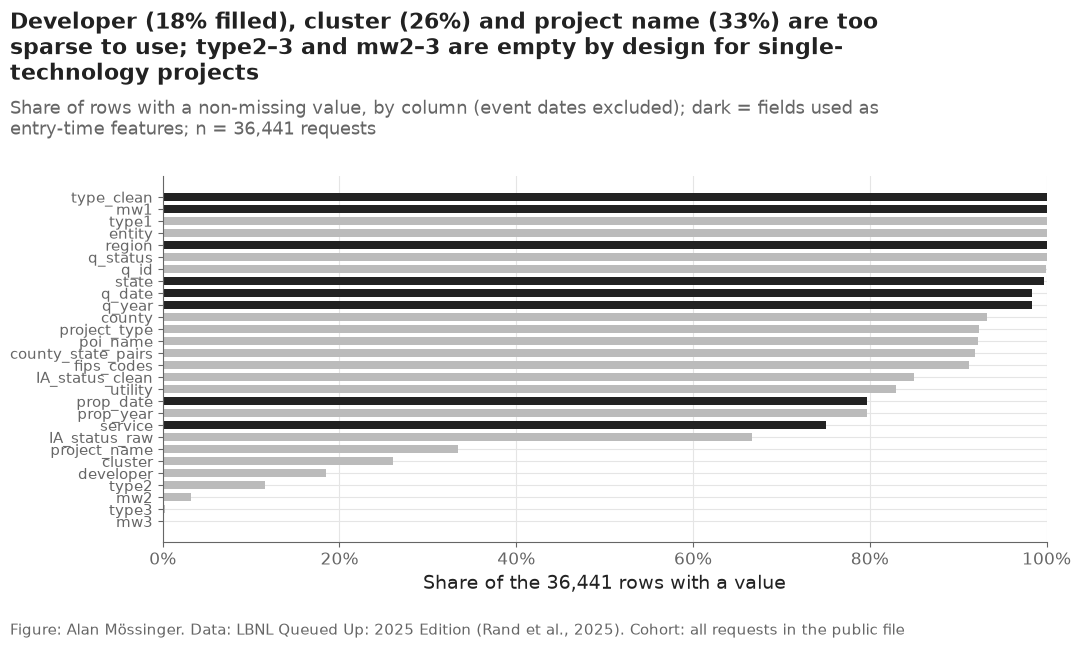

,mw3,type3,mw2,type2,developer,cluster,project_name,IA_status_raw,service,prop_year,prop_date,utility,IA_status_clean,fips_codes,county_state_pairs,poi_name,project_type,county,q_year,q_date,state,q_id,q_status,region,entity,type1,mw1,type_clean
share_filled,0.001,0.003,0.032,0.116,0.185,0.261,0.334,0.667,0.751,0.797,0.797,0.829,0.85,0.913,0.919,0.922,0.924,0.933,0.983,0.983,0.997,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [7]:
status_dates = ["on_date", "wd_date", "ia_date"]
completeness = raw.drop(columns=status_dates).notna().mean().sort_values()
feature_fields = {"q_date", "region", "state", "type_clean", "mw1", "service", "prop_date", "q_year"}

fig, ax = plt.subplots()
colors = [plots.INK if c in feature_fields else "#BBBBBB" for c in completeness.index]
ax.barh(completeness.index, completeness.values, color=colors, height=0.7)
ax.set_xlim(0, 1)
ax.set_xlabel("Share of the 36,441 rows with a value")
ax.tick_params(axis="y", labelsize=11)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
plots.finish(fig,
             f"Developer ({completeness['developer']:.0%} filled), cluster ({completeness['cluster']:.0%}) "
             f"and project name ({completeness['project_name']:.0%}) are too sparse to use; "
             "type2–3 and mw2–3 are empty by design for single-technology projects",
             "Share of rows with a non-missing value, by column (event dates excluded); "
             "dark = fields used as entry-time features; n = 36,441 requests",
             "all requests in the public file")
save(fig, "01_01_column_completeness",
     "Share of the 36,441 LBNL queue rows with a value in each column; status-specific "
     "event dates are excluded and shown in 01_02.")
plt.show()
completeness.round(3).to_frame("share_filled").T

**Reading this.** Developer (18.5% filled), cluster (26.1%) and project name (33.4%) are mostly empty, which is why rule R8 keeps them out of the models. `type2`, `type3`, `mw2` and `mw3` are empty by design: only hybrids have a second resource. The fields the entry-time features need (dark bars) are well filled, with two exceptions that will need a "missing" level or flag in notebook 04: `service` (75.1%) and the proposed online date (79.7%). For a developer or lender this sets the scope plainly: the model can only use what nearly every request reports — where, what, how big and when.

### 3.4 Event-date coverage by region — why three ISOs define Track A

A time-to-event model needs both ends of the clock. Dates are converted from
Excel serials; the 1970-01-01 placeholder counts as missing. The table goes
to `results/event_date_coverage.csv`.

In [8]:
dated = audit_queue.with_dates(raw)
dated["tech_group"] = dated["type_clean"].map(plots.tech_group)
coverage = audit_queue.event_date_coverage(dated)
coverage.to_csv(paths.RESULTS / "event_date_coverage.csv", index=False)

shares = coverage.set_index("region")[["q_date_share", "on_date_share", "wd_date_share"]]
(100 * shares).round(1)

,q_date_share,on_date_share,wd_date_share
region,,,
ERCOT,91.8,98.4,100.0
PJM,99.7,97.8,96.9
CAISO,99.8,95.2,82.6
MISO,99.7,1.4,41.8
SPP,98.7,4.9,0.0
NYISO,99.9,0.9,0.0
ISO-NE,99.3,4.1,97.9
West,97.8,21.5,7.5
Southeast,92.8,57.4,33.7


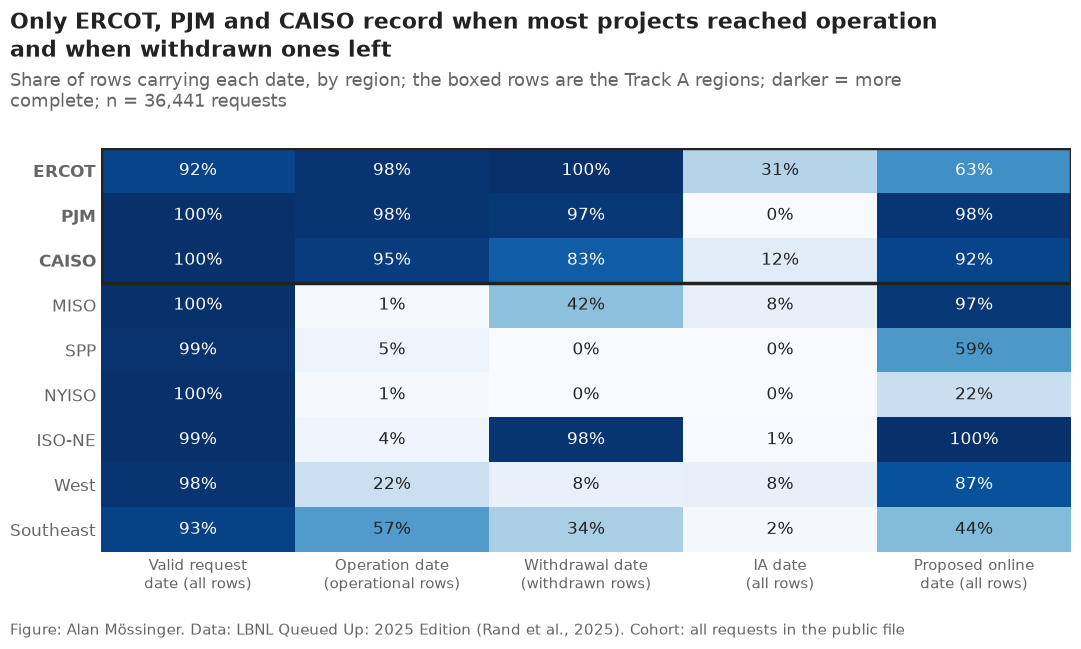

In [9]:
by_region = dated.groupby("region")
heat = pd.DataFrame({
    "Valid request\ndate (all rows)": coverage.set_index("region")["q_date_share"],
    "Operation date\n(operational rows)": coverage.set_index("region")["on_date_share"],
    "Withdrawal date\n(withdrawn rows)": coverage.set_index("region")["wd_date_share"],
    "IA date\n(all rows)": by_region["ia_date"].apply(lambda s: s.notna().mean()),
    "Proposed online\ndate (all rows)": by_region["prop_date"].apply(lambda s: s.notna().mean()),
}).reindex(config.ALL_REGIONS)

fig, ax = plt.subplots()
ax.imshow(heat.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(heat.shape[1]), heat.columns, fontsize=11)
ax.set_yticks(range(heat.shape[0]), heat.index)
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        value = heat.iat[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=12,
                color="white" if value > 0.6 else plots.INK)
ax.add_patch(Rectangle((-0.5, -0.5), heat.shape[1], len(TRACK_A), fill=False,
                       edgecolor=plots.INK, linewidth=2.5))
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
both = [r for r in config.ALL_REGIONS
        if coverage.set_index("region").loc[r, "on_date_share"] >= 0.9
        and coverage.set_index("region").loc[r, "wd_date_share"] >= 0.8]
plots.finish(fig,
             f"Only {', '.join(both[:-1])} and {both[-1]} record when most projects "
             "reached operation and when withdrawn ones left",
             "Share of rows carrying each date, by region; the boxed rows are the Track A regions; "
             "darker = more complete; n = 36,441 requests",
             "all requests in the public file")
save(fig, "01_02_event_date_coverage",
     "Share of LBNL queue rows carrying each date field, by region. Operation and withdrawal "
     "dates are measured among operational and withdrawn rows respectively.")
plt.show()

**Reading this.** The three boxed ISOs are the only regions where both ends of the clock are recorded for most projects: operation dates for 95.2–98.4% of operational rows and withdrawal dates for 82.6–100% of withdrawn rows. Everywhere else one end is missing: MISO records an operation date for 1.4% of its operational rows, SPP and NYISO record no withdrawal dates at all, and the West has 21.5% and 7.5%. This is why the timing model (Track A) uses only CAISO, ERCOT and PJM and the other six regions enter only the all-regions "ever built?" model (Track B, decision #6). CAISO's withdrawal-date coverage (82.6%) is the weakest of the three; it failed the plan's original 83% bar, which Alan then set to 82% (decision #15). ERCOT has the weakest request-date coverage (91.8%). Interconnection-agreement dates are sparse everywhere; that does not matter for the main models because they are post-entry information (decision #7). Caveat: this is coverage of the *public* file — LBNL's report draws on some non-public data.

### 3.5 How the queue grew

Requests per year by region (small multiples, shared scale so panel heights
compare volumes), then requested capacity per year by technology.

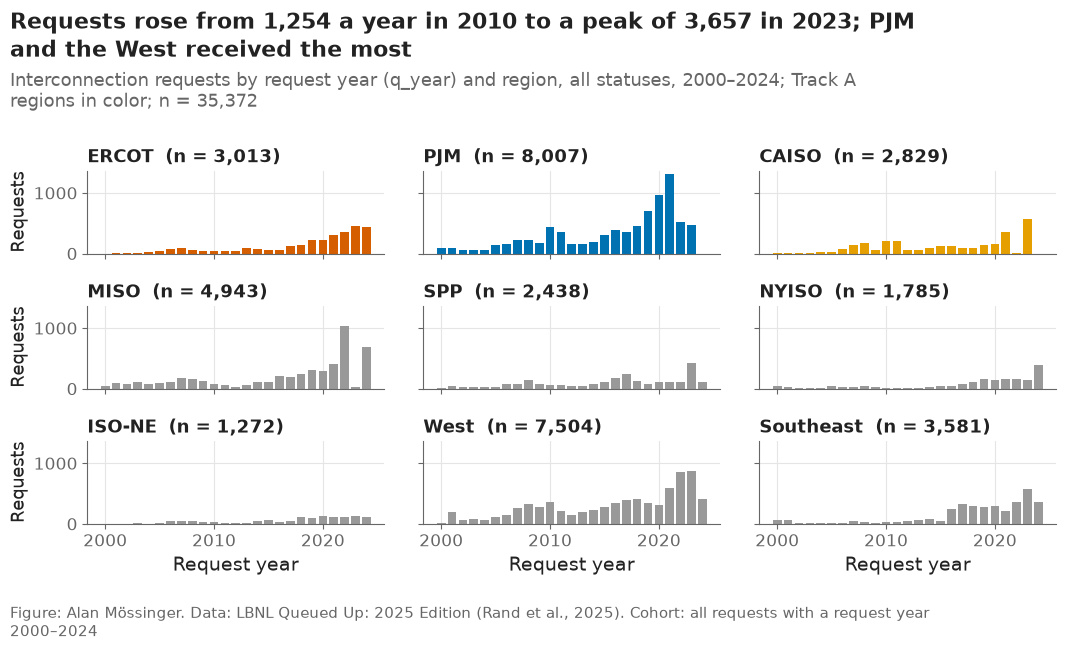

q_year,2010,2015,2019,2020,2021,2022,2023,2024
requests,1254,1123,2328,2622,3565,3525,3657,2493


In [10]:
years = range(2000, 2025)
per_year = (dated[dated["q_year"].between(2000, 2024)]
            .groupby(["q_year", "region"]).size().unstack().reindex(years).fillna(0))
national = per_year.sum(axis=1)

fig, axes = plt.subplots(3, 3, sharex=True, sharey=True)
for ax, region in zip(axes.flat, config.ALL_REGIONS):
    ax.bar(per_year.index, per_year[region], color=plots.region_color(region), width=0.8)
    ax.set_title(f"{region}  (n = {int(per_year[region].sum()):,})", fontsize=13)
for ax in axes[:, 0]:
    ax.set_ylabel("Requests")
for ax in axes[-1]:
    ax.set_xlabel("Request year")
peak = int(national.idxmax())
top_two = per_year.sum().sort_values(ascending=False).index[:2]
plots.finish(fig,
             f"Requests rose from {int(national[2010]):,} a year in 2010 to a peak of "
             f"{int(national.max()):,} in {peak}; {region_name(top_two[0])} and {region_name(top_two[1])} "
             "received the most",
             "Interconnection requests by request year (q_year) and region, all statuses, 2000–2024; "
             "Track A regions in color; n = " + f"{int(national.sum()):,}",
             "all requests with a request year 2000–2024")
save(fig, "01_03_requests_by_year_region",
     "Number of interconnection requests per year by region, 2000–2024, all statuses.")
plt.show()
national.loc[[2010, 2015, 2019, 2020, 2021, 2022, 2023, 2024]].astype(int).to_frame("requests").T

**Reading this.** National requests rose from 1,254 in 2010 to a peak of 3,657 in 2023 and fell to 2,493 in 2024. PJM (8,007 requests since 2000) and the West (7,504) received the most. The panels are not smooth trends: CAISO has no bar in 2022 or 2024 and MISO's 2023 bar is almost empty, which looks like requests being accepted in periodic windows rather than continuously. I have not yet checked this against each ISO's queue rules, so the report will not lean on it until I do. For the models it means request year acts as a cohort marker with jumps, not as a smooth time trend.

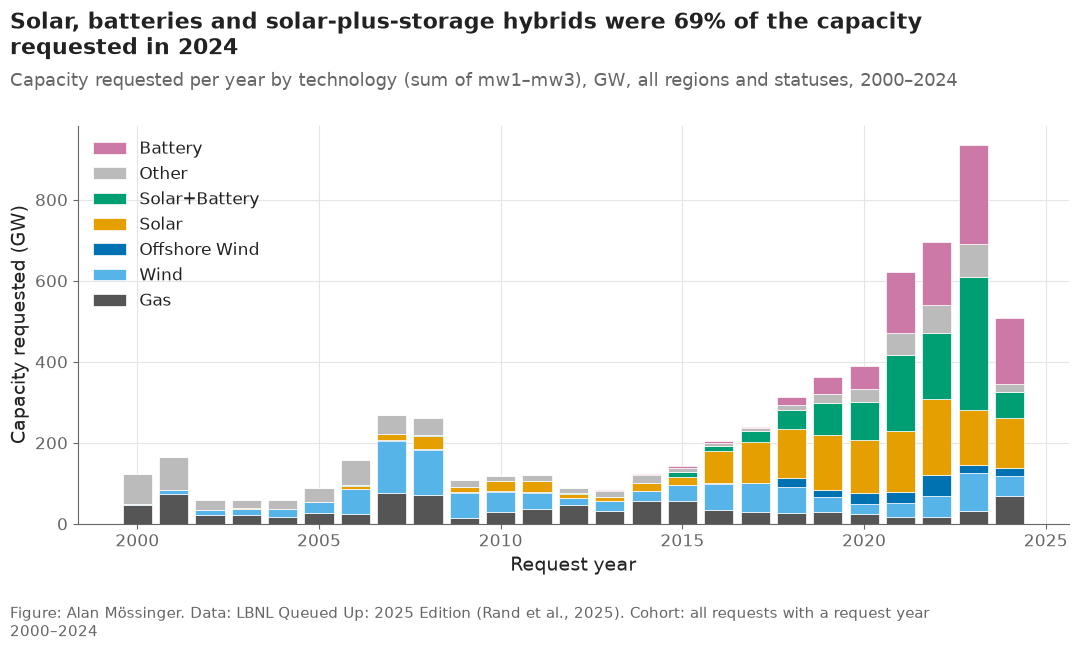

tech_group,Gas,Wind,Offshore Wind,Solar,Solar+Battery,Other,Battery
q_year,,,,,,,
2015,55.0,40.0,0.0,21.0,11.0,10.0,6.0
2020,25.0,25.0,27.0,130.0,94.0,32.0,57.0
2022,18.0,51.0,51.0,189.0,163.0,68.0,156.0
2023,32.0,92.0,21.0,134.0,329.0,83.0,245.0
2024,70.0,47.0,21.0,124.0,63.0,19.0,163.0


In [11]:
stack_order = ["Gas", "Wind", "Offshore Wind", "Solar", "Solar+Battery", "Other", "Battery"]
cap = (dated[dated["q_year"].between(2000, 2024)]
       .groupby(["q_year", "tech_group"])["mw"].sum().unstack()
       .reindex(index=years, columns=stack_order).fillna(0) / 1000)

fig, ax = plt.subplots()
bottom = np.zeros(len(cap))
for group in stack_order:
    ax.bar(cap.index, cap[group], bottom=bottom, color=config.TECH_COLORS[group], width=0.8,
           label=group, edgecolor="white", linewidth=0.5)
    bottom += cap[group].values
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper left")
ax.set_xlabel("Request year")
ax.set_ylabel("Capacity requested (GW)")
clean_share = cap.loc[2024, ["Solar", "Solar+Battery", "Battery"]].sum() / cap.loc[2024].sum()
plots.finish(fig,
             f"Solar, batteries and solar-plus-storage hybrids were {clean_share:.0%} of the "
             f"capacity requested in 2024",
             "Capacity requested per year by technology (sum of mw1–mw3), GW, all regions and statuses, "
             "2000–2024",
             "all requests with a request year 2000–2024")
save(fig, "01_04_capacity_by_year_technology",
     "Capacity requested per year by technology group (GW), all regions, 2000–2024.")
plt.show()
cap.loc[[2015, 2020, 2022, 2023, 2024]].round(0)

**Reading this.** The technology mix of the queue changed completely inside the study period. In 2015 gas was the largest group (55 GW requested); by 2023 solar+battery hybrids alone were 329 GW and standalone batteries 245 GW, while gas fell to 25 GW in 2020 and 18 GW in 2022 before rebounding to 70 GW in 2024. Two consequences: technology effects have to be allowed to differ by entry cohort, and most storage requests are recent, so their outcomes are still largely unobserved (censored) — the model will know much less about batteries than about wind.

### 3.6 How requests end

Status mix by region (share of projects), then the outcome of each request
year by capacity. The second figure reproduces LBNL's headline: of capacity
requested in 2000–2019, about 13% reached operation and 77% was withdrawn.

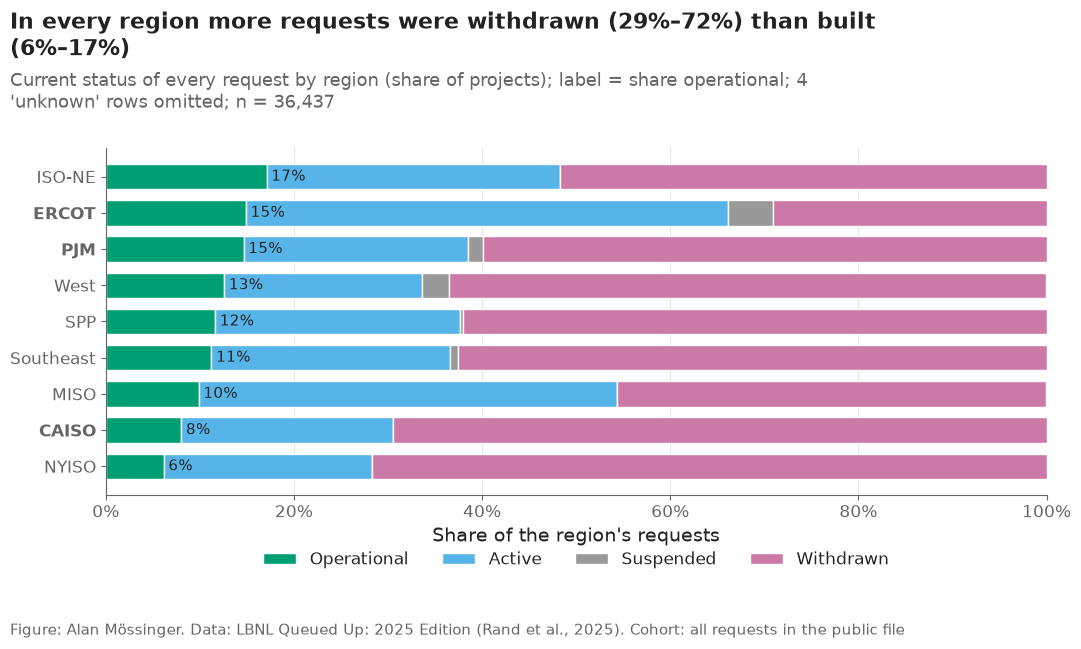

q_status,operational,active,suspended,withdrawn
region,,,,
NYISO,6.2,22.1,0.0,71.7
CAISO,8.0,22.5,0.0,69.5
MISO,9.9,44.5,0.0,45.6
Southeast,11.2,25.4,0.9,62.5
SPP,11.6,26.0,0.3,62.0
West,12.6,21.1,2.8,63.5
PJM,14.7,23.8,1.6,59.9
ERCOT,14.9,51.2,4.8,29.1
ISO-NE,17.1,31.1,0.0,51.8


In [12]:
statuses = ["operational", "active", "suspended", "withdrawn"]
mix = (pd.crosstab(dated["region"], dated["q_status"], normalize="index")
       .reindex(index=config.ALL_REGIONS, columns=statuses).fillna(0)
       .sort_values("operational"))

fig, ax = plt.subplots()
left = np.zeros(len(mix))
for status in statuses:
    ax.barh(mix.index, mix[status], left=left, color=config.STATUS_COLORS[status], height=0.7,
            label=status.capitalize(), edgecolor="white", linewidth=1)
    left += mix[status].values
for i, region in enumerate(mix.index):
    ax.text(mix.loc[region, "operational"] + 0.005, i, f"{mix.loc[region, 'operational']:.0%}",
            va="center", ha="left", fontsize=11, color=plots.INK)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of the region's requests")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plots.finish(fig,
             f"In every region more requests were withdrawn ({mix['withdrawn'].min():.0%}–"
             f"{mix['withdrawn'].max():.0%}) than built ({mix['operational'].min():.0%}–"
             f"{mix['operational'].max():.0%})",
             "Current status of every request by region (share of projects); label = share operational; "
             "4 'unknown' rows omitted; n = 36,437",
             "all requests in the public file")
save(fig, "01_05_status_mix_by_region",
     "Share of requests in each current status (operational, active, suspended, withdrawn) by region.")
plt.show()
(100 * mix).round(1)

**Reading this.** In every region more requests were withdrawn than built: from 29.1% withdrawn against 14.9% operational in ERCOT to 71.7% against 6.2% in NYISO. ERCOT stands out for how much is still open — 51.2% of its requests are active and 4.8% suspended. Among the Track A regions CAISO completes the smallest share (8.0%). These shares pool old, resolved cohorts with recent ones that have had no time to finish, so they understate eventual completion for recent entrants; the survival curves in notebook 03 separate the two. The 4 "unknown" rows are left out.

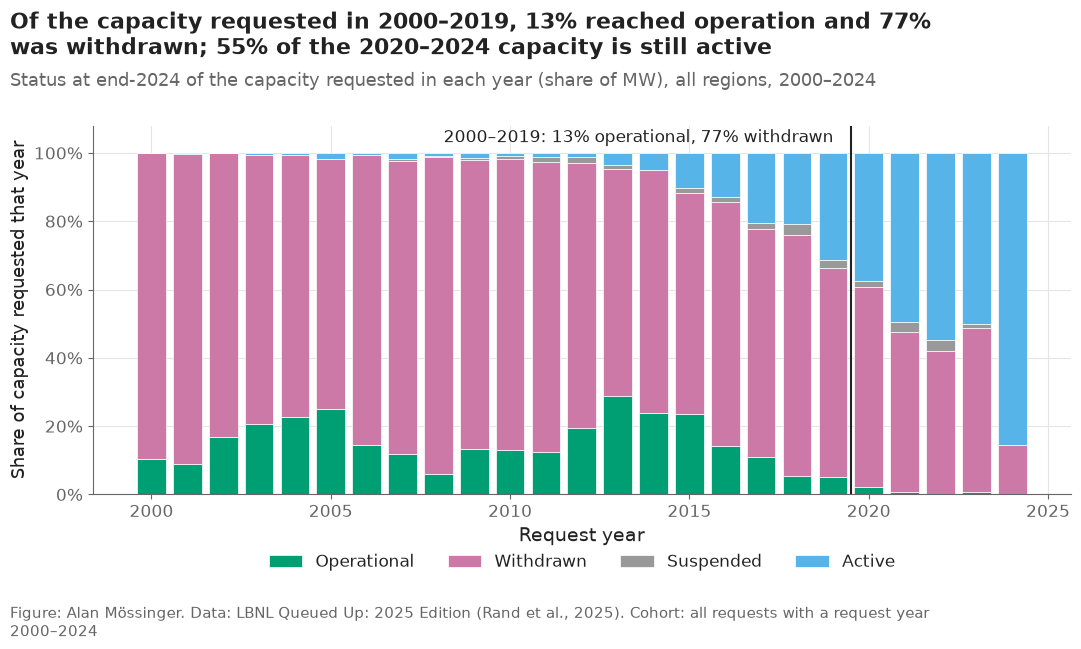

Capacity requested in 2020–2024 that is still active: 55.1%


,q_status,gw,share
0,active,294.383,0.094
1,operational,394.767,0.126
2,suspended,36.758,0.012
3,unknown,0.107,0.000
4,withdrawn,2417.956,0.769


In [13]:
headline = audit_queue.capacity_shares_by_status(dated)
op_share = headline.set_index("q_status").loc["operational", "share"]
wd_share = headline.set_index("q_status").loc["withdrawn", "share"]

by_year = (dated[dated["q_year"].between(2000, 2024)]
           .pivot_table(index="q_year", columns="q_status", values="mw", aggfunc="sum")
           .reindex(index=years, columns=["operational", "withdrawn", "suspended", "active"]).fillna(0))
by_year = by_year.div(by_year.sum(axis=1), axis=0)

fig, ax = plt.subplots()
bottom = np.zeros(len(by_year))
for status in by_year.columns:
    ax.bar(by_year.index, by_year[status], bottom=bottom, color=config.STATUS_COLORS[status],
           width=0.8, label=status.capitalize(), edgecolor="white", linewidth=0.5)
    bottom += by_year[status].values
ax.axvline(2019.5, color=plots.INK, linewidth=1.5)
ax.text(2019.3, 1.02, f"2000–2019: {op_share:.0%} operational, {wd_share:.0%} withdrawn  ",
        ha="right", va="bottom", fontsize=12)
ax.set_ylim(0, 1.08)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_ylabel("Share of capacity requested that year")
ax.set_xlabel("Request year")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
recent_cap = dated[dated["q_year"].between(2020, 2024)]
active_recent = recent_cap.loc[recent_cap["q_status"] == "active", "mw"].sum() / recent_cap["mw"].sum()
plots.finish(fig,
             f"Of the capacity requested in 2000–2019, {op_share:.0%} reached operation and "
             f"{wd_share:.0%} was withdrawn; {active_recent:.0%} of the 2020–2024 capacity is still active",
             "Status at end-2024 of the capacity requested in each year (share of MW), all regions, "
             "2000–2024",
             "all requests with a request year 2000–2024")
save(fig, "01_06_outcome_by_request_year",
     "Share of each request year's capacity that is operational, withdrawn, suspended or still "
     "active at the end of 2024.")
plt.show()
print(f"Capacity requested in 2020–2024 that is still active: {pct(active_recent)}")
headline.round(3)

**Reading this.** This reproduces the LBNL headline from the public file: of the capacity requested in 2000–2019, 12.6% is operational and 76.9% was withdrawn (by MW), against the ≈13% and ≈77% published by Rand et al. (2025). The right-hand bars show why the project needs a time-to-event model rather than a classifier on final status: 55.1% of the capacity requested in 2020–2024 is still active, so its outcome is not known yet (right-censored), and treating it as "not built" would be wrong.

### 3.7 How long it takes to be built

Years from request to commercial operation for completed projects, by the
year they came online (LBNL's "IR to COD" measure), then the same median for
the three Track A regions.

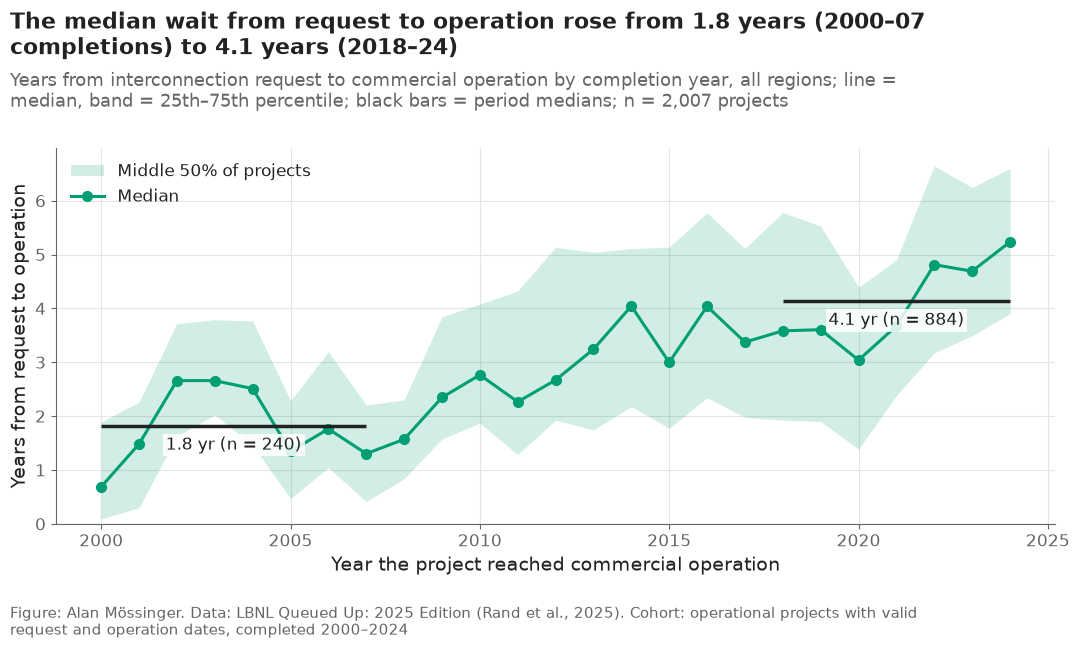

cod_year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
n,10.00,20.00,26.00,21.00,27.00,25.00,52.00,59.00,76.00,55.00,73.00,84.00,93.00,70.00,80.00,123.00,128.00,101.00,101.00,90.00,134.00,150.00,102.00,138.00,169.00
median,0.69,1.48,2.66,2.66,2.51,1.34,1.76,1.30,1.57,2.35,2.77,2.27,2.67,3.24,4.04,3.00,4.04,3.37,3.58,3.60,3.04,3.67,4.81,4.69,5.23
q25,0.09,0.30,1.63,2.02,1.46,0.47,1.04,0.41,0.84,1.58,1.87,1.29,1.92,1.75,2.18,1.78,2.34,1.98,1.92,1.90,1.39,2.38,3.17,3.49,3.90
q75,1.89,2.26,3.72,3.79,3.77,2.29,3.19,2.21,2.30,3.84,4.08,4.32,5.13,5.04,5.11,5.14,5.78,5.11,5.78,5.53,4.39,4.90,6.65,6.25,6.60


In [14]:
ir = audit_queue.ir_to_cod_years(dated)
cod = (ir[ir["cod_year"].between(2000, 2024)].groupby("cod_year")["years"]
       .agg(n="size", median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75)))
cod.to_csv(paths.RESULTS / "ir_to_cod_by_year.csv")
early = ir.loc[ir["cod_year"].between(2000, 2007), "years"]
late = ir.loc[ir["cod_year"].between(2018, 2024), "years"]

fig, ax = plt.subplots()
ax.fill_between(cod.index, cod["q25"], cod["q75"], color=config.OUTCOME_COLORS["operation"],
                alpha=0.18, linewidth=0, label="Middle 50% of projects")
ax.plot(cod.index, cod["median"], color=config.OUTCOME_COLORS["operation"], marker="o",
        label="Median")
for span, values in [((2000, 2007), early), ((2018, 2024), late)]:
    ax.hlines(values.median(), *span, color=plots.INK, linewidth=2.5)
    ax.text(np.mean(span), values.median() - 0.2, f"{values.median():.1f} yr (n = {len(values):,})",
            ha="center", va="top", fontsize=12,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2})
ax.set_xlabel("Year the project reached commercial operation")
ax.set_ylabel("Years from request to operation")
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plots.finish(fig,
             f"The median wait from request to operation rose from {early.median():.1f} years "
             f"(2000–07 completions) to {late.median():.1f} years (2018–24)",
             "Years from interconnection request to commercial operation by completion year, all regions; "
             "line = median, band = 25th–75th percentile; black bars = period medians; "
             f"n = {int(cod['n'].sum()):,} projects",
             "operational projects with valid request and operation dates, completed 2000–2024")
save(fig, "01_07_ir_to_cod_by_year",
     "Median and interquartile range of years from interconnection request to commercial operation, "
     "by year of operation, all regions.")
plt.show()
cod.round(2).T

**Reading this.** The median time from request to commercial operation went from 1.82 years for projects completed in 2000–07 (n = 240) to 4.14 years for those completed in 2018–24 (n = 884), which reproduces LBNL's "more than doubled, to over four years". The upper quartile reached 6.65 years for 2022 completions. Two caveats: this looks only at projects that finished, so slow projects still waiting are missing (survivorship), and it pools all regions, but operation dates exist mainly in the three Track A ISOs (01_02), so it is dominated by them.

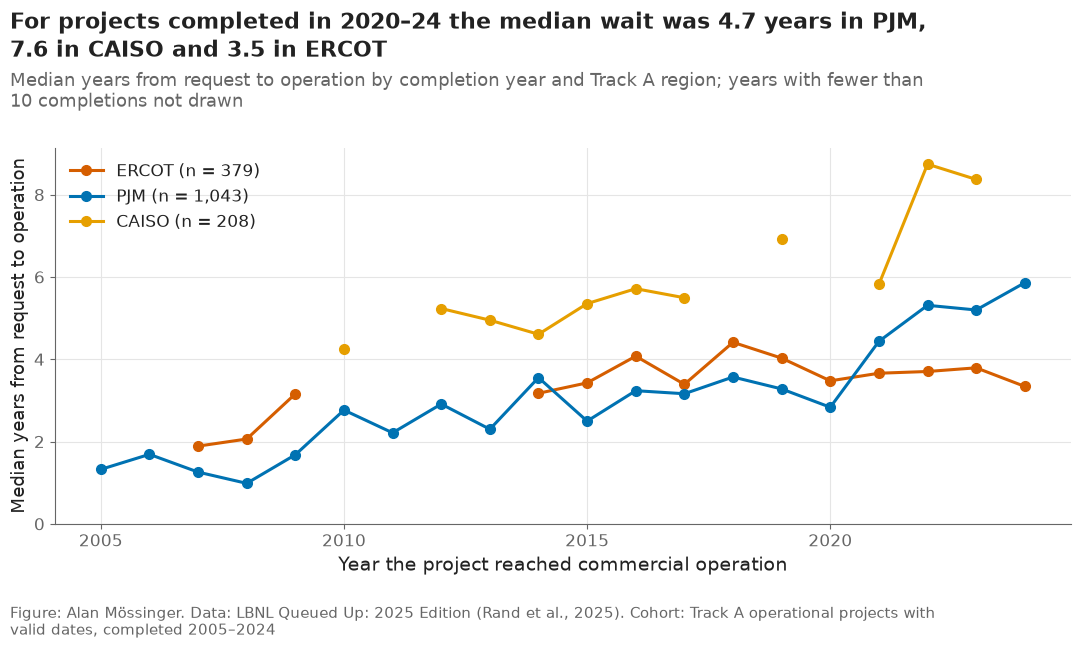

,ERCOT,PJM,CAISO
"median years, completed 2020–24",3.54,4.72,7.59


In [15]:
recent = {}
fig, ax = plt.subplots()
for region in TRACK_A:
    part = ir[(ir["region"] == region) & ir["cod_year"].between(2005, 2024)]
    series = part.groupby("cod_year")["years"].agg(["median", "size"]).reindex(range(2005, 2025))
    # medians of fewer than 10 projects are too noisy to plot; the gap is left visible
    series.loc[~(series["size"] >= 10), "median"] = np.nan
    ax.plot(series.index, series["median"], color=plots.region_color(region), marker="o",
            label=f"{region} (n = {len(part):,})")
    recent[region] = part.loc[part["cod_year"].between(2020, 2024), "years"].median()
year_ticks(ax, 2005, 2024)
ax.set_xlabel("Year the project reached commercial operation")
ax.set_ylabel("Median years from request to operation")
ax.set_ylim(0, None)
ax.legend(loc="upper left")
plots.finish(fig,
             f"For projects completed in 2020–24 the median wait was {recent['PJM']:.1f} years in PJM, "
             f"{recent['CAISO']:.1f} in CAISO and {recent['ERCOT']:.1f} in ERCOT",
             "Median years from request to operation by completion year and Track A region; "
             "years with fewer than 10 completions not drawn",
             "Track A operational projects with valid dates, completed 2005–2024")
save(fig, "01_08_ir_to_cod_by_region",
     "Median years from request to commercial operation by completion year for CAISO, ERCOT and PJM.")
plt.show()
pd.Series(recent, name="median years, completed 2020–24").round(2).to_frame().T

**Reading this.** For projects completed in 2020–24 the median wait was 7.59 years in CAISO, 4.72 in PJM and 3.54 in ERCOT. ERCOT's median has stayed in a narrow band since 2014 while PJM's climbed after 2020, and CAISO's has been the longest throughout. For a lender this is the practical point: the region alone moves a realistic COD assumption by about four years, so a single national figure is not a usable assumption. The survivorship caveat of 01_07 applies, and CAISO's yearly medians rest on few projects (gaps mark years with fewer than 10 completions).

### 3.8 The naive mock-up: five-year completion by region

Share of 2010–2018 generation entrants that reached operation within five
years of their request, with 95% Wilson intervals. This is the "cohort
average" a developer would use today, and the plan expects CAISO ≈ 4%,
ERCOT ≈ 21%, PJM ≈ 15%.

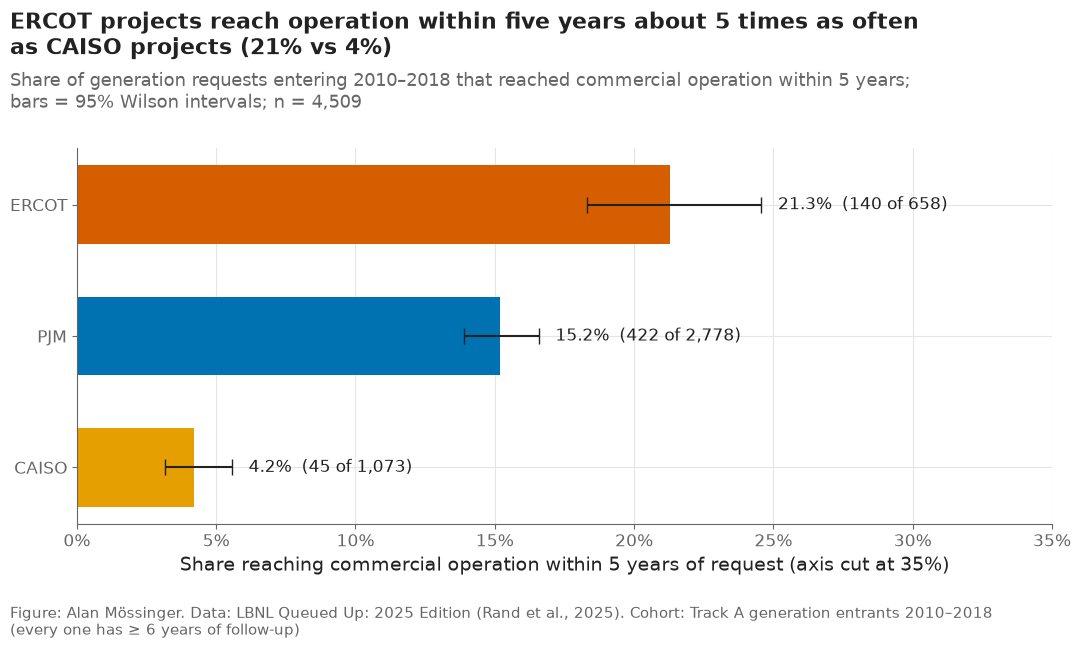

,region,n,completed,share,ci_low,ci_high
0,ERCOT,658,140,0.2128,0.1832,0.2457
1,PJM,2778,422,0.1519,0.1390,0.1657
2,CAISO,1073,45,0.0419,0.0315,0.0557


In [16]:
mock = audit_queue.five_year_completion(dated)
mock.to_csv(paths.RESULTS / "naive_mockup.csv", index=False)
mock_shares = mock.set_index("region")["share"]

fig, ax = plt.subplots()
order = mock.sort_values("share")
for i, row in enumerate(order.itertuples()):
    ax.barh(i, row.share, color=plots.region_color(row.region), height=0.6)
    ax.errorbar(row.share, i, xerr=[[row.share - row.ci_low], [row.ci_high - row.share]],
                color=plots.INK, capsize=6, linewidth=1.5)
    ax.text(row.ci_high + 0.006, i, f"{row.share:.1%}  ({row.completed} of {row.n:,})",
            va="center", fontsize=12)
ax.set_yticks(range(len(order)), order["region"])
ax.set_xlim(0, 0.35)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share reaching commercial operation within 5 years of request (axis cut at 35%)")
ratio = mock_shares["ERCOT"] / mock_shares["CAISO"]
plots.finish(fig,
             f"ERCOT projects reach operation within five years about {ratio:.0f} times as often as "
             f"CAISO projects ({mock_shares['ERCOT']:.0%} vs {mock_shares['CAISO']:.0%})",
             "Share of generation requests entering 2010–2018 that reached commercial operation within "
             f"5 years; bars = 95% Wilson intervals; n = {mock['n'].sum():,}",
             "Track A generation entrants 2010–2018 (every one has ≥ 6 years of follow-up)")
save(fig, "01_09_naive_five_year_completion",
     "Naive five-year completion share for 2010–2018 generation entrants in CAISO, ERCOT and PJM, "
     "with 95% Wilson intervals.")
plt.show()
mock.round(4)

**Reading this.** Of the 2010–2018 generation entrants, 21.3% reached operation within five years in ERCOT (140 of 658), 15.2% in PJM (422 of 2,778) and 4.2% in CAISO (45 of 1,073); the 95% intervals do not overlap. This reproduces the plan's 21% / 15% / 4% to within 0.3 points. It is the simplest version of the baseline the models must beat and already shows why a national average would be a straw man. Every entrant in this window has at least six years of follow-up before the censor date, so the naive share is not biased by censoring at five years. The real baseline in notebook 05 is finer (region × technology).

### 3.9 The Track A sample and the held-out test cohort

How many projects can enter the three-ISO timing model, and how many events
the 2017–2019 test cohort holds by the censor date (2024-12-31).

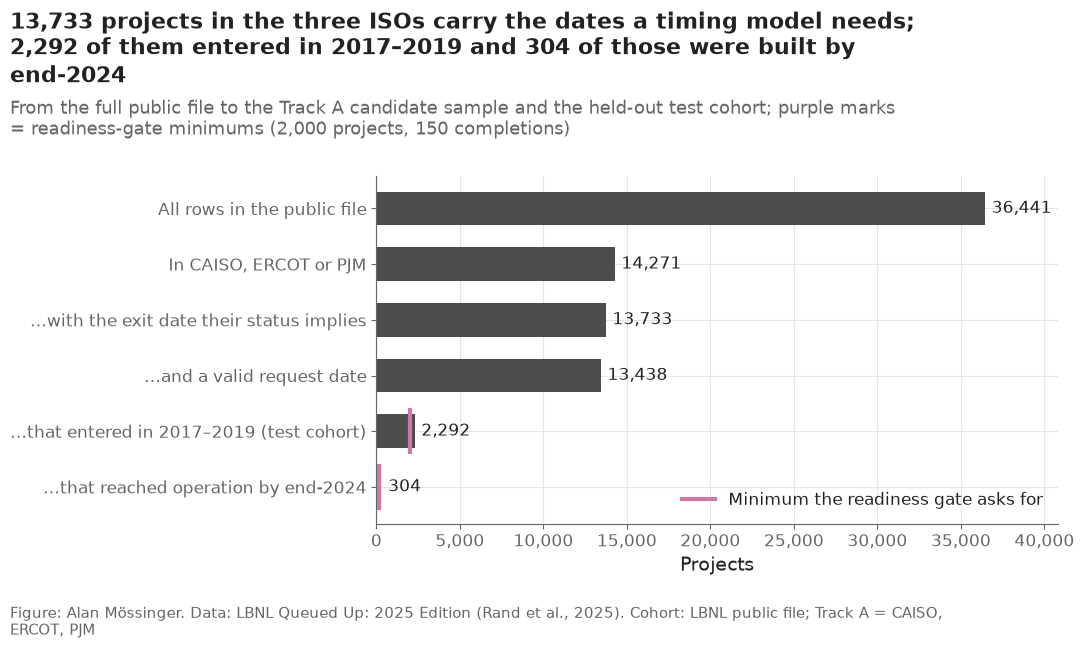

{'projects': 2292, 'completions': 304, 'withdrawals': 1358}
All Track A rows entering 2017–2019, whatever their dates: 2313


excluded rows
region q_status                  
CAISO  operational             11
       withdrawn              342
ERCOT  operational              8
PJM    operational             26
       withdrawn              151

In [17]:
in_region = dated["region"].isin(TRACK_A)
candidates = audit_queue.track_a_candidates(dated)
held_out = audit_queue.held_out_cohort_events(dated, candidates)
steps = pd.Series({
    "All rows in the public file": len(dated),
    "In CAISO, ERCOT or PJM": int(in_region.sum()),
    "…with the exit date their status implies": int(candidates.sum()),
    "…and a valid request date": int((candidates & dated["q_date_valid"]).sum()),
    "…that entered in 2017–2019 (test cohort)": held_out["projects"],
    "…that reached operation by end-2024": held_out["completions"],
})
excluded = (in_region & ~candidates)
exclusions = dated[excluded].groupby(["region", "q_status"]).size().rename("excluded rows")

fig, ax = plt.subplots()
ypos = np.arange(len(steps))[::-1]
ax.barh(ypos, steps.values, color="#4D4D4D", height=0.6)
minimums = {4: config.TEST_MIN_PROJECTS, 5: config.TEST_MIN_COMPLETIONS}
for i, (y, value) in enumerate(zip(ypos, steps.values)):
    ax.text(max(value, minimums.get(i, 0)) + 400, y, f"{value:,}", va="center", fontsize=12)
for i, minimum in minimums.items():
    ax.plot([minimum, minimum], [ypos[i] - 0.38, ypos[i] + 0.38],
            color=config.OUTCOME_COLORS["withdrawal"], linewidth=3)
ax.set_yticks(ypos, steps.index)
ax.set_xlim(0, len(dated) * 1.12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.set_xlabel("Projects")
ax.legend(handles=[Line2D([], [], color=config.OUTCOME_COLORS["withdrawal"], linewidth=3,
                          label="Minimum the readiness gate asks for")], loc="lower right")
plots.finish(fig,
             f"{steps.iloc[2]:,} projects in the three ISOs carry the dates a timing model needs; "
             f"{held_out['projects']:,} of them entered in 2017–2019 and {held_out['completions']} "
             "of those were built by end-2024",
             "From the full public file to the Track A candidate sample and the held-out test cohort; "
             f"purple marks = readiness-gate minimums ({config.TEST_MIN_PROJECTS:,} projects, "
             f"{config.TEST_MIN_COMPLETIONS} completions)",
             "LBNL public file; Track A = CAISO, ERCOT, PJM")
save(fig, "01_10_track_a_sample_flow",
     "Row counts from the full public file to the Track A candidate sample and the 2017–2019 test "
     "cohort, with the readiness-gate minimums.")
plt.show()
print(held_out)
print("All Track A rows entering 2017–2019, whatever their dates:",
      int((in_region & dated["q_date"].dt.year.between(*config.TEST_YEARS)).sum()))
exclusions.to_frame()

**Reading this.** 13,733 projects in the three ISOs carry the exit date their status implies (inside the expected 13,500–14,500); 13,438 of them also have a valid request date, which notebook 04 needs. The exclusions are concentrated in CAISO (342 withdrawn rows without a withdrawal date, 11 operational rows without an operation date) and PJM (151 and 26); ERCOT loses 8 operational rows. The 2017–2019 test cohort holds 2,292 projects with 304 completions and 1,358 withdrawals by the end of 2024. The 304 completions are twice the 150 the gate asks for. The plan's original minimum of 2,500 projects could not be met by any definition of the sample — the three ISOs contain only 2,313 rows that entered in 2017–2019 at all — so Alan lowered it to 2,000 after the first evaluation (decision #15).

### 3.10 More of the first look

Six more views that later notebooks build on: project size (the FERC 20 MW
step), what is still waiting, how fast withdrawn projects leave, developers'
proposed timelines, how late completed projects were, and the rise of
hybrids.

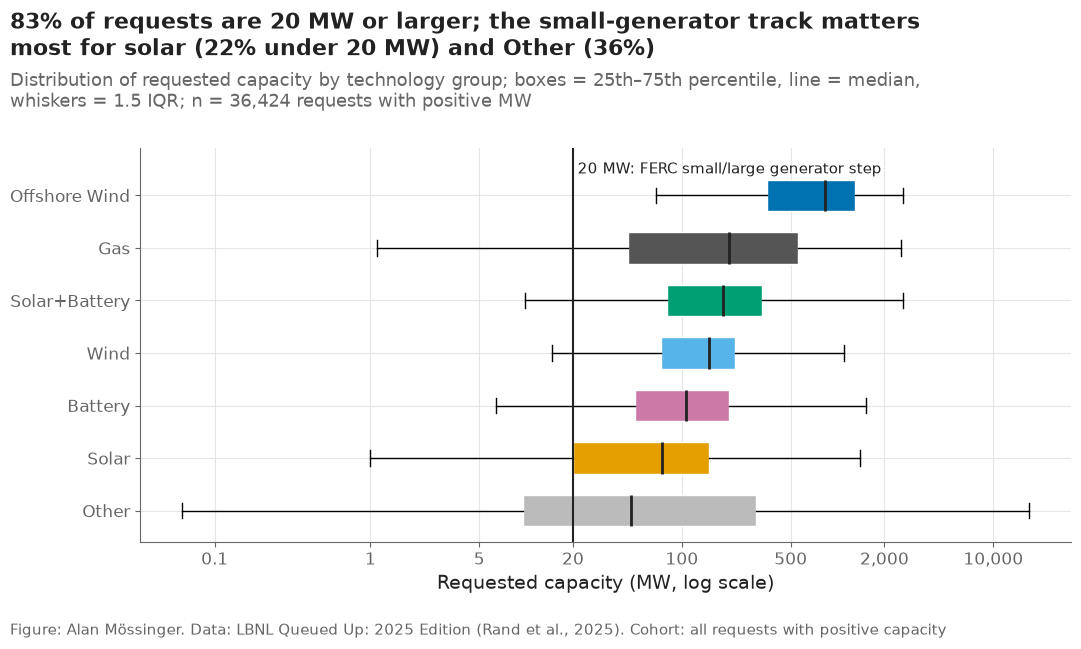

tech_group,Battery,Gas,Offshore Wind,Other,Solar,Solar+Battery,Wind
share >= 20 MW,0.908,0.843,0.953,0.637,0.777,0.92,0.904


In [18]:
sized = dated[dated["mw"] > 0]
groups = sized.groupby("tech_group")["mw"].median().sort_values().index
large_share = (sized["mw"] >= config.FERC_SIZE_STEP_MW).groupby(sized["tech_group"]).mean()

fig, ax = plt.subplots()
box = ax.boxplot([np.log10(sized.loc[sized["tech_group"] == g, "mw"]) for g in groups],
                 orientation="horizontal", tick_labels=groups, showfliers=False, widths=0.6,
                 patch_artist=True, medianprops={"color": plots.INK, "linewidth": 2})
for patch, group in zip(box["boxes"], groups):
    patch.set_facecolor(config.TECH_COLORS[group])
    patch.set_edgecolor("white")
ax.axvline(np.log10(config.FERC_SIZE_STEP_MW), color=plots.INK, linewidth=1.5)
ax.text(np.log10(config.FERC_SIZE_STEP_MW) + 0.03, len(groups) + 0.35,
        "20 MW: FERC small/large generator step", fontsize=11, va="bottom")
ticks = [0.1, 1, 5, 20, 100, 500, 2000, 10000]
ax.set_xticks(np.log10(ticks), [f"{t:,}" for t in ticks])
ax.set_xlabel("Requested capacity (MW, log scale)")
ax.set_ylim(0.4, len(groups) + 0.9)
small_share = 1 - large_share
plots.finish(fig,
             f"{(sized['mw'] >= 20).mean():.0%} of requests are 20 MW or larger; the small-generator "
             f"track matters most for solar ({small_share['Solar']:.0%} under 20 MW) and "
             f"Other ({small_share['Other']:.0%})",
             "Distribution of requested capacity by technology group; boxes = 25th–75th percentile, "
             f"line = median, whiskers = 1.5 IQR; n = {len(sized):,} requests with positive MW",
             "all requests with positive capacity")
save(fig, "01_11_size_by_technology",
     "Distribution of requested capacity (MW, log scale) by technology group with the 20 MW FERC "
     "small/large generator threshold.")
plt.show()
large_share.round(3).to_frame("share >= 20 MW").T

**Reading this.** 83% of requests are 20 MW or larger. The share at or above 20 MW is lowest for Other (63.7%) and solar (77.7%) and highest for offshore wind (95.3%). Solar's box starts exactly at 20 MW, a hint that requests bunch at the FERC small/large-generator threshold; F3 in notebook 03 will test whether completion actually changes at that step. The `size_regime` bins of notebook 04 are built around the same 20 MW line.

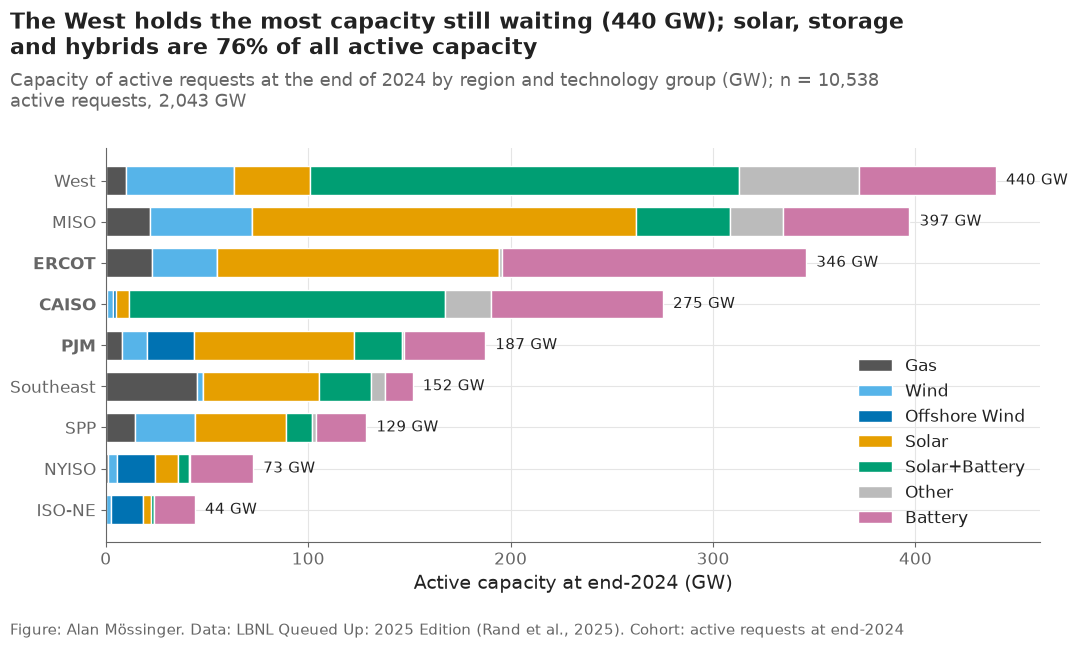

tech_group,Gas,Wind,Offshore Wind,Solar,Solar+Battery,Other,Battery
region,,,,,,,
ISO-NE,0.0,3.0,16.0,4.0,2.0,0.0,20.0
NYISO,1.0,4.0,19.0,12.0,5.0,0.0,31.0
SPP,14.0,30.0,0.0,45.0,12.0,2.0,25.0
Southeast,45.0,3.0,0.0,57.0,26.0,7.0,14.0
PJM,8.0,13.0,23.0,79.0,24.0,1.0,40.0
CAISO,1.0,3.0,1.0,7.0,156.0,22.0,85.0
ERCOT,23.0,32.0,0.0,139.0,0.0,1.0,150.0
MISO,22.0,50.0,0.0,190.0,47.0,26.0,63.0
West,10.0,53.0,0.0,38.0,212.0,59.0,67.0


In [19]:
active = dated[dated["q_status"] == "active"]
active_gw = (active.groupby(["region", "tech_group"])["mw"].sum().unstack()
             .reindex(columns=stack_order).fillna(0) / 1000)
active_gw = active_gw.loc[active_gw.sum(axis=1).sort_values().index]

fig, ax = plt.subplots()
left = np.zeros(len(active_gw))
for group in stack_order:
    ax.barh(active_gw.index, active_gw[group], left=left, color=config.TECH_COLORS[group],
            height=0.7, label=group, edgecolor="white", linewidth=1)
    left += active_gw[group].values
for i, total in enumerate(active_gw.sum(axis=1)):
    ax.text(total + 5, i, f"{total:,.0f} GW", va="center", fontsize=11)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlabel("Active capacity at end-2024 (GW)")
ax.legend(loc="lower right")
solar_storage = active_gw[["Solar", "Solar+Battery", "Battery"]].sum().sum() / active_gw.sum().sum()
plots.finish(fig,
             f"{region_name(active_gw.sum(axis=1).idxmax())[0].upper()}"
             f"{region_name(active_gw.sum(axis=1).idxmax())[1:]} holds the most capacity still waiting "
             f"({active_gw.sum(axis=1).max():,.0f} GW); solar, storage and hybrids are "
             f"{solar_storage:.0%} of all active capacity",
             "Capacity of active requests at the end of 2024 by region and technology group (GW); "
             f"n = {len(active):,} active requests, {active['mw'].sum() / 1000:,.0f} GW",
             "active requests at end-2024")
save(fig, "01_12_active_capacity_region_technology",
     "Capacity of requests still active at the end of 2024 by region and technology group (GW).")
plt.show()
active_gw.round(0)

**Reading this.** At the end of 2024 the public file holds 2,043 GW in 10,538 active requests (summed over all resource types, so hybrid storage counts on top of the generator; LBNL's report splits generation and storage differently). The West has the most (440 GW), and solar, storage and hybrids make up 76% of all active capacity. ERCOT shows 0.0 GW of solar+battery, which matches figure 01_16: ERCOT's queue in this file records no hybrids, presumably listing the solar and storage parts as separate requests. That makes the hybrid flag uninformative inside ERCOT.

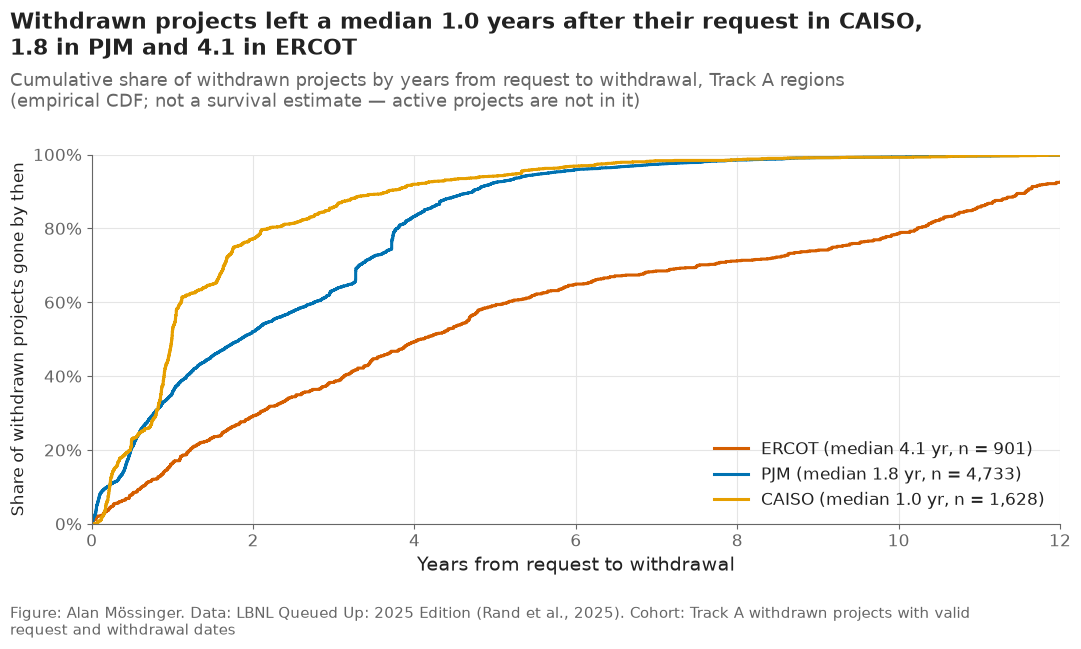

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
CAISO,1628.0,1.59,1.73,0.0,0.62,0.99,1.77,13.49
ERCOT,901.0,5.27,4.18,0.0,1.66,4.08,9.24,20.14
PJM,4733.0,2.31,2.02,0.0,0.60,1.84,3.72,21.53


In [20]:
def ecdf(values):
    """Sorted values and their cumulative shares, for a step plot."""
    x = np.sort(np.asarray(values))
    return x, np.arange(1, len(x) + 1) / len(x)


wd = dated[(dated["q_status"] == "withdrawn") & in_region & dated["q_date_valid"]
           & dated["wd_date"].notna() & (dated["wd_date"] >= dated["q_date"])]
wd_years = (wd["wd_date"] - wd["q_date"]).dt.days / config.DAYS_PER_YEAR
wd_medians = wd_years.groupby(wd["region"]).median()

fig, ax = plt.subplots()
for region in TRACK_A:
    x, y = ecdf(wd_years[wd["region"] == region])
    ax.step(x, y, where="post", color=plots.region_color(region),
            label=f"{region} (median {wd_medians[region]:.1f} yr, n = {len(x):,})")
ax.set_xlim(0, 12)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Years from request to withdrawal")
ax.set_ylabel("Share of withdrawn projects gone by then")
ax.legend(loc="lower right")
plots.finish(fig,
             f"Withdrawn projects left a median {wd_medians['CAISO']:.1f} years after their request in "
             f"CAISO, {wd_medians['PJM']:.1f} in PJM and {wd_medians['ERCOT']:.1f} in ERCOT",
             "Cumulative share of withdrawn projects by years from request to withdrawal, Track A regions "
             "(empirical CDF; not a survival estimate — active projects are not in it)",
             "Track A withdrawn projects with valid request and withdrawal dates")
save(fig, "01_13_time_to_withdrawal",
     "Empirical cumulative distribution of years from request to withdrawal for withdrawn projects in "
     "CAISO, ERCOT and PJM.")
plt.show()
wd_years.groupby(wd["region"]).describe().round(2)

**Reading this.** Withdrawn projects left a median 0.99 years after their request in CAISO, 1.84 in PJM and 4.08 in ERCOT; in ERCOT a quarter of them stayed more than 9.24 years before leaving. In CAISO and PJM, projects that fail tend to fail early (three quarters were gone within 1.77 and 3.72 years). PJM's curve has visible steps between three and four years — many projects leaving at once — which a discrete-time model with a free year-in-queue effect can represent better than a smooth hazard. This is not a survival estimate: it only describes projects that did withdraw. Notebook 03 estimates the cumulative incidence of withdrawal properly, with active projects censored. **Correction from notebook 03:** 441 of ERCOT's withdrawals share one recorded date, 2018-08-29, and none is dated earlier, so ERCOT's long times to withdrawal here are mostly that bulk date, not slow withdrawals (figure 03_10).

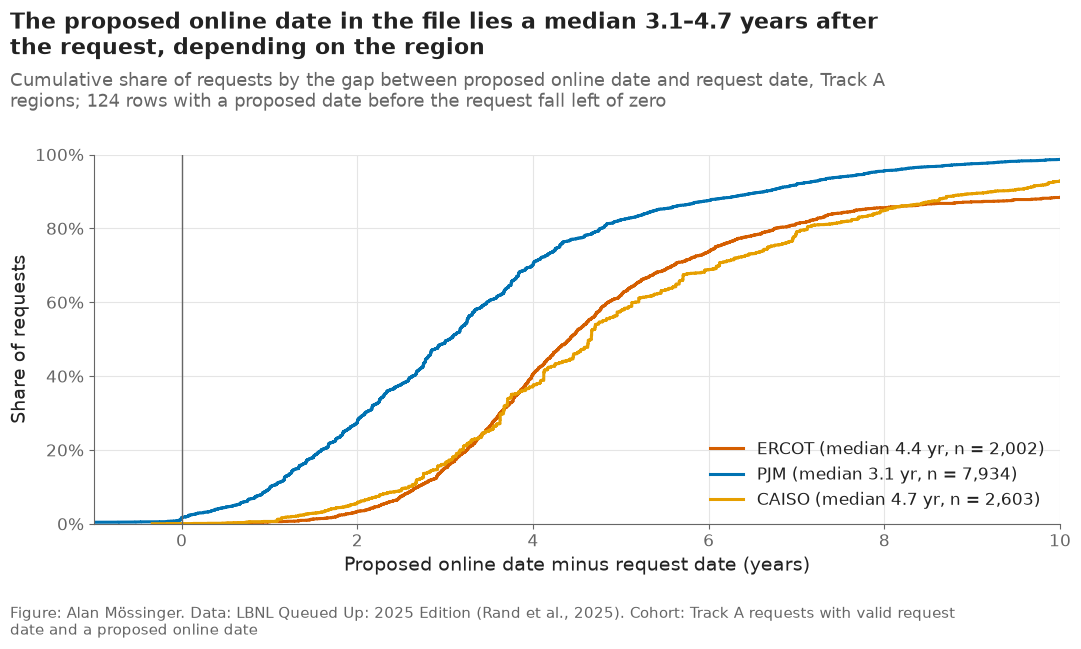

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
CAISO,2603.0,5.32,2.83,-0.33,3.46,4.66,6.69,23.60
ERCOT,2002.0,8.80,12.38,0.32,3.46,4.42,6.08,49.32
PJM,7934.0,3.38,2.37,-26.04,1.84,3.05,4.30,17.95


In [21]:
amb = dated[in_region & dated["q_date_valid"] & dated["prop_date"].notna()]
amb_years = (amb["prop_date"] - amb["q_date"]).dt.days / config.DAYS_PER_YEAR
amb_medians = amb_years.groupby(amb["region"]).median()

fig, ax = plt.subplots()
for region in TRACK_A:
    x, y = ecdf(amb_years[amb["region"] == region])
    ax.step(x, y, where="post", color=plots.region_color(region),
            label=f"{region} (median {amb_medians[region]:.1f} yr, n = {len(x):,})")
ax.axvline(0, color=plots.MUTED, linewidth=1)
ax.set_xlim(-1, 10)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Proposed online date minus request date (years)")
ax.set_ylabel("Share of requests")
ax.legend(loc="lower right")
plots.finish(fig,
             f"The proposed online date in the file lies a median {amb_medians.min():.1f}–"
             f"{amb_medians.max():.1f} years after the request, depending on the region",
             "Cumulative share of requests by the gap between proposed online date and request date, "
             f"Track A regions; {(amb_years < 0).sum():,} rows with a proposed date before the request "
             "fall left of zero",
             "Track A requests with valid request date and a proposed online date")
save(fig, "01_14_proposed_timeline",
     "Distribution of the gap between the proposed online date and the request date (years) in CAISO, "
     "ERCOT and PJM.")
plt.show()
amb_years.groupby(amb["region"]).describe().round(2)

**Reading this.** The stored proposed online date lies a median 3.05 years after the request in PJM, 4.42 in ERCOT and 4.66 in CAISO. The tails contain impossible values (ERCOT up to 49.3 years; PJM down to −26.0 years) that need a cleaning rule. More important is the next figure: the stored date does not look like the proposal made at entry, so the planned "ambition gap" feature may not be an entry-time feature at all.

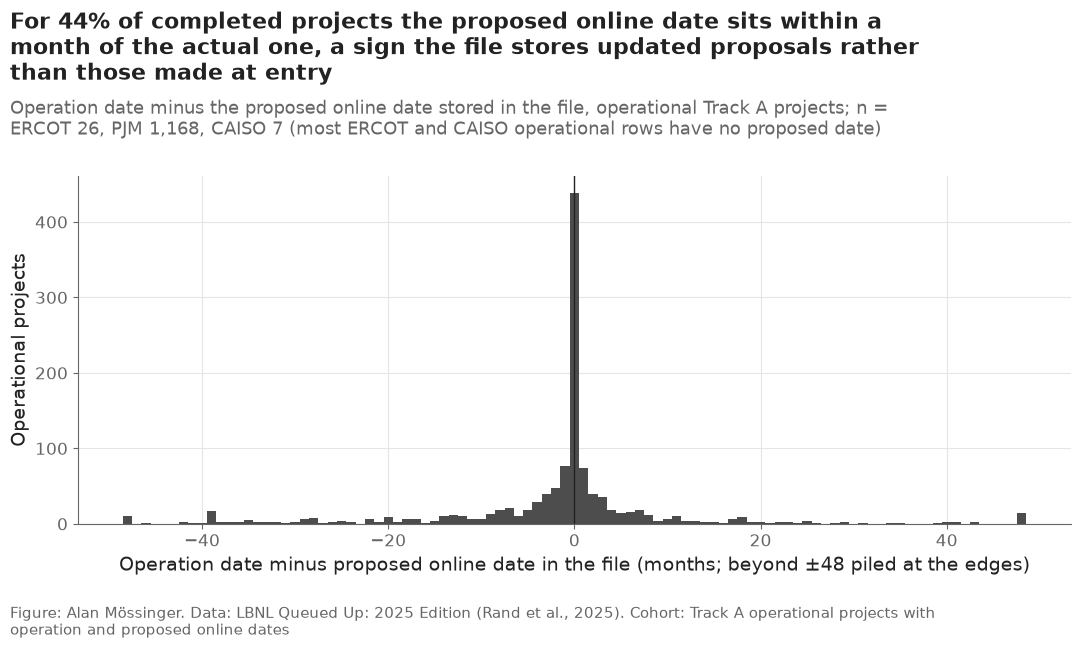

Operational rows with a proposed date, by region: {'CAISO': 0.032, 'ERCOT': 0.054, 'PJM': 0.999}


region,CAISO,ERCOT,PJM
share within ±1 month,0.286,0.769,0.434


In [22]:
operational = dated[in_region & (dated["q_status"] == "operational") & dated["on_date"].notna()]
built = operational[operational["prop_date"].notna()]
delay_months = (built["on_date"] - built["prop_date"]).dt.days / (config.DAYS_PER_YEAR / 12)
same_month = (delay_months.abs() <= 1).mean()

fig, ax = plt.subplots()
ax.hist(delay_months.clip(-48, 48), bins=np.arange(-48.5, 49.5, 1), color="#4D4D4D")
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_xlabel("Operation date minus proposed online date in the file (months; beyond ±48 piled at the edges)")
ax.set_ylabel("Operational projects")
n_by_region = built["region"].value_counts().reindex(TRACK_A).fillna(0).astype(int)
plots.finish(fig,
             f"For {same_month:.0%} of completed projects the proposed online date sits within a month "
             "of the actual one, a sign the file stores updated proposals rather than those made at entry",
             "Operation date minus the proposed online date stored in the file, operational Track A "
             "projects; n = " + ", ".join(f"{r} {n:,}" for r, n in n_by_region.items())
             + " (most ERCOT and CAISO operational rows have no proposed date)",
             "Track A operational projects with operation and proposed online dates")
save(fig, "01_15_proposed_vs_actual_online_date",
     "Months between the actual operation date and the proposed online date recorded in the LBNL file "
     "for completed projects in CAISO, ERCOT and PJM.")
plt.show()
print("Operational rows with a proposed date, by region:",
      (operational.groupby("region")["prop_date"].apply(lambda s: s.notna().mean())).round(3).to_dict())
(delay_months.groupby(built["region"]).apply(lambda s: (s.abs() <= 1).mean())).round(3).to_frame(
    "share within ±1 month").T

**Reading this.** For PJM, 43.4% of completed projects (n = 1,168) have a proposed online date within one month of their actual operation date; pooled over the three ISOs it is 44%. A proposal made years before completion would rarely land within a month of the real date, so the spike at zero suggests the queues overwrite the proposed date as a project advances. The coverage pattern points the same way: 99.9% of PJM's operational rows carry a proposed date but only 5.4% of ERCOT's and 3.2% of CAISO's, as if the field were cleared on completion there. ERCOT (n = 26) and CAISO (n = 7) are too small to read on their own. Consequence for notebook 04: `ambition_gap_years` built from this field risks leaking post-entry information. Unless an entry-time snapshot of the proposed date is available (for example from earlier LBNL releases), I would keep it out of the main models and test it only in the leakage ablation — **ASK ALAN**.

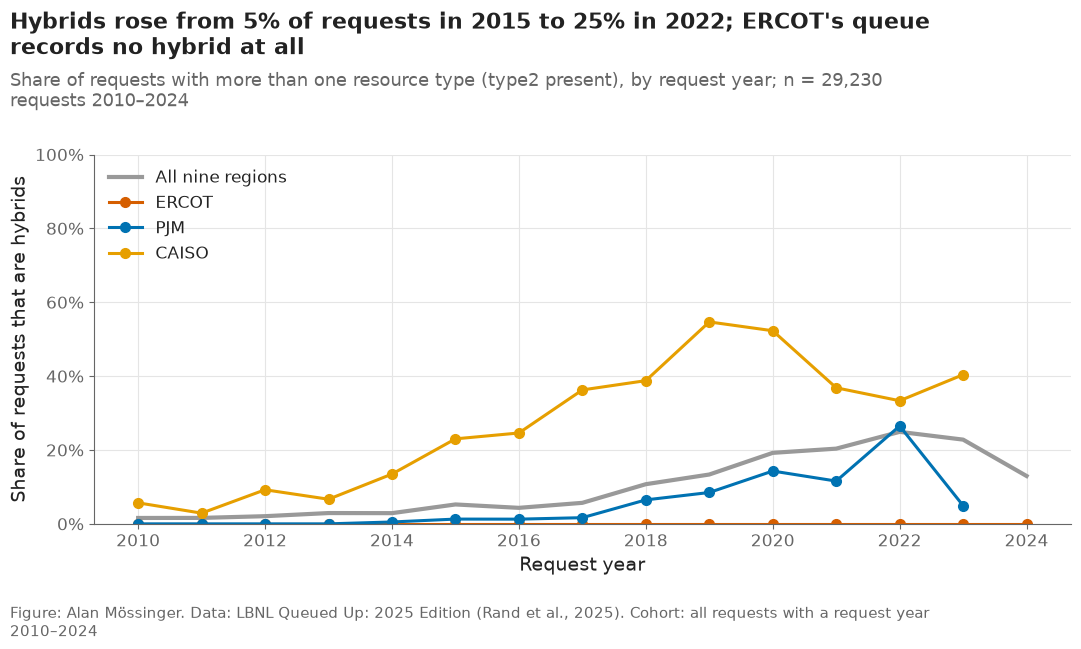

q_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
CAISO,5.7,2.9,9.2,6.7,13.5,23.0,24.6,36.3,38.8,54.7,52.3,36.8,33.3,40.4,NaN
ERCOT,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ISO-NE,11.1,18.2,0.0,37.5,25.6,27.1,23.3,14.8,8.6,11.3,25.9,30.0,38.3,10.4,11.6
MISO,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.9,7.2,13.8,22.1,45.5,11.7
NYISO,0.0,11.1,6.2,28.6,0.0,2.4,0.0,0.0,1.9,0.6,6.1,13.8,10.4,9.6,9.8
PJM,0.0,0.0,0.0,0.0,0.5,1.3,1.3,1.7,6.5,8.5,14.3,11.6,26.5,4.9,NaN
SPP,0.0,0.0,0.0,4.7,0.0,0.0,0.0,0.4,0.7,3.8,17.5,19.1,4.3,14.0,7.3
Southeast,4.3,5.3,0.0,3.1,0.0,0.0,0.4,0.9,3.0,11.1,23.1,31.4,17.2,10.8,8.4
West,1.1,1.5,3.2,2.1,1.8,3.3,7.9,13.6,30.4,32.5,43.9,41.2,44.8,48.3,38.1
All,1.6,1.6,2.1,2.9,2.9,5.3,4.3,5.7,10.7,13.4,19.2,20.4,24.9,22.8,13.0


In [23]:
recent_years = range(2010, 2025)
hyb = dated[dated["q_year"].between(2010, 2024)].assign(hybrid=lambda t: t["type2"].notna())
hyb_region = hyb.groupby(["q_year", "region"])["hybrid"].mean().unstack().reindex(recent_years)
hyb_all = hyb.groupby("q_year")["hybrid"].mean().reindex(recent_years)

fig, ax = plt.subplots()
ax.plot(hyb_all.index, hyb_all.values, color=config.OTHER_REGION_COLOR, linewidth=3,
        label="All nine regions")
for region in TRACK_A:
    ax.plot(hyb_region.index, hyb_region[region], color=plots.region_color(region), marker="o",
            label=region)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share of requests that are hybrids")
ax.legend(loc="upper left")
plots.finish(fig,
             f"Hybrids rose from {hyb_all[2015]:.0%} of requests in 2015 to {hyb_all.max():.0%} in "
             f"{hyb_all.idxmax()}; ERCOT's queue records no hybrid at all",
             "Share of requests with more than one resource type (type2 present), by request year; "
             f"n = {len(hyb):,} requests 2010–2024",
             "all requests with a request year 2010–2024")
save(fig, "01_16_hybrid_share",
     "Share of interconnection requests that combine more than one resource type, by request year, "
     "nationally and for CAISO, ERCOT and PJM.")
plt.show()
(100 * hyb_region.join(hyb_all.rename("All"))).round(1).T

**Reading this.** Hybrids rose from 5.3% of requests in 2015 to 24.9% in 2022 and fell back to 13.0% in 2024. CAISO peaked at 54.7% in 2019. ERCOT shows 0.0% in every year: its queue in the public file does not record hybrid composition, so the hybrid flag can only be learned from the other regions. In the region-stratified Cox model this is harmless; in pooled models it means the hybrid effect is estimated from CAISO and PJM.

## 4. EIA-860M through the EIA API (source S2)

The route metadata gives the latest month; `eia_api.pull_generators()` then
pages through it 5,000 rows at a time, saves each page as returned and the
combined table as parquet. If those files exist the cell reads them instead of
calling the API (the cache that makes a second run fast).

In [24]:
meta = eia_api.fetch_route_metadata(eia_key)
period = meta["end_period"]
generators, pull_log = eia_api.pull_generators(period, key=eia_key)

print("Route:", config.EIA_ROUTE)
print("Months served:", meta["start_period"], "to", period)
print("Pull:", pull_log)
print("Rows received equal the API total:", pull_log["rows"] == pull_log["total"])
print("Duplicate plant-generator keys:", int(generators.duplicated(["plantid", "generatorid"]).sum()))
generators["status"].value_counts().to_frame("generators")

Route: electricity/operating-generator-capacity
Months served: 2008-01 to 2026-07
Pull: {'period': '2026-07', 'total': 28324, 'rows': 28324, 'pages': 6, 'from_cache': True}
Rows received equal the API total: True
Duplicate plant-generator keys: 0


,generators
status,
OP,26072
SB,1497
OS,539
OA,216


In [25]:
fields = list(config.EIA_MIN_FIELD_SHARE)
filled = generators[fields].replace("", np.nan).notna()
field_share = pd.DataFrame({
    "all rows": filled.mean(),
    "status OP": filled[generators["status"] == "OP"].mean(),
    "required": pd.Series(config.EIA_MIN_FIELD_SHARE),
})
generators["type_clean"] = generators["technology"].map(
    lambda t: config.EIA_TECHNOLOGY_MAP.get(t, ("Other", ""))[0])
profile = {
    "period": period, "rows": pull_log["rows"], "total": pull_log["total"], "pages": pull_log["pages"],
    "status": {k: int(v) for k, v in generators["status"].value_counts().items()},
    "field_share_all": field_share["all rows"].round(4).to_dict(),
    "field_share_op": field_share["status OP"].round(4).to_dict(),
    "nameplate_gw": round(generators["nameplate-capacity-mw"].sum() / 1000, 1),
}
(paths.RESULTS / "eia860m_profile.json").write_text(json.dumps(profile, indent=2), encoding="utf-8")
field_share.round(4)

,all rows,status OP,required
operating-year-month,1.0,1.0,0.95
stateid,1.0,1.0,0.99
technology,1.0,1.0,0.99
county,1.0,1.0,0.95
latitude,1.0,1.0,0.95
longitude,1.0,1.0,0.95


In [26]:
state_gw = generators.pivot_table(index="stateid", columns="type_clean", values="nameplate-capacity-mw",
                                  aggfunc="sum", fill_value=0) / 1000
state_gw = state_gw.assign(total=state_gw.sum(axis=1)).sort_values("total", ascending=False)
state_gw.head(12).round(1)

type_clean,Battery,Coal,Gas,Geothermal,Hydro,Nuclear,Offshore Wind,Other,Solar,Wind,total
stateid,,,,,,,,,,,
TX,18.3,16.6,84.1,0.0,0.7,5.1,0.0,1.7,33.3,43.9,203.8
CA,16.3,0.1,40.2,2.9,13.7,2.3,0.0,1.9,25.5,6.5,109.4
FL,1.2,3.7,55.3,0.0,0.0,3.9,0.0,3.5,13.3,0.0,81.0
PA,0.0,5.2,29.9,0.0,2.4,10.5,0.0,2.3,1.2,1.7,53.3
IL,0.1,7.4,18.0,0.0,0.0,12.4,0.0,0.9,5.2,8.7,52.8
AZ,6.6,2.8,17.7,0.0,2.9,4.2,0.0,0.2,8.8,1.7,45.0
NY,0.3,0.0,24.2,0.0,5.9,3.4,0.1,4.4,3.2,2.9,44.4
GA,0.3,6.2,18.6,0.0,3.6,6.5,0.0,2.3,5.5,0.0,43.0
NC,0.3,4.4,19.3,0.0,2.0,5.4,0.0,1.1,7.1,0.4,40.0


**Reading this.** The API served months from 2008-01 to 2026-07. The 2026-07 pull returned 28,324 rows in 6 pages — exactly the total the API reported — with no duplicate plant-generator keys (this run read the cached pages; the first run called the API). Status: 26,072 operating, 1,497 standby, 539 out of service, 216 out of service but expected back. Every field the gate needs (operating month, state, technology, county, latitude, longitude) is 100% filled. Texas has the most operable capacity (203.8 GW), then California (109.4 GW).

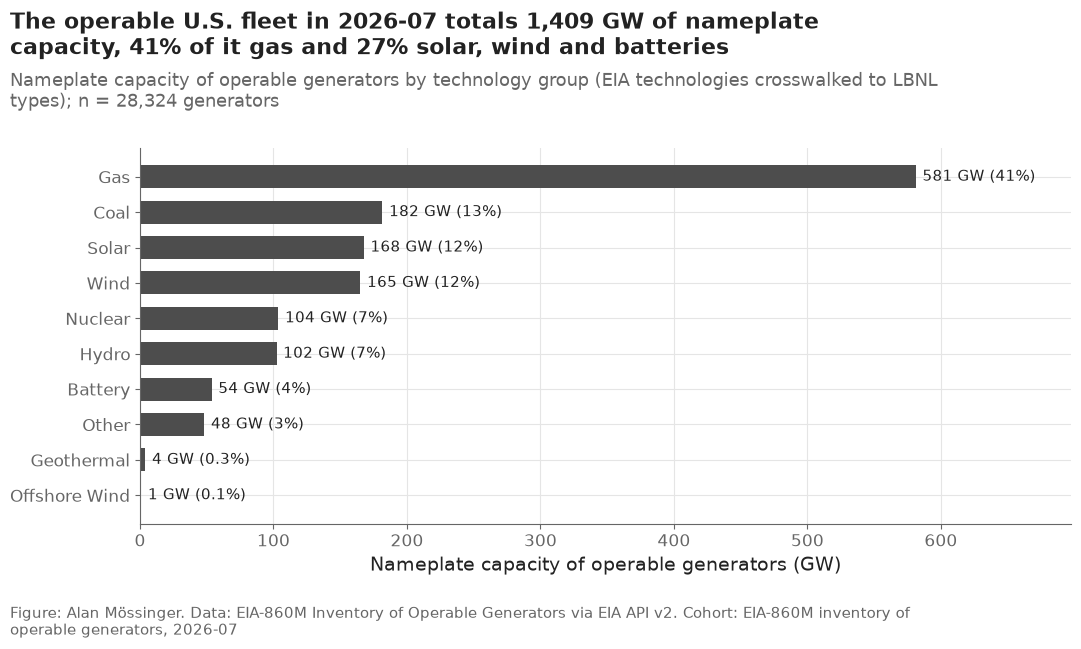

In [27]:
fleet = (generators.groupby("type_clean")["nameplate-capacity-mw"].sum() / 1000).sort_values()
total_gw = fleet.sum()

fig, ax = plt.subplots()
ax.barh(fleet.index, fleet.values, color="#4D4D4D", height=0.65)
for i, value in enumerate(fleet.values):
    share = f"{value / total_gw:.1%}" if value / total_gw < 0.01 else f"{value / total_gw:.0%}"
    ax.text(value + 5, i, f"{value:,.0f} GW ({share})", va="center", fontsize=11)
ax.set_xlabel("Nameplate capacity of operable generators (GW)")
ax.set_xlim(0, fleet.max() * 1.2)
plots.finish(fig,
             f"The operable U.S. fleet in {period} totals {total_gw:,.0f} GW of nameplate capacity, "
             f"{fleet['Gas'] / total_gw:.0%} of it gas and {fleet[['Solar', 'Wind', 'Battery']].sum() / total_gw:.0%} "
             "solar, wind and batteries",
             "Nameplate capacity of operable generators by technology group (EIA technologies crosswalked "
             f"to LBNL types); n = {len(generators):,} generators",
             f"EIA-860M inventory of operable generators, {period}", eia=True, lbnl=False)
save(fig, "01_17_eia_fleet_by_technology",
     "Nameplate capacity of all operable U.S. generators by technology group, from EIA-860M.")
plt.show()

**Reading this.** The operable fleet in 2026-07 has 1,409 GW of nameplate capacity: 41% gas, and 27% solar, wind and batteries together. Batteries are 53.7 GW — small next to the 245 GW of battery capacity requested in 2023 alone (01_04), which is the gap between the queue and what gets built in one number.

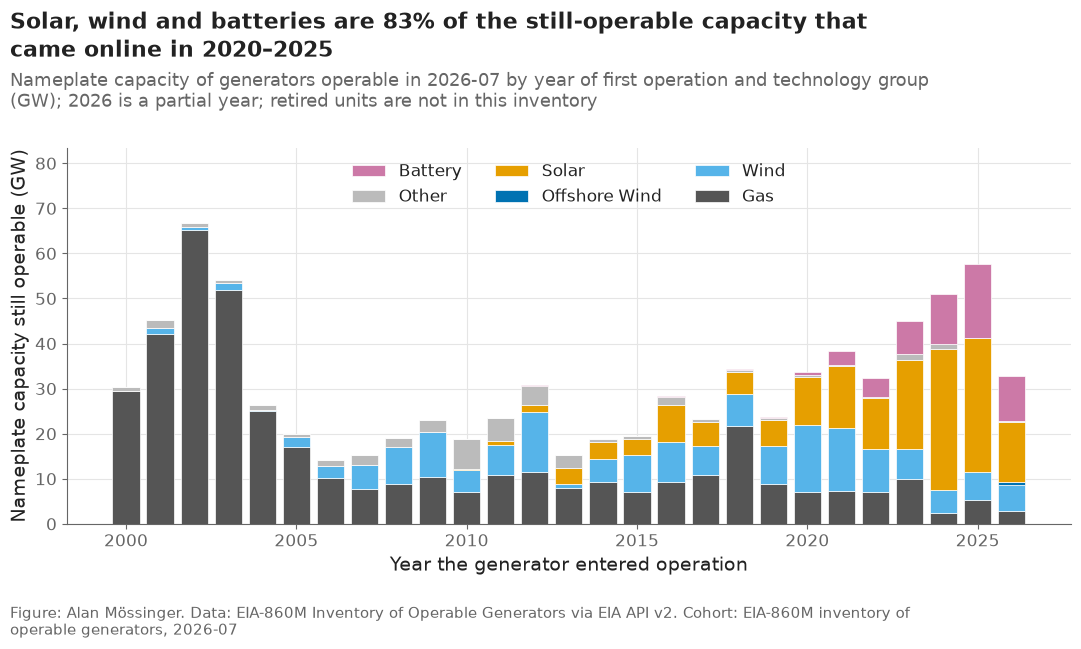

tech_group,Gas,Wind,Offshore Wind,Solar,Solar+Battery,Other,Battery
op_year,,,,,,,
2018,21.7,7.1,0.0,5.0,0.0,0.5,0.2
2019,8.8,8.5,0.0,5.9,0.0,0.4,0.2
2020,7.1,14.9,0.0,10.7,0.0,0.4,0.6
2021,7.4,13.8,0.0,13.8,0.0,0.2,3.1
2022,7.1,9.5,0.0,11.3,0.0,0.3,4.3
2023,9.9,6.6,0.0,19.8,0.0,1.4,7.2
2024,2.4,5.0,0.1,31.2,0.0,1.2,11.1
2025,5.3,6.3,0.0,29.6,0.0,0.2,16.4
2026,2.9,5.6,0.8,13.4,0.0,0.0,10.1


In [28]:
generators["op_year"] = generators["operating-year-month"].str[:4].astype(int)
generators["tech_group"] = generators["type_clean"].map(plots.tech_group)
add_years = range(2000, int(period[:4]) + 1)
added = (generators[generators["op_year"].between(2000, int(period[:4]))]
         .groupby(["op_year", "tech_group"])["nameplate-capacity-mw"].sum().unstack()
         .reindex(index=add_years, columns=stack_order).fillna(0) / 1000)

fig, ax = plt.subplots()
bottom = np.zeros(len(added))
present = [g for g in stack_order if added[g].sum() > 0]  # EIA has no hybrid category
for group in present:
    ax.bar(added.index, added[group], bottom=bottom, color=config.TECH_COLORS[group], width=0.8,
           label=group, edgecolor="white", linewidth=0.5)
    bottom += added[group].values
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="upper center", ncol=3)
ax.set_ylim(0, bottom.max() * 1.25)
ax.set_xlabel("Year the generator entered operation")
ax.set_ylabel("Nameplate capacity still operable (GW)")
window = added.loc[2020:2025]
clean = window[["Solar", "Wind", "Battery"]].sum().sum() / window.sum().sum()
plots.finish(fig,
             f"Solar, wind and batteries are {clean:.0%} of the still-operable capacity that came online "
             "in 2020–2025",
             f"Nameplate capacity of generators operable in {period} by year of first operation and "
             f"technology group (GW); {period[:4]} is a partial year; retired units are not in this inventory",
             f"EIA-860M inventory of operable generators, {period}", eia=True, lbnl=False)
save(fig, "01_18_eia_additions_by_year",
     "Nameplate capacity of still-operable generators by year of first operation and technology group, "
     "from EIA-860M.")
plt.show()
added.loc[2018:].round(1)

**Reading this.** In 2024, 31.2 GW of solar and 11.1 GW of batteries came online and are still operable; in 2025, 29.6 GW and 16.4 GW. Gas additions dropped to 2.4 GW in 2024. Because the inventory only holds generators that still exist, older years are understated (retired units are gone), so this figure is a picture of today's fleet by vintage, not a history of annual additions.

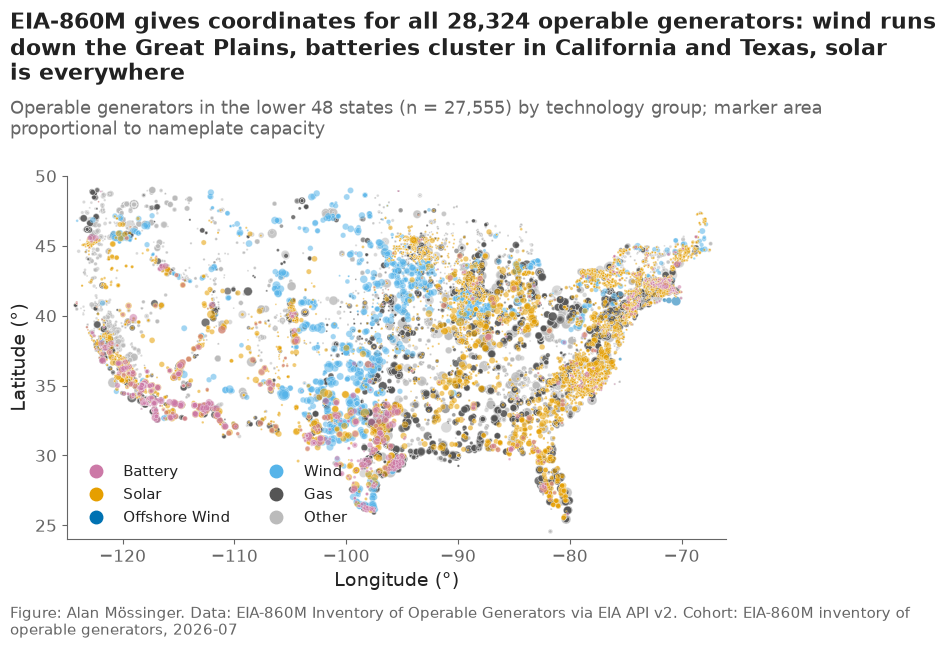

In [29]:
lower48 = generators[generators["longitude"].between(-125, -66) & generators["latitude"].between(24, 50)]
draw_order = ["Other", "Gas", "Wind", "Offshore Wind", "Solar", "Solar+Battery", "Battery"]

fig, ax = plt.subplots()
for group in draw_order:
    part = lower48[lower48["tech_group"] == group]
    ax.scatter(part["longitude"], part["latitude"], s=np.sqrt(part["nameplate-capacity-mw"].clip(lower=0)) * 1.6,
               color=config.TECH_COLORS[group], alpha=0.55, linewidths=0.3, edgecolors="white",
               rasterized=True)  # 27,000 points as vectors would make a 20 MB SVG
ax.set_aspect(1.25)
ax.set_xlim(-125, -66)
ax.set_ylim(24, 50)
ax.set_xlabel("Longitude (°)")
ax.set_ylabel("Latitude (°)")
ax.grid(False)
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markersize=9, color=config.TECH_COLORS[g],
                          label=g) for g in draw_order[::-1] if (lower48["tech_group"] == g).any()],
          loc="lower left", ncol=2, fontsize=11)
plots.finish(fig,
             f"EIA-860M gives coordinates for all {len(generators):,} operable generators: wind runs down "
             "the Great Plains, batteries cluster in California and Texas, solar is everywhere",
             f"Operable generators in the lower 48 states (n = {len(lower48):,}) by technology group; "
             "marker area proportional to nameplate capacity",
             f"EIA-860M inventory of operable generators, {period}", eia=True, lbnl=False)
save(fig, "01_19_eia_generator_map",
     "Locations of operable generators in the lower 48 states from EIA-860M, colored by technology group "
     "and sized by nameplate capacity.")
plt.show()

**Reading this.** Every operable generator has coordinates and a county, which makes the stretch state map (F9) and county-level context possible. The pattern is read from the figure only: wind follows the Great Plains, batteries cluster in California and Texas, solar is spread across the country. No number in the report comes from this map.

## 5. Technology crosswalk (EIA technology → LBNL `type_clean`)

Every EIA technology is mapped to one of the plan's ten groups (Solar, Wind,
Offshore Wind, Battery, Gas, Hydro, Nuclear, Coal, Geothermal, Other) by the
dictionary in `src/config.py`; "Other" always carries a note. The table is
saved to `data/processed/technology_crosswalk.csv` and reviewed below.

In [30]:
crosswalk = eia_api.technology_crosswalk(generators)
crosswalk.to_csv(paths.DATA_PROCESSED / "technology_crosswalk.csv", index=False)
crosswalk_complete = bool(
    crosswalk["type_clean"].isin(config.CROSSWALK_TYPES).all()
    and not crosswalk["note"].str.startswith("NOT IN MAP").any()
    and (crosswalk.loc[crosswalk["type_clean"] == "Other", "note"] != "").all())
print("Every EIA technology mapped (Other always explained):", crosswalk_complete)
crosswalk.round(2)

Every EIA technology mapped (Other always explained): True


,eia_technology,type_clean,note,n_generators,nameplate_gw
0,Natural Gas Fired Combined Cycle,Gas,,1945,328.28
1,Conventional Steam Coal,Coal,,445,181.32
2,Solar Photovoltaic,Solar,,8254,166.26
3,Onshore Wind Turbine,Wind,,1571,165.18
4,Natural Gas Fired Combustion Turbine,Gas,,2257,161.12
5,Nuclear,Nuclear,,96,103.70
6,Natural Gas Steam Turbine,Gas,,550,83.88
7,Conventional Hydroelectric,Hydro,,3983,80.07
8,Batteries,Battery,,1120,53.71
9,Petroleum Liquids,Other,LBNL Oil and Diesel; folded into Other,3804,30.48


**Reading this.** All 27 EIA technologies map to one of the ten groups, and every "Other" carries a note (petroleum, biomass, waste and refinery gases, EIA's residual category). Two judgment calls are worth stating: pumped storage (22.22 GW) goes to Hydro, although LBNL files some pumped storage as "Other Storage", and petroleum liquids (30.48 GW) go to Other, as LBNL's Oil and Diesel types do in the linkage. The crosswalk is used only to compare the two sources; it does not change any LBNL field.

## 6. Quick linkage test (no modeling)

Can an LBNL project be found in EIA-860M? Tested where both sources have an
operation date: LBNL operational projects in ERCOT and PJM. The rule in
`src/linkage.py` (decision #11) matches on state, technology group, nameplate
within ±15% and a shared name word — **not** on dates — and then checks
whether the EIA operating month falls within six months of LBNL's
`on_date`. Notebook 10 (stretch) is worth doing only if ≥ 40% match and
≥ 80% of matches agree.

In [31]:
projects = dated[(dated["q_status"] == "operational") & dated["region"].isin(config.LINK_REGIONS)
                 & dated["on_date"].notna()]
vintages = linkage.eia_plant_vintages(generators)
matches = linkage.match_projects(projects, vintages)

keep = ["q_id", "entity", "region", "state", "project_name", "type1", "mw1", "on_date"]
projects[keep].join(matches.drop(columns="region")).to_csv(
    paths.DATA_PROCESSED / "linkage_test_matches.csv", index=False)

link_overall = linkage.summarise_matches(matches)
link_region = linkage.summarise_matches(matches, by="region")
link_type = linkage.summarise_matches(matches, by="link_type")
pd.concat([link_overall.assign(level="overall").rename(columns={"group": "value"}),
           link_region.assign(level="region").rename(columns={"region": "value"}),
           link_type.assign(level="technology").rename(columns={"link_type": "value"})]
          )[["level", "value", "projects", "matched", "match_rate", "agree", "agree_rate"]].to_csv(
    paths.RESULTS / "linkage_test.csv", index=False)

match_rate = float(link_overall["match_rate"].iloc[0])
agree_rate = float(link_overall["agree_rate"].iloc[0])
linkage_viable = match_rate >= config.LINK_MIN_MATCH_RATE and agree_rate >= config.LINK_MIN_AGREE_RATE
print(f"Projects tested: {len(projects):,}")
print(f"Matched: {pct(match_rate)}   agree within 6 months: {pct(agree_rate)}")
print("Notebook 10 viable:", linkage_viable)
pd.concat([link_region, link_type.rename(columns={"link_type": "region"})]).round(3)

Projects tested: 1,650
Matched: 31.1%   agree within 6 months: 74.9%
Notebook 10 viable: False


,region,projects,matched,match_rate,agree,agree_rate
0,ERCOT,481,229,0.476,165,0.721
1,PJM,1169,284,0.243,219,0.771
0,Battery,34,15,0.441,14,0.933
1,Coal,64,3,0.047,2,0.667
2,Gas,481,66,0.137,39,0.591
3,Hydro,32,5,0.156,1,0.200
4,Nuclear,45,0,0.000,0,NaN
5,Offshore Wind,1,0,0.000,0,NaN
6,Other,242,25,0.103,17,0.680
7,Solar,455,210,0.462,174,0.829


In [32]:
pd.crosstab(matches["link_type"], matches["reason"], margins=True)

reason,matched,"name found, capacity differs >15 %",no EIA plant of that type in the state,no EIA plant shares a name word,no usable project name,All
link_type,,,,,,
Battery,15,1,0,17,1,34
Coal,3,34,2,24,1,64
Gas,66,297,0,100,18,481
Hydro,5,25,0,1,1,32
Nuclear,0,43,0,1,1,45
Offshore Wind,0,0,0,0,1,1
Other,25,50,0,158,9,242
Solar,210,116,0,102,27,455
Wind,189,63,0,40,4,296


**Reading this.** Of 1,650 operational ERCOT and PJM projects, 31.1% matched an EIA plant and 74.9% of those matches agree on the operation month within six months. Both are below the plan's bars (40% and 80%), so **notebook 10 is dropped**, as the plan says it should be. The reason table shows where the rule fails: 629 projects have a same-type plant with a shared name but a capacity more than 15% different — 297 gas, 43 nuclear, 34 coal — which is what uprates and partial phases of existing plants look like; another 443 share no name word with any same-type plant in their state. By technology, wind (63.9%) and solar (46.2%) link best, and solar matches agree 82.9% of the time. A linkage aimed only at new solar, wind and battery projects might pass, but that would be a new test with its own pre-set bar, not a rescue of this one.

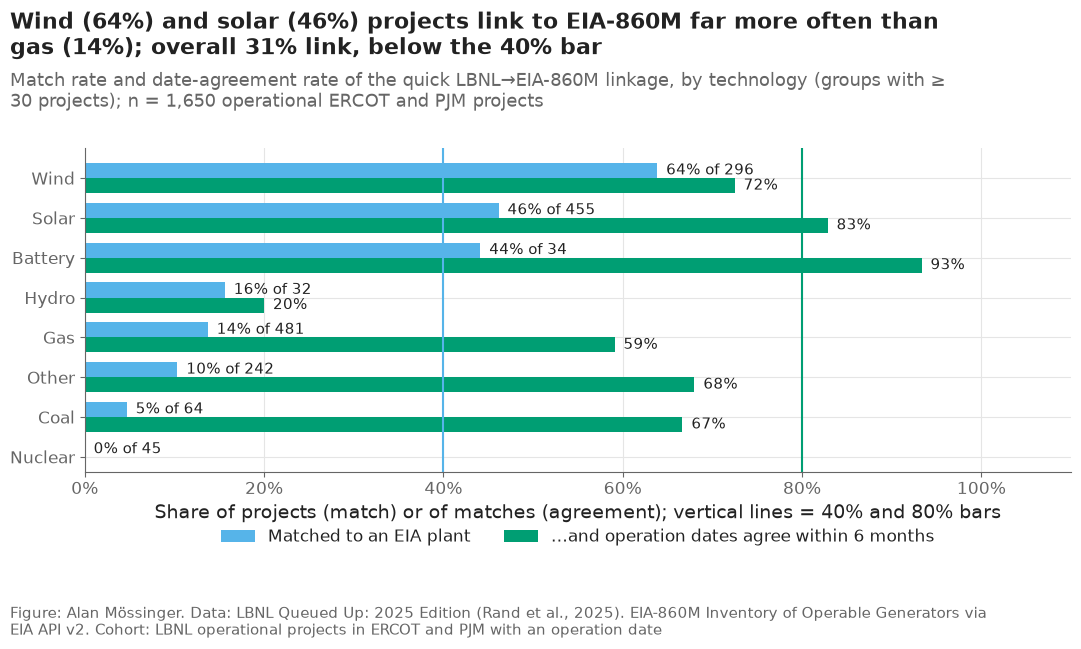

In [33]:
plot_types = link_type[link_type["projects"] >= 30].sort_values("match_rate")
width = 0.38
fig, ax = plt.subplots()
y = np.arange(len(plot_types))
for offset, column, color, label in [(width / 2, "match_rate", "#56B4E9", "Matched to an EIA plant"),
                                     (-width / 2, "agree_rate", config.OUTCOME_COLORS["operation"],
                                      "…and operation dates agree within 6 months")]:
    ax.barh(y + offset, plot_types[column], height=width, color=color, label=label)
for i, row in enumerate(plot_types.itertuples()):
    ax.text(row.match_rate + 0.01, i + width / 2, f"{row.match_rate:.0%} of {row.projects}",
            va="center", fontsize=11)
    ax.text(row.agree_rate + 0.01, i - width / 2, f"{row.agree_rate:.0%}", va="center", fontsize=11)
ax.axvline(config.LINK_MIN_MATCH_RATE, color="#56B4E9", linewidth=1.5)
ax.axvline(config.LINK_MIN_AGREE_RATE, color=config.OUTCOME_COLORS["operation"], linewidth=1.5)
ax.set_yticks(y, plot_types["link_type"])
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share of projects (match) or of matches (agreement); vertical lines = 40% and 80% bars")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
rates = plot_types.set_index("link_type")["match_rate"]
plots.finish(fig,
             f"Wind ({rates['Wind']:.0%}) and solar ({rates['Solar']:.0%}) projects link to EIA-860M far "
             f"more often than gas ({rates['Gas']:.0%}); overall {match_rate:.0%} link, below the 40% bar",
             "Match rate and date-agreement rate of the quick LBNL→EIA-860M linkage, by technology "
             f"(groups with ≥ 30 projects); n = {len(projects):,} operational ERCOT and PJM projects",
             "LBNL operational projects in ERCOT and PJM with an operation date", eia=True)
save(fig, "01_20_linkage_by_technology",
     "Share of LBNL operational ERCOT/PJM projects matched to an EIA-860M plant, and share of matches "
     "whose operation dates agree within six months, by technology.")
plt.show()

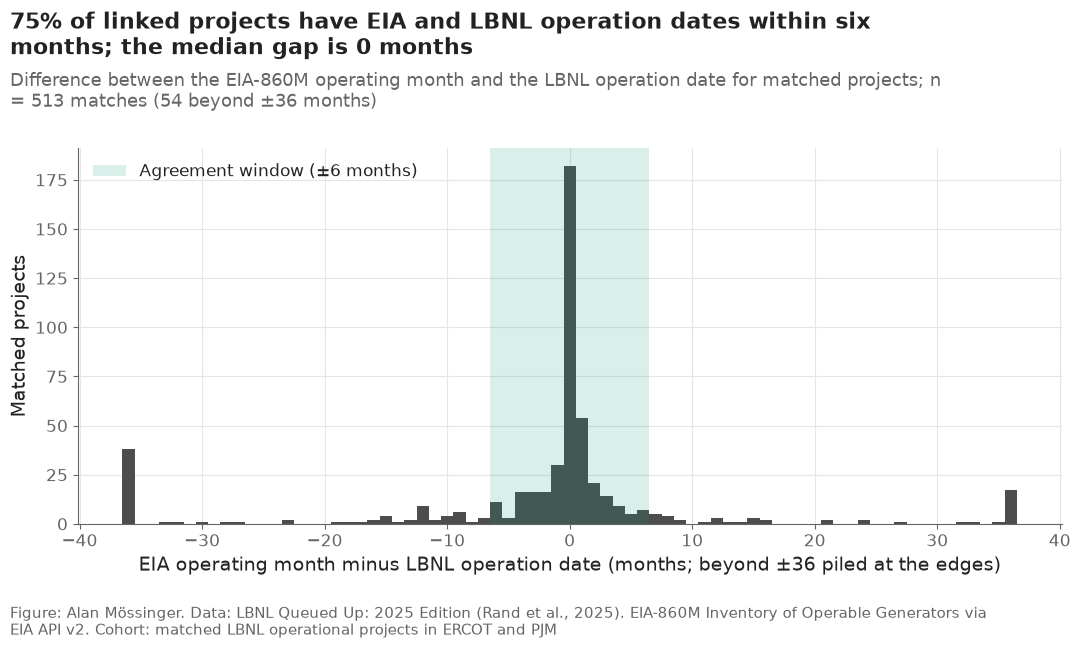

,count,mean,std,min,25%,50%,75%,max
months apart,513.0,-11.6,100.7,-1378.0,-2.0,0.0,1.0,606.0


In [34]:
gap = matches["months_apart"].dropna()
clipped = gap.clip(-36, 36)
fig, ax = plt.subplots()
ax.hist(clipped, bins=np.arange(-36.5, 37.5, 1), color="#4D4D4D")
ax.axvspan(-6.5, 6.5, color=config.OUTCOME_COLORS["operation"], alpha=0.15,
           label="Agreement window (±6 months)")
ax.set_xlabel("EIA operating month minus LBNL operation date (months; beyond ±36 piled at the edges)")
ax.set_ylabel("Matched projects")
ax.legend(loc="upper left")
plots.finish(fig,
             f"{agree_rate:.0%} of linked projects have EIA and LBNL operation dates within six months; "
             f"the median gap is {gap.median():.0f} months",
             "Difference between the EIA-860M operating month and the LBNL operation date for matched "
             f"projects; n = {len(gap):,} matches ({(gap.abs() > 36).sum()} beyond ±36 months)",
             "matched LBNL operational projects in ERCOT and PJM", eia=True)
save(fig, "01_21_linkage_date_gap",
     "Distribution of the gap between EIA-860M operating month and LBNL operation date for linked "
     "projects.")
plt.show()
gap.describe().round(1).to_frame("months apart").T

**Reading this.** The median gap between the EIA operating month and the LBNL operation date is 0 months and the middle half of matches lies between −2 and +1 months, so when the match is right, the two sources agree closely. The tails are long (from −1,378 to +606 months): those are matches to an older unit of the same plant — false or partial matches — and they are why agreement stops at 74.9%.

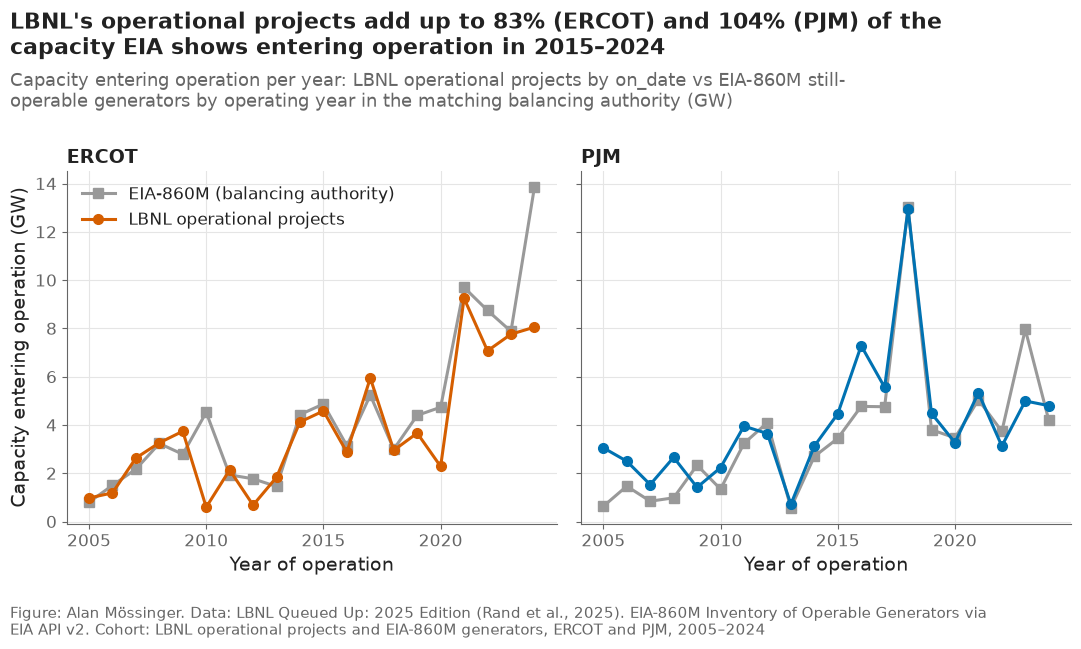

,ERCOT,PJM
"LBNL / EIA capacity, 2015–2024",0.83,1.038


In [35]:
ba_code = {"ERCOT": "ERCO", "PJM": "PJM"}
add_range = range(2005, 2025)
fig, axes = plt.subplots(1, 2, sharey=True)
coverage_ratio = {}
for ax, region in zip(axes, config.LINK_REGIONS):
    lbnl_part = dated[(dated["region"] == region) & (dated["q_status"] == "operational") & dated["on_date"].notna()]
    lbnl_gw = lbnl_part.groupby(lbnl_part["on_date"].dt.year)["mw"].sum().reindex(add_range).fillna(0) / 1000
    eia_part = generators[generators["balancing_authority_code"] == ba_code[region]]
    eia_gw = eia_part.groupby("op_year")["nameplate-capacity-mw"].sum().reindex(add_range).fillna(0) / 1000
    ax.plot(add_range, eia_gw, color=config.OTHER_REGION_COLOR, marker="s", label="EIA-860M (balancing authority)")
    ax.plot(add_range, lbnl_gw, color=plots.region_color(region), marker="o", label="LBNL operational projects")
    ax.set_title(region)
    ax.set_xlabel("Year of operation")
    year_ticks(ax, 2005, 2024)
    coverage_ratio[region] = lbnl_gw.loc[2015:2024].sum() / eia_gw.loc[2015:2024].sum()
axes[0].set_ylabel("Capacity entering operation (GW)")
axes[0].legend(loc="upper left")
plots.finish(fig,
             f"LBNL's operational projects add up to {coverage_ratio['ERCOT']:.0%} (ERCOT) and "
             f"{coverage_ratio['PJM']:.0%} (PJM) of the capacity EIA shows entering operation in 2015–2024",
             "Capacity entering operation per year: LBNL operational projects by on_date vs EIA-860M "
             "still-operable generators by operating year in the matching balancing authority (GW)",
             "LBNL operational projects and EIA-860M generators, ERCOT and PJM, 2005–2024", eia=True)
save(fig, "01_22_lbnl_vs_eia_additions",
     "Capacity entering operation per year according to LBNL operational projects and EIA-860M "
     "generators, ERCOT and PJM.")
plt.show()
pd.Series(coverage_ratio, name="LBNL / EIA capacity, 2015–2024").round(3).to_frame().T

**Reading this.** Summed over 2015–2024, LBNL's operational projects add up to 83% of the capacity EIA shows entering operation in ERCOT and 103.8% in PJM. PJM above 100% is expected: LBNL counts an uprate as new capacity on its completion date while EIA dates the original unit, and generators retired since then are not in the EIA inventory. ERCOT's shortfall is concentrated in 2024 in the figure; projects that came online late in 2024 may still show as active in the end-2024 LBNL snapshot. Overall, LBNL's "operational" status tracks real additions closely in these two ISOs, which supports using it as the outcome for Track A.

## 7. Data access statement and data dictionary

`data/README.md` holds the access statement (sources, terms, how to obtain
them, what is redistributed). This cell fills its dictionary section: every
column of both raw tables with its type, how often it is filled and its
meaning (LBNL's codebook; EIA's field list), plus the two derived tables.

In [36]:
def markdown_table(frame):
    """Render a small DataFrame as a GitHub markdown table."""
    header = "| " + " | ".join(frame.columns) + " |"
    rule = "|" + "|".join("---" for _ in frame.columns) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join([header, rule, *body])


lbnl_notes = dict(zip(codebook["field"], codebook["description"]))
lbnl_dict = pd.DataFrame({
    "column": raw.columns,
    "type": [str(t) for t in raw.dtypes],
    "filled": [pct(raw[c].notna().mean(), 0) for c in raw.columns],
    "meaning (LBNL codebook)": [lbnl_notes.get(c, "") for c in raw.columns],
})
lbnl_dict.loc[lbnl_dict["column"].isin(config.LBNL_DATE_COLS), "type"] = "Excel serial date"
eia_dict = pd.DataFrame({
    "column": generators.columns.drop(["type_clean", "op_year", "tech_group"]),
})
eia_dict["type"] = [str(generators[c].dtype) for c in eia_dict["column"]]
eia_dict["filled"] = [pct(generators[c].replace("", np.nan).notna().mean(), 0) for c in eia_dict["column"]]
eia_dict["meaning"] = eia_dict["column"].map(eia_api.FIELD_DESCRIPTIONS).fillna("")
derived = pd.DataFrame([
    {"table": "data/processed/technology_crosswalk.csv",
     "columns": "eia_technology, type_clean, note, n_generators, nameplate_gw",
     "made by": "notebook 01 §5"},
    {"table": "data/processed/linkage_test_matches.csv",
     "columns": ", ".join(keep) + ", link_type, matched, reason, eia_plantid, eia_plant_name, eia_mw, months_apart",
     "made by": "notebook 01 §6"},
])

dictionary = "\n\n".join([
    "## Data dictionary",
    "*This section is written by `notebooks/01_problem_and_data.ipynb`; edit the notebook, not this text.*",
    f"### LBNL sheet `{config.LBNL_SHEET}` ({raw.shape[0]:,} rows × {raw.shape[1]} columns)",
    "Codebook fields absent from the public sheet: "
    + ", ".join(f"`{f}`" for f in sorted(set(codebook["field"]) - set(raw.columns))) + ".",
    markdown_table(lbnl_dict),
    f"### EIA-860M, route `{config.EIA_ROUTE}`, period {period} ({len(generators):,} rows)",
    markdown_table(eia_dict),
    "### Derived tables",
    markdown_table(derived),
])
readme_path = paths.DATA / "README.md"
readme = readme_path.read_text(encoding="utf-8")
readme = re.sub(r"(?s)<!-- dictionary:start -->.*<!-- dictionary:end -->",
                lambda _: f"<!-- dictionary:start -->\n{dictionary}\n<!-- dictionary:end -->", readme)
readme_path.write_text(readme, encoding="utf-8")
print("data/README.md dictionary updated:", len(lbnl_dict), "LBNL columns,", len(eia_dict), "EIA columns")
lbnl_dict.head(8)

data/README.md dictionary updated: 31 LBNL columns, 26 EIA columns


,column,type,filled,meaning (LBNL codebook)
0,q_id,object,100%,queue ID number
1,q_status,object,100%,"current queue status (active, withdrawn, suspe..."
2,q_date,Excel serial date,98%,interconnection request date (date project ent...
3,prop_date,Excel serial date,80%,proposed online date from interconnection appl...
4,on_date,Excel serial date,8%,date project became operational (if applicable)
5,wd_date,Excel serial date,28%,date project withdrawn from queue (if applicable)
6,ia_date,Excel serial date,7%,date of signed interconnection agreement (if a...
7,IA_status_raw,object,67%,interconnection study phase / status from queue


**Reading this.** The dictionary in `data/README.md` now lists all 31 LBNL columns with LBNL's own codebook wording and all 26 EIA columns, each with its type and how often it is filled, plus the two derived tables. It is regenerated on every run, so it cannot drift from the data.

## 8. Readiness checklist — the gate

Each line of PLAN.md §5.3 becomes a printed check with the number behind it.
Thresholds come from `src/config.py` and are applied strictly; a failure is
reported, not explained away. The outcome is GO only if every check passes.
The table goes to `results/readiness_checks.csv` and the report to
`docs/data_readiness.md`.

In [37]:
checks = []


def check(name, condition, observed, passed):
    """Record one readiness check."""
    checks.append({"check": name, "pass condition": condition, "observed": observed,
                   "result": "PASS" if passed else "FAIL"})


cov = coverage.set_index("region").loc[TRACK_A]
early_med, late_med = early.median(), late.median()
mock_ok = all(abs(mock_shares[r] - v) <= 0.01 for r, v in config.MOCKUP_EXPECTED.items())
headline_ok = (abs(op_share - config.HEADLINE_OPERATIONAL_SHARE) <= config.HEADLINE_TOLERANCE
               and abs(wd_share - config.HEADLINE_WITHDRAWN_SHARE) <= config.HEADLINE_TOLERANCE)
n_candidates = int(candidates.sum())
(paths.RESULTS / "headline_checks.json").write_text(json.dumps({
    "capacity_share_operational_2000_2019": round(float(op_share), 4),
    "capacity_share_withdrawn_2000_2019": round(float(wd_share), 4),
    "median_ir_to_cod_2000_2007": round(float(early_med), 3),
    "median_ir_to_cod_2018_2024": round(float(late_med), 3),
    "track_a_candidates": n_candidates,
    "track_a_candidates_valid_q_date": int((candidates & dated["q_date_valid"]).sum()),
    "test_cohort": held_out,
}, indent=2), encoding="utf-8")

check("S1 present, SHA-256 recorded, loads",
      "frozen file verified; 36,441 rows × 31 columns",
      f"SHA-256 match = {get_lbnl.sha256(lbnl_path) == config.LBNL_SHA256}; "
      f"{raw.shape[0]:,} × {raw.shape[1]}",
      get_lbnl.sha256(lbnl_path) == config.LBNL_SHA256 and raw.shape == (36441, 31))
check("S1 counts match the 2026-10-03 audit",
      "status, region, 204 placeholder q_date, 17 negative-MW rows",
      f"{int(audit_table['match'].sum())} of {len(audit_table)} items equal",
      bool(audit_table["match"].all()))
check("S1 headline: capacity outcome of 2000–2019 requests",
      "≈13% operational / ≈77% withdrawn (±1 point)",
      f"{pct(op_share)} / {pct(wd_share)}", headline_ok)
check("S1 headline: median request-to-operation time",
      "< 2 yr for 2000–07 completions; > 4 yr for 2018–24",
      f"{early_med:.2f} yr (n = {len(early)}) / {late_med:.2f} yr (n = {len(late)})",
      early_med < 2 and late_med > 4)
check("S1 naive mock-up reproduces",
      "5-yr completion CAISO 4% / ERCOT 21% / PJM 15% (±1 point)",
      " / ".join(f"{r} {pct(mock_shares[r])}" for r in ["CAISO", "ERCOT", "PJM"]), mock_ok)
check("S1 event-date coverage: operation dates",
      f"≥ {config.COVERAGE_MIN_ON_DATE:.0%} of operational rows have on_date in each Track A region",
      ", ".join(f"{r} {pct(cov.loc[r, 'on_date_share'])}" for r in TRACK_A),
      bool((cov["on_date_share"] >= config.COVERAGE_MIN_ON_DATE).all()))
check("S1 event-date coverage: withdrawal dates",
      f"≥ {config.COVERAGE_MIN_WD_DATE:.0%} of withdrawn rows have wd_date in each Track A region",
      ", ".join(f"{r} {pct(cov.loc[r, 'wd_date_share'])}" for r in TRACK_A),
      bool((cov["wd_date_share"] >= config.COVERAGE_MIN_WD_DATE).all()))
check("S1 Track A candidate sample",
      f"{config.TRACK_A_RANGE[0]:,}–{config.TRACK_A_RANGE[1]:,} projects",
      f"{n_candidates:,} (with a valid request date: {int((candidates & dated['q_date_valid']).sum()):,})",
      config.TRACK_A_RANGE[0] <= n_candidates <= config.TRACK_A_RANGE[1])
check("S1 enough events for a held-out test",
      f"2017–2019 Track A entrants ≥ {config.TEST_MIN_PROJECTS:,} with ≥ {config.TEST_MIN_COMPLETIONS} "
      "completions by end-2024",
      f"{held_out['projects']:,} projects; {held_out['completions']} completions; "
      f"{held_out['withdrawals']:,} withdrawals",
      held_out["projects"] >= config.TEST_MIN_PROJECTS
      and held_out["completions"] >= config.TEST_MIN_COMPLETIONS)
check("S2 API works with the key",
      f"metadata returns; latest period ≥ {config.EIA_MIN_PERIOD}; rows = response.total",
      f"latest {period}; {pull_log['rows']:,} rows of {pull_log['total']:,} in {pull_log['pages']} pages",
      period >= config.EIA_MIN_PERIOD and pull_log["rows"] == pull_log["total"])
field_ok = (field_share["status OP"]["operating-year-month"] >= config.EIA_MIN_FIELD_SHARE["operating-year-month"]
            and all(field_share["all rows"][f] >= v for f, v in config.EIA_MIN_FIELD_SHARE.items()
                    if f != "operating-year-month"))
check("S2 fields usable",
      "operating month ≥ 95% of OP rows; state, technology ≥ 99%; county, lat/long ≥ 95%",
      ", ".join(f"{f} {pct(field_share['all rows'][f])}" for f in fields), field_ok)
check("Crosswalk complete",
      "every EIA technology maps to one type, or to Other with a note",
      f"{len(crosswalk)} technologies; complete = {crosswalk_complete}", crosswalk_complete)
check("Linkage test",
      "match rate reported; notebook 10 viable if ≥ 40% matched and ≥ 80% of matches agree ±6 months",
      f"{pct(match_rate)} matched, {pct(agree_rate)} agree → notebook 10 "
      + ("viable" if linkage_viable else "not viable, dropped"), True)
readme_text = (paths.DATA / "README.md").read_text(encoding="utf-8")
licenses_ok = all(s in readme_text for s in ["### S1", "### S2", "**Terms:**", "**How to obtain:**",
                                              "What is redistributed"])
check("Licenses documented",
      "data/README.md gives source, terms, how to obtain, what is redistributed for S1 and S2",
      f"all sections present = {licenses_ok}", licenses_ok)

In [38]:
TEXT_SUFFIXES = {".py", ".md", ".ipynb", ".txt", ".json", ".csv", ".ini", ".toml", ".cfg", ".yml",
                 ".yaml", ".example", ""}
listed = subprocess.run(["git", "ls-files", "--cached", "--others", "--exclude-standard"],
                        cwd=paths.REPO, capture_output=True, text=True, check=True).stdout.splitlines()
env_ignored = subprocess.run(["git", "check-ignore", "-q", ".env"], cwd=paths.REPO).returncode == 0
key_files, assigned, mentions = 0, [], []
for name in listed:
    file = paths.REPO / name
    if file.suffix not in TEXT_SUFFIXES or not file.is_file():
        continue
    text = file.read_text(encoding="utf-8", errors="ignore")
    key_files += eia_key in text
    if "EIA_API_KEY" in text:
        mentions.append(name)
    if re.search(r"EIA_API_KEY=[A-Za-z0-9]{20,}", text):
        assigned.append(name)
secrets_ok = env_ignored and key_files == 0 and not assigned
print("Files that would be committed:", len(listed))
print("Files mentioning the variable name:", mentions)
check("Secrets safe",
      ".env git-ignored; the key appears in no committed file; no key assigned outside .env",
      f".env ignored = {env_ignored}; files containing the key = {key_files}; "
      f"key assignments = {len(assigned)}", secrets_ok)

readiness = pd.DataFrame(checks)
readiness.to_csv(paths.RESULTS / "readiness_checks.csv", index=False)
failed = readiness.loc[readiness["result"] == "FAIL", "check"].tolist()
outcome = "GO" if not failed else "NO-GO (failed: " + "; ".join(failed) + ")"
print(readiness["result"].value_counts().to_dict(), "→", outcome)
readiness

Files that would be committed: 802
Files mentioning the variable name: ['.env.example', 'data/README.md', 'notebooks/01_problem_and_data.ipynb', 'src/eia_api.py']
{'PASS': 15} → GO


,check,pass condition,observed,result
0,"S1 present, SHA-256 recorded, loads","frozen file verified; 36,441 rows × 31 columns","SHA-256 match = True; 36,441 × 31",PASS
1,S1 counts match the 2026-10-03 audit,"status, region, 204 placeholder q_date, 17 neg...",18 of 18 items equal,PASS
2,S1 headline: capacity outcome of 2000–2019 req...,≈13% operational / ≈77% withdrawn (±1 point),12.6% / 76.9%,PASS
3,S1 headline: median request-to-operation time,< 2 yr for 2000–07 completions; > 4 yr for 201...,1.82 yr (n = 240) / 4.14 yr (n = 884),PASS
4,S1 naive mock-up reproduces,5-yr completion CAISO 4% / ERCOT 21% / PJM 15%...,CAISO 4.2% / ERCOT 21.3% / PJM 15.2%,PASS
5,S1 event-date coverage: operation dates,≥ 95% of operational rows have on_date in each...,"ERCOT 98.4%, PJM 97.8%, CAISO 95.2%",PASS
6,S1 event-date coverage: withdrawal dates,≥ 82% of withdrawn rows have wd_date in each T...,"ERCOT 100.0%, PJM 96.9%, CAISO 82.6%",PASS
7,S1 Track A candidate sample,"13,500–14,500 projects","13,733 (with a valid request date: 13,438)",PASS
8,S1 enough events for a held-out test,"2017–2019 Track A entrants ≥ 2,000 with ≥ 150 ...","2,292 projects; 304 completions; 1,358 withdra...",PASS
9,S2 API works with the key,metadata returns; latest period ≥ 2026-06; row...,"latest 2026-07; 28,324 rows of 28,324 in 6 pages",PASS


**Reading this.** All 15 checks pass, so the gate reads **GO**. Two of them pass only because Alan amended their thresholds after the first evaluation, which read NO-GO on exactly these two (decision #15): CAISO's withdrawal-date coverage is 82.6% (bar 83% → 82%; the 83% was the audit's rounded value), and the 2017–2019 test cohort has 2,292 projects (bar 2,500 → 2,000; only 2,313 Track A rows entered in those years) with 304 completions against the unchanged minimum of 150. The test cohort is therefore smaller than the plan assumed, which will widen the confidence intervals in notebook 08; the bootstrap intervals there will show by how much. The secrets check confirms the key appears in no file that would be committed.

In [39]:
cov_table = coverage.assign(
    on_date_share=lambda t: (100 * t["on_date_share"]).round(1),
    wd_date_share=lambda t: (100 * t["wd_date_share"]).round(1),
    q_date_share=lambda t: (100 * t["q_date_share"]).round(1),
)[["region", "n_projects", "n_operational", "on_date_share", "n_withdrawn", "wd_date_share", "q_date_share"]]
report = "\n\n".join([
    "# Data readiness report (Phase 0 gate)",
    f"*Written by `notebooks/01_problem_and_data.ipynb` on {date.today().isoformat()}. "
    "Every number below was computed by that notebook; thresholds are in `src/config.py`.*",
    "## Sources",
    f"- **S1** LBNL Queued Up 2025 project file `{config.LBNL_FILENAME}`, sheet `{config.LBNL_SHEET}`, "
    f"{raw.shape[0]:,} × {raw.shape[1]}, SHA-256 `{config.LBNL_SHA256}`. Release check on the LBNL "
    f"page: {release['status']} {release['detail']}.",
    f"- **S2** EIA-860M via EIA API v2, route `{config.EIA_ROUTE}`, period {period}: "
    f"{pull_log['rows']:,} generators in {pull_log['pages']} pages.",
    "## Checks",
    markdown_table(readiness),
    "**Threshold changes.** Two thresholds were amended by Alan after the first evaluation, which "
    "had read NO-GO on exactly these two checks (decision #15): withdrawal-date coverage in each "
    "Track A region ≥ 83% → ≥ 82%, and the held-out test cohort ≥ 2,500 → ≥ 2,000 projects "
    "(≥ 150 completions unchanged).",
    "## Event-date coverage by region (%)",
    markdown_table(cov_table),
    "## Notes for the next notebooks",
    f"- Track A candidates: {n_candidates:,}; with a valid request date {int((candidates & dated['q_date_valid']).sum()):,} "
    "(notebook 04 needs the request date, so its sample will be the smaller number before cleaning).",
    f"- Rows above 5,000 MW: {counts['mw_over_5000_rows']} (largest {counts['max_mw']:,.0f} MW); "
    f"missing q_year: {counts['missing_q_year']}; duplicate (q_id, entity) rows: {counts['duplicate_key_rows']}.",
    f"- Linkage: {pct(match_rate)} of ERCOT/PJM operational projects matched an EIA plant and "
    f"{pct(agree_rate)} of matches agree on the operation month within six months.",
    f"**Outcome ({date.today().isoformat()}): {outcome}**",
])
(paths.DOCS / "data_readiness.md").write_text(report + "\n", encoding="utf-8")
print(report.splitlines()[-1])

**Outcome (2026-10-14): GO**


## Takeaways — Part A

- The public LBNL file reproduces the 2026-10-03 audit exactly (18 of 18 items) and LBNL's headlines: 12.6% of 2000–2019 capacity built and 76.9% withdrawn; median wait from request to operation up from 1.82 to 4.14 years.
- Only CAISO, ERCOT and PJM record both exit dates, giving 13,733 Track A candidates (13,438 with a valid request date). The naive five-year completion share is 4.2% in CAISO, 15.2% in PJM and 21.3% in ERCOT.
- The EIA API works with the key: 28,324 operable generators for 2026-07, every needed field complete, all 27 technologies crosswalked.
- The quick linkage reaches 31.1% matched and 74.9% date agreement, below the 40% / 80% bars, so stretch notebook 10 is dropped; most failures are uprates or phases whose capacity differs from the EIA unit.
- A new risk for notebook 04: the stored proposed online date looks updated after entry (44% of completed projects within a month of their actual date), so the planned ambition-gap feature may leak.
- **Gate: GO.** All 15 checks pass after Alan amended two thresholds that the data could not meet as first written (decision #15): withdrawal-date coverage ≥ 82% (CAISO 82.6%) and ≥ 2,000 test projects (2,292, with 304 completions).

**What goes to the report:** 01_02 (why three ISOs: the data section), 01_06 (headline reproduced), 01_09 (the naive baseline the models must beat), 01_08 (regional waits, for the lender discussion) and 01_15 (a data limitation); the data access paragraph comes from `data/README.md`.

# Part B — Clean the queue data (was notebook 02)

This notebook applies cleaning rules R1–R9 to the LBNL project file, one rule
at a time with a before/after table for each, and saves the clean table every
later notebook starts from.

## Setup

The rules live in `src/cleaning.py`, one function each. `cleaning.apply_rule()`
runs a rule and appends what it touched to `log`, which becomes
`results/clean_log.csv`.

In [40]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import cleaning, config, get_lbnl, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "01_problem_and_data"
TRACK_A = config.TRACK_A_REGIONS


def save(fig, name, caption):
    """Save a figure of this notebook under figures/01_problem_and_data/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"


DATE_COLS = config.LBNL_DATE_COLS
STATUSES = ["operational", "withdrawn", "active", "suspended"]

## 1. Load the raw sheet

The frozen workbook is verified again (`get_lbnl.download()` checks the
SHA-256) and read exactly as published.

In [41]:
raw = get_lbnl.load_queue(get_lbnl.download())
log = []
print("Rows in:", f"{len(raw):,}", "| columns:", raw.shape[1])

Rows in: 36,441 | columns: 31


## 2. R1 — convert the dates from Excel serial numbers

**What:** the five date columns become real dates. **Why:** LBNL stores them as
Excel day numbers (43511 = 2019-02-15), which cannot be compared or subtracted
as dates. The table shows each column's type and range before and after.

In [42]:
step1 = cleaning.apply_rule(cleaning.r1_convert_dates, raw, log)
pd.DataFrame({
    "type before": [str(raw[c].dtype) for c in DATE_COLS],
    "example before": [raw[c].dropna().iloc[0] for c in DATE_COLS],
    "type after": [str(step1[c].dtype) for c in DATE_COLS],
    "earliest after": [step1[c].min().date() for c in DATE_COLS],
    "latest after": [step1[c].max().date() for c in DATE_COLS],
    "values": [int(step1[c].notna().sum()) for c in DATE_COLS],
}, index=DATE_COLS)

,type before,example before,type after,earliest after,latest after,values
q_date,float64,43511.0,datetime64[ns],1970-01-01,2024-12-31,35834
prop_date,float64,39539.0,datetime64[ns],1905-06-23,2050-12-31,29029
on_date,float64,41274.0,datetime64[ns],1924-02-28,2024-12-30,2957
wd_date,float64,38860.0,datetime64[ns],1999-06-26,2025-02-19,10138
ia_date,float64,42326.0,datetime64[ns],1970-01-01,2024-12-30,2440


**Reading this.** All five date columns are now real dates, and their ranges already show what R2–R4 have to deal with: request dates start at 1970-01-01 (the placeholder), operation dates go back to 1924-02-28, proposed online dates run from 1905-06-23 to 2050-12-31, and withdrawal dates reach 2025-02-19, after the censor date. 35,834 request dates, 2,957 operation dates and 10,138 withdrawal dates are present.

## 3. R2 — placeholder dates become missing; `q_year` follows `q_date`

**What:** 1970-01-01 in `q_date` and `ia_date` is set to missing and `q_year`
is recomputed from `q_date`. **Why:** 1970-01-01 is the Unix epoch, a fill
value; left in, those projects would look 50 years old.

In [43]:
step2 = cleaning.apply_rule(cleaning.r2_placeholder_dates, step1, log)
placeholder = pd.Timestamp(config.PLACEHOLDER_Q_DATE)
pd.DataFrame({
    "before R2": [int((step1["q_date"] == placeholder).sum()), int((step1["ia_date"] == placeholder).sum()),
                  int((step1["q_year"] == 1970).sum()), int(step1["q_year"].isna().sum())],
    "after R2": [int((step2["q_date"] == placeholder).sum()), int((step2["ia_date"] == placeholder).sum()),
                 int((step2["q_year"] == 1970).sum()), int(step2["q_year"].isna().sum())],
}, index=["q_date = 1970-01-01", "ia_date = 1970-01-01", "q_year = 1970", "q_year missing"])

,before R2,after R2
q_date = 1970-01-01,204,0
ia_date = 1970-01-01,56,0
q_year = 1970,204,0
q_year missing,607,811


In [44]:
moved = step1["q_date"] == placeholder
step1.loc[moved, "region"].value_counts().rename("placeholder q_date rows").to_frame().T

region,West,Southeast,ERCOT,PJM,MISO,ISO-NE,CAISO,SPP,NYISO
placeholder q_date rows,73,46,25,24,14,9,7,5,1


**Reading this.** R2 removes all 204 placeholder request dates and 56 placeholder IA dates. The 204 placeholder rows are exactly the rows whose `q_year` read 1970, so recomputing `q_year` changes those 204 values and nothing else; `q_year` is now missing for 811 rows (the 607 that never had a date plus the 204). The plan's "607 year mismatches" are therefore missing years, not disagreements. The placeholders sit mostly in the West (73), the Southeast (46), ERCOT (25) and PJM (24). Without a request date these rows cannot enter either model, because the clock has no start.

## 4. R3 — operation dates must fit the status and the request date

**What:** `on_date` is cleared when the status is not operational, when it is
earlier than the request date, or when it is before 1950. **Why:** the status
is the more recent field, and a project cannot start operating before it asked
to connect. The row is kept — only the impossible date goes.

In [45]:
step3 = cleaning.apply_rule(cleaning.r3_operation_dates, step2, log)
pd.DataFrame({
    "rows with on_date, before R3": step2.groupby("q_status")["on_date"].count(),
    "after R3": step3.groupby("q_status")["on_date"].count(),
}).reindex(STATUSES + ["unknown"])

,"rows with on_date, before R3",after R3
q_status,,
operational,2361,2292
withdrawn,543,0
active,26,0
suspended,27,0
unknown,0,0


## 5. R4 — withdrawal dates must fit the status and the request date

**What:** `wd_date` is cleared when the status is not withdrawn or when it is
earlier than the request date. **Why:** same reasoning as R3. Withdrawal dates
after the censor date are left for notebook 04, which censors them.

In [46]:
step4 = cleaning.apply_rule(cleaning.r4_withdrawal_dates, step3, log)
pd.DataFrame({
    "rows with wd_date, before R4": step3.groupby("q_status")["wd_date"].count(),
    "after R4": step4.groupby("q_status")["wd_date"].count(),
}).reindex(STATUSES + ["unknown"])

,"rows with wd_date, before R4",after R4
q_status,,
operational,0,0
withdrawn,10115,10111
active,6,0
suspended,17,0
unknown,0,0


The figure puts R3 and R4 side by side: for each status, the share of rows that
carry an operation date and a withdrawal date, before R3 and after R4.

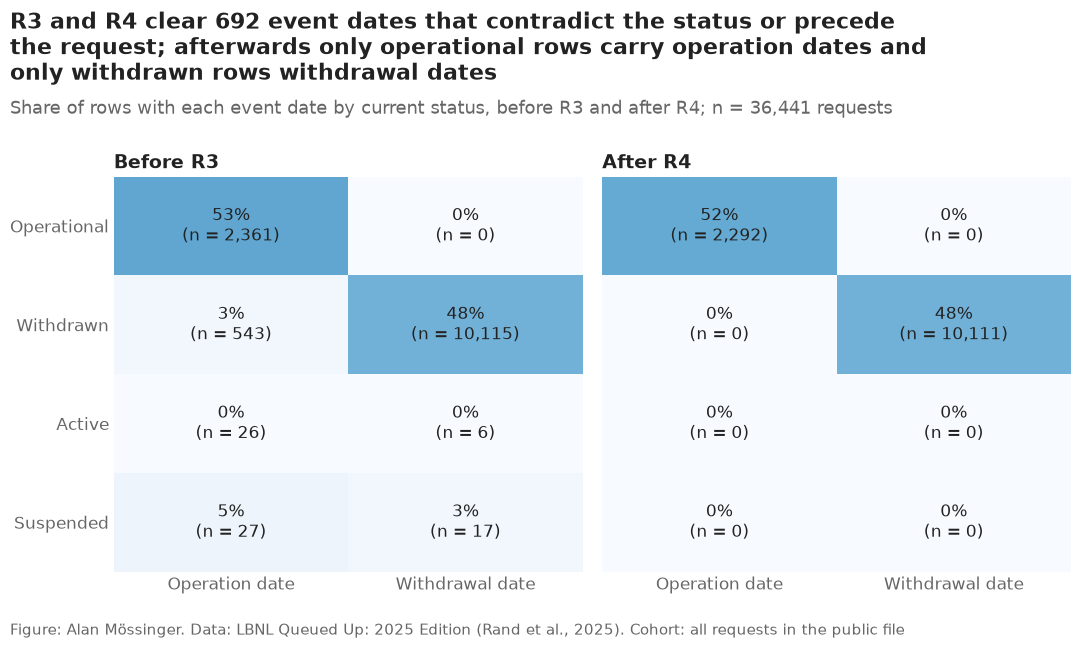

In [47]:
def date_presence(frame):
    """Share of rows with on_date / wd_date by status."""
    return (frame.groupby("q_status")[["on_date", "wd_date"]].agg(lambda s: s.notna().mean())
            .reindex(STATUSES))


panels = {"Before R3": date_presence(step2), "After R4": date_presence(step4)}
counts = {"Before R3": step2.groupby("q_status")[["on_date", "wd_date"]].count().reindex(STATUSES),
          "After R4": step4.groupby("q_status")[["on_date", "wd_date"]].count().reindex(STATUSES)}
fig, axes = plt.subplots(1, 2, sharey=True)
for ax, (title, share) in zip(axes, panels.items()):
    ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks([0, 1], ["Operation date", "Withdrawal date"])
    ax.set_yticks(range(len(STATUSES)), [s.capitalize() for s in STATUSES])
    ax.set_title(title)
    ax.grid(False)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    for i in range(share.shape[0]):
        for j in range(share.shape[1]):
            value = share.iat[i, j]
            ax.text(j, i, f"{value:.0%}\n(n = {counts[title].iat[i, j]:,})", ha="center", va="center",
                    fontsize=12, color="white" if value > 0.6 else plots.INK)
cleared = int(sum(row["rows"] for row in log if row["rule"] in ("R3", "R4")))
plots.finish(fig,
             f"R3 and R4 clear {cleared:,} event dates that contradict the status or precede the request; "
             "afterwards only operational rows carry operation dates and only withdrawn rows withdrawal dates",
             "Share of rows with each event date by current status, before R3 and after R4; n = "
             f"{len(step4):,} requests",
             "all requests in the public file")
save(fig, "02_01_event_dates_vs_status",
     "Share of rows carrying an operation date and a withdrawal date by status, before and after rules R3–R4.")
plt.show()

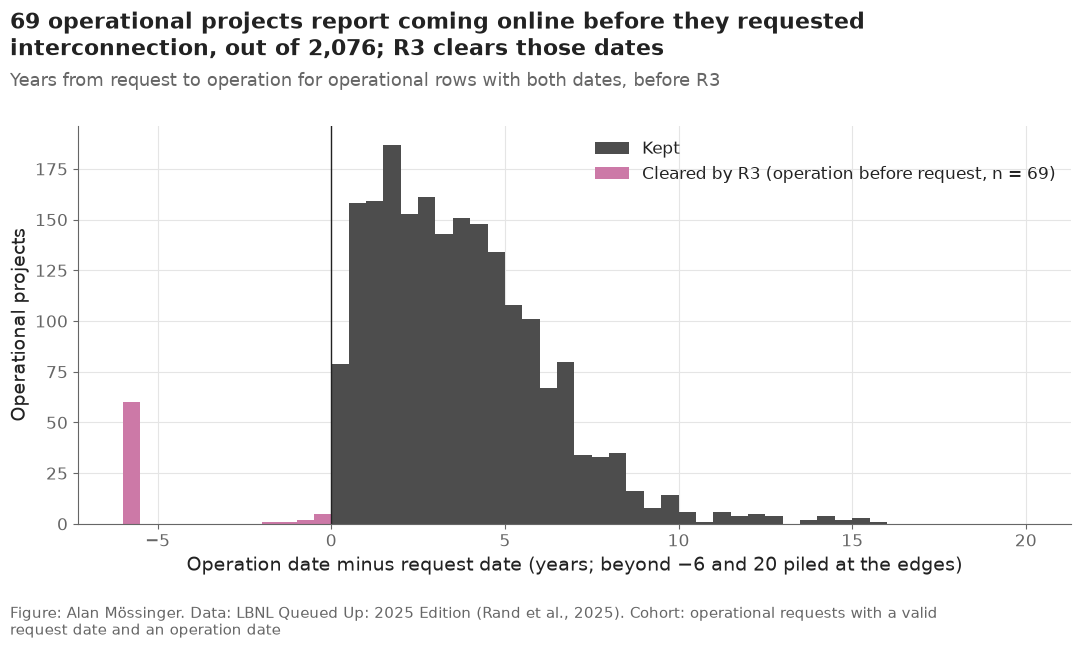

Cleared rows by region: {'West': 52, 'ERCOT': 10, 'PJM': 4, 'CAISO': 2, 'Southeast': 1}


In [48]:
operational = step2[(step2["q_status"] == "operational") & step2["on_date"].notna() & step2["q_date"].notna()]
years = (operational["on_date"] - operational["q_date"]).dt.days / config.DAYS_PER_YEAR
negative = years < 0

fig, ax = plt.subplots()
bins = np.arange(-6, 20.5, 0.5)
ax.hist(years[~negative].clip(upper=20), bins=bins, color="#4D4D4D", label="Kept")
ax.hist(years[negative].clip(lower=-6), bins=bins, color=config.OUTCOME_COLORS["withdrawal"],
        label=f"Cleared by R3 (operation before request, n = {int(negative.sum())})")
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_xlabel("Operation date minus request date (years; beyond −6 and 20 piled at the edges)")
ax.set_ylabel("Operational projects")
ax.legend(loc="upper right")
plots.finish(fig,
             f"{int(negative.sum())} operational projects report coming online before they requested "
             f"interconnection, out of {len(operational):,}; R3 clears those dates",
             "Years from request to operation for operational rows with both dates, before R3",
             "operational requests with a valid request date and an operation date")
save(fig, "02_02_operation_before_request",
     "Distribution of years from request to operation for operational projects, with the negative values "
     "removed by rule R3 highlighted.")
plt.show()
print("Cleared rows by region:", operational.loc[negative, "region"].value_counts().to_dict())

**Reading this.** R3 clears 596 operation dates on rows that are not operational (543 withdrawn, 26 active, 27 suspended) and 69 that precede their own request date; none is left before 1950. R4 clears 23 withdrawal dates on rows that are not withdrawn (6 active, 17 suspended) and 4 that precede the request. Afterwards the only operation dates are on operational rows and the only withdrawal dates on withdrawn rows (02_01). Of the 69 operation-before-request cases, 52 are in the West and 10 in ERCOT, and the histogram shows most of them are more than six years "early" — too large for a typing slip, but the file does not say what they are. The rows stay in the table; only the date that cannot be right is removed, so an operational project without a valid operation date simply drops out of the timing sample in notebook 04.

## 6. R5 — generation requests only

**What:** rows whose `project_type` is Surplus, Upgrade or Replacement are
dropped; Generation and missing are kept. **Why:** those requests change an
existing plant's interconnection instead of proposing a new plant, so they
follow a different process and would blur the outcome the project models.

In [49]:
step5 = cleaning.apply_rule(cleaning.r5_generation_only, step4, log)
pd.DataFrame({"before R5": step4["project_type"].value_counts(dropna=False),
              "after R5": step5["project_type"].value_counts(dropna=False)}).fillna(0).astype(int)

,before R5,after R5
project_type,,
Generation,33454,33454
Replacement,15,0
Surplus,112,0
Upgrade,81,0
NaN,2779,2779


In [50]:
pd.crosstab(step4.loc[~step4.index.isin(step5.index), "region"],
            step4.loc[~step4.index.isin(step5.index), "project_type"], margins=True)

project_type,Replacement,Surplus,Upgrade,All
region,,,,
MISO,0,41,0,41
PJM,0,0,53,53
SPP,15,66,0,81
Southeast,0,5,28,33
All,15,112,81,208


**Reading this.** R5 drops 208 requests: 112 Surplus, 81 Upgrade and 15 Replacement. They come from SPP (81), PJM (53), MISO (41) and the Southeast (33); none from CAISO or ERCOT. The 2,779 rows with no `project_type` are kept, as planned.

## 7. R6 — total capacity; drop non-positive; flag very large

**What:** `mw = mw1 + mw2 + mw3`; rows with `mw ≤ 0` are dropped; rows above
5,000 MW are flagged in `mw_large` but kept. **Why:** a request cannot have
zero or negative capacity, while a few multi-gigawatt requests are real.

In [51]:
step6 = cleaning.apply_rule(cleaning.r6_capacity, step5, log)
mw_before = step5[["mw1", "mw2", "mw3"]].sum(axis=1, min_count=1)
print("Non-positive mw before R6:", int((mw_before <= 0).sum()), "| after:", int((step6["mw"] <= 0).sum()))
print("Rows with mw <= 0 in the raw file (some already dropped by R5):",
      int((raw[["mw1", "mw2", "mw3"]].sum(axis=1, min_count=1) <= 0).sum()))
step6.loc[step6["mw_large"], ["q_id", "region", "state", "type_clean", "q_status", "q_year",
                               "mw1", "mw2", "mw", "project_name"]]

Non-positive mw before R6: 16 | after: 0
Rows with mw <= 0 in the raw file (some already dropped by R5): 17


,q_id,region,state,type_clean,q_status,q_year,mw1,mw2,mw,project_name
29275,61,Southeast,MS,Other,withdrawn,1999,16875.0,NaN,16875.0,NaN
35532,1402,CAISO,AZ,Solar+Battery,active,2017,3200.0,1920.0,5120.0,ATLAS COMPLEX


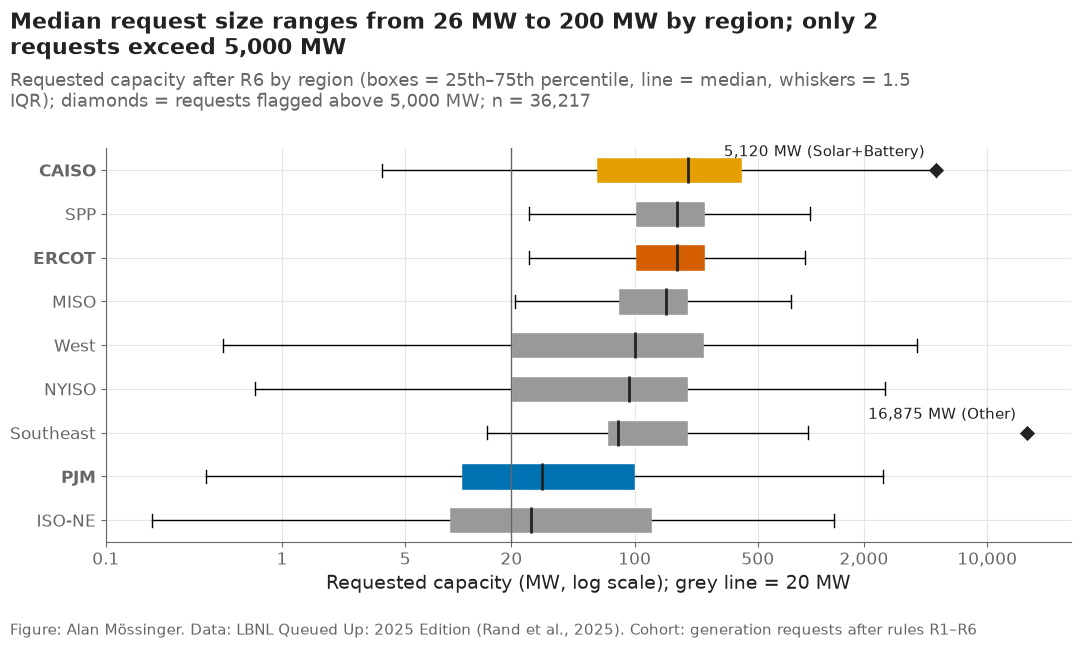

,count,mean,std,min,25%,50%,75%,max
region,,,,,,,,
CAISO,2837.0,320.0,421.5,0.0,60.7,200.0,408.5,5120.0
ERCOT,3277.0,208.1,210.7,0.3,100.0,174.6,250.0,3200.0
ISO-NE,1279.0,117.7,216.9,0.0,8.8,26.0,126.0,1350.0
MISO,4929.0,182.0,196.7,0.5,80.0,150.0,200.0,3576.0
NYISO,1817.0,200.2,325.8,0.5,20.0,92.8,200.0,2620.0
PJM,8099.0,106.7,209.6,0.0,10.4,30.0,100.0,2562.7
SPP,2388.0,197.6,175.8,0.1,100.0,175.0,250.0,4000.0
Southeast,3916.0,205.0,397.7,0.1,70.0,80.0,200.0,16875.0
West,7675.0,185.5,266.9,0.0,20.0,100.0,248.4,4000.0


In [52]:
sized = step6.copy()
fig, ax = plt.subplots()
regions = sized.groupby("region")["mw"].median().sort_values().index
box = ax.boxplot([np.log10(sized.loc[sized["region"] == r, "mw"]) for r in regions],
                 orientation="horizontal", tick_labels=regions, showfliers=False, widths=0.6,
                 patch_artist=True, medianprops={"color": plots.INK, "linewidth": 2})
for patch, region in zip(box["boxes"], regions):
    patch.set_facecolor(plots.region_color(region))
    patch.set_edgecolor("white")
large = sized[sized["mw_large"]]
ax.scatter(np.log10(large["mw"]), [list(regions).index(r) + 1 for r in large["region"]],
           color=plots.INK, marker="D", s=60, zorder=3)
for _, row in large.iterrows():
    ax.annotate(f"{row['mw']:,.0f} MW ({row['type_clean']})",
                (np.log10(row["mw"]), list(regions).index(row["region"]) + 1),
                xytext=(-8, 10), textcoords="offset points", ha="right", fontsize=11)
ax.axvline(np.log10(config.FERC_SIZE_STEP_MW), color=plots.MUTED, linewidth=1)
ticks = [0.1, 1, 5, 20, 100, 500, 2000, 10000]
ax.set_xticks(np.log10(ticks), [f"{t:,}" for t in ticks])
ax.set_xlabel("Requested capacity (MW, log scale); grey line = 20 MW")
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
plots.finish(fig,
             f"Median request size ranges from {sized.groupby('region')['mw'].median().min():.0f} MW to "
             f"{sized.groupby('region')['mw'].median().max():.0f} MW by region; only "
             f"{int(sized['mw_large'].sum())} requests exceed 5,000 MW",
             "Requested capacity after R6 by region (boxes = 25th–75th percentile, line = median, whiskers = "
             f"1.5 IQR); diamonds = requests flagged above 5,000 MW; n = {len(sized):,}",
             "generation requests after rules R1–R6")
save(fig, "02_03_capacity_by_region",
     "Distribution of requested capacity (MW, log scale) by region after rule R6, with the two requests "
     "above 5,000 MW marked.")
plt.show()
sized.groupby("region")["mw"].describe().round(1)

**Reading this.** Before R6, 16 rows have a non-positive capacity (the raw file has 17; the 17th was an Upgrade request already removed by R5); after R6 there are none. Two requests exceed 5,000 MW and are flagged, not dropped: a withdrawn 16,875 MW "Other" request in Mississippi from 1999 with no project name — implausible as one plant — and the active 5,120 MW ATLAS COMPLEX solar+battery hybrid in CAISO (3,200 + 1,920 MW), which is plausible. Median request size ranges from 26 MW in ISO-NE and 30 MW in PJM to 200 MW in CAISO; PJM and ISO-NE have many requests below the 20 MW line, so the size regime will matter most there.

## 8. R7 — one key per project

**What:** `project_key = entity | q_id`; where a key repeats, the copy without a
request date is dropped. **Why:** `q_id` alone repeats across transmission
providers, and later notebooks join tables on the key, so it must be unique.

In [53]:
key = step6["entity"].astype(str) + "|" + step6["q_id"].astype(str)
pair = step6[key.duplicated(keep=False)]
step7 = cleaning.apply_rule(cleaning.r7_project_key, step6, log)
print("Key unique after R7:", step7["project_key"].is_unique)
pair[["q_id", "entity", "region", "project_name", "q_status", "q_date", "on_date", "IA_status_clean", "mw"]]

Key unique after R7: True


,q_id,entity,region,project_name,q_status,q_date,on_date,IA_status_clean,mw
12045,505,NYISO,NYISO,Ball Hill Wind,operational,2015-06-02,NaT,Facility Study,103.0
35181,505,NYISO,NYISO,Ball Hill Wind,operational,NaT,2023-10-31,Operational,103.0


**Reading this.** One key repeats: NYISO request 505, "Ball Hill Wind" (103 MW). One copy has the request date (2015-06-02) but no operation date; the other has the operation date (2023-10-31) but no request date. R7 drops the second copy, so the project now counts once; the copy kept is operational but without an operation date. NYISO is not in the timing model, so this matters only for Track B.

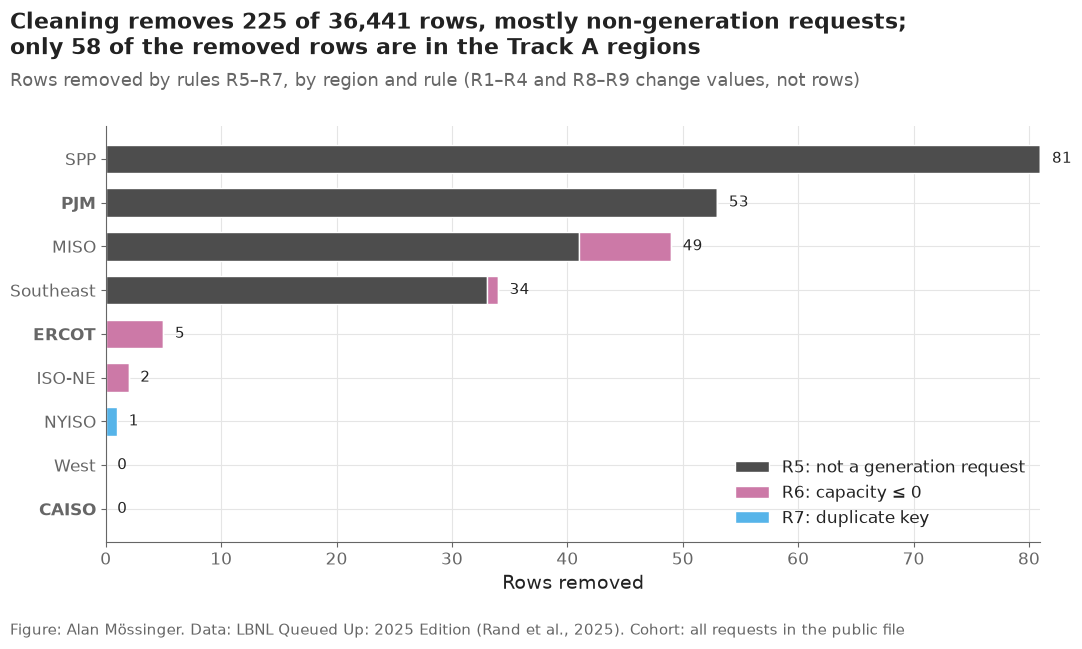

region,CAISO,West,NYISO,ISO-NE,ERCOT,Southeast,MISO,PJM,SPP
R5: not a generation request,0,0,0,0,0,33,41,53,81
R6: capacity ≤ 0,0,0,0,2,5,1,8,0,0
R7: duplicate key,0,0,1,0,0,0,0,0,0


In [54]:
removed = []
for frame_before, frame_after, rule in [(step4, step5, "R5: not a generation request"),
                                        (step5, step6, "R6: capacity ≤ 0"),
                                        (step6, step7, "R7: duplicate key")]:
    gone = frame_before.loc[~frame_before.index.isin(frame_after.index)]
    removed.append(gone["region"].value_counts().rename(rule))
removed = pd.concat(removed, axis=1).reindex(config.ALL_REGIONS).fillna(0).astype(int)
removed = removed.loc[removed.sum(axis=1).sort_values().index]

rule_colors = ["#4D4D4D", config.OUTCOME_COLORS["withdrawal"], "#56B4E9"]
fig, ax = plt.subplots()
left = np.zeros(len(removed))
for column, color in zip(removed.columns, rule_colors):
    ax.barh(removed.index, removed[column], left=left, color=color, height=0.65, label=column,
            edgecolor="white", linewidth=1)
    left += removed[column].values
for i, total in enumerate(removed.sum(axis=1)):
    ax.text(total + 1, i, f"{total}", va="center", fontsize=11)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlabel("Rows removed")
ax.legend(loc="lower right")
plots.finish(fig,
             f"Cleaning removes {int(removed.values.sum())} of {len(raw):,} rows, mostly non-generation "
             f"requests; only {int(removed.loc[TRACK_A].values.sum())} of the removed rows are in the Track A regions",
             "Rows removed by rules R5–R7, by region and rule (R1–R4 and R8–R9 change values, not rows)",
             "all requests in the public file")
save(fig, "02_04_rows_removed_by_region",
     "Number of rows removed by cleaning rules R5, R6 and R7, by region.")
plt.show()
removed.T

**Reading this.** Cleaning removes 225 rows: 208 by R5, 16 by R6 and 1 by R7. SPP loses the most (81, all non-generation). In the Track A regions only 58 rows go — 53 PJM upgrades and 5 ERCOT rows with non-positive capacity — and CAISO loses none, so the timing sample is barely touched by row removals; its real losses come from missing dates.

## 9. R8 — sparse fields

**What:** `developer` and `cluster` are dropped; missing `service` and `county`
become an explicit "missing" level. **Why:** the first two are blank for most
rows; the last two are useful but often blank, and a "missing" level keeps
those rows in the models.

In [55]:
sparse = step7.groupby("region")[["developer", "cluster", "service", "county"]].agg(
    lambda s: s.notna().mean()).reindex(config.ALL_REGIONS)
step8 = cleaning.apply_rule(cleaning.r8_sparse_fields, step7, log)
print("Columns dropped:", sorted(set(step7.columns) - set(step8.columns)))
(100 * sparse).round(1).rename(columns=lambda c: f"{c} filled (%)")

Columns dropped: ['cluster', 'developer']


,developer filled (%),cluster filled (%),service filled (%),county filled (%)
region,,,,
ERCOT,92.5,0.0,0.8,100.0
PJM,0.0,0.0,99.8,98.5
CAISO,0.0,80.4,75.3,88.9
MISO,0.0,63.8,85.0,65.2
SPP,0.0,65.3,92.8,98.7
NYISO,100.0,20.7,0.0,95.3
ISO-NE,0.0,3.6,69.9,96.2
West,11.9,18.7,88.1,99.4
Southeast,24.7,15.0,74.4,99.1


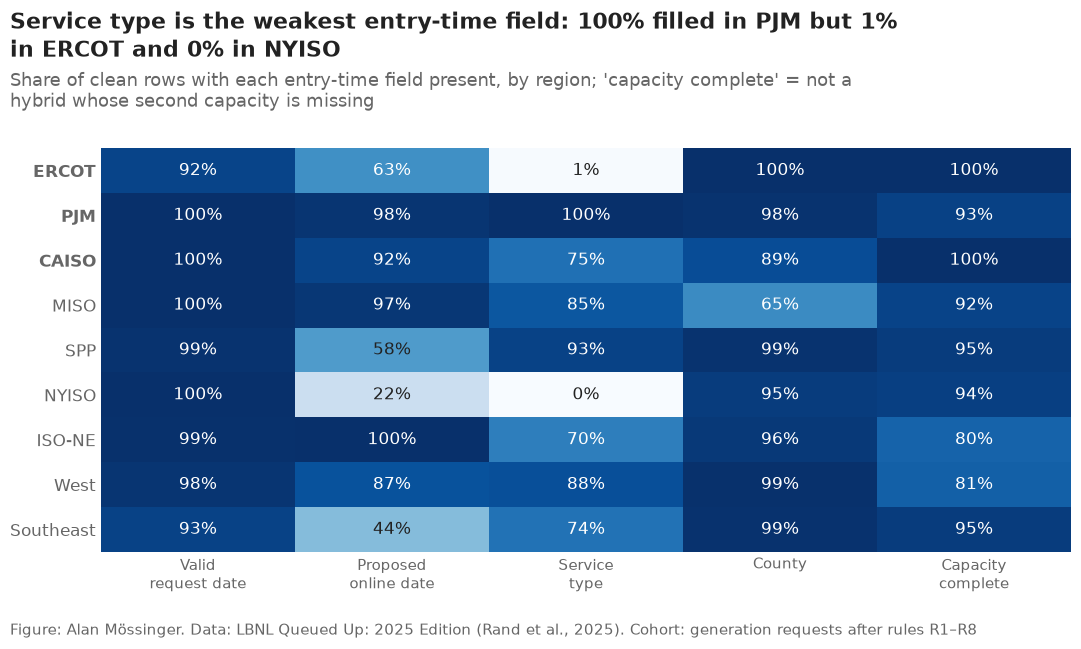

,Valid request date,Proposed online date,Service type,County,Capacity complete
region,,,,,
ERCOT,91.8,63.0,0.8,100.0,100.0
PJM,99.7,98.0,99.8,98.5,93.1
CAISO,99.8,92.0,75.3,88.9,99.9
MISO,99.7,97.2,85.0,65.2,92.2
SPP,98.7,58.4,92.8,98.7,95.1
NYISO,100.0,22.1,0.0,95.3,93.9
ISO-NE,99.3,99.7,69.9,96.2,80.1
West,97.8,87.0,88.1,99.4,81.5
Southeast,92.7,43.5,74.4,99.1,94.9


In [56]:
fields = {"Valid request date": step8["q_date"].notna(),
          "Proposed online date": step8["prop_date"].notna(),
          "Service type": step8["service"] != "missing",
          "County": step8["county"] != "missing",
          "Capacity complete": ~(step8["type2"].notna() & step8["mw2"].isna())}
filled = pd.DataFrame(fields).groupby(step8["region"]).mean().reindex(config.ALL_REGIONS)

fig, ax = plt.subplots()
ax.imshow(filled.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(filled.shape[1]), [c.replace(" ", "\n", 1) for c in filled.columns], fontsize=11)
ax.set_yticks(range(filled.shape[0]), filled.index)
ax.grid(False)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(filled.shape[0]):
    for j in range(filled.shape[1]):
        value = filled.iat[i, j]
        ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=12,
                color="white" if value > 0.6 else plots.INK)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
worst = filled["Service type"].idxmin()
plots.finish(fig,
             f"Service type is the weakest entry-time field: {filled.loc['PJM', 'Service type']:.0%} filled in "
             f"PJM but {filled.loc['ERCOT', 'Service type']:.0%} in ERCOT and {filled['Service type'].min():.0%} in {worst}",
             "Share of clean rows with each entry-time field present, by region; 'capacity complete' = not a "
             "hybrid whose second capacity is missing",
             "generation requests after rules R1–R8")
save(fig, "02_05_feature_completeness_by_region",
     "Share of clean rows with each entry-time field present, by region.")
plt.show()
(100 * filled).round(1)

**Reading this.** `developer` and `cluster` are dropped (6,724 and 9,424 values). The table shows how uneven they were: `developer` is 92.5% filled in ERCOT and 100% in NYISO but 0% in PJM, CAISO and MISO; `cluster` is 80.4% filled in CAISO and empty in ERCOT and PJM. They could only ever be used inside a single region. 8,998 `service` values and 2,398 `county` values become "missing". Figure 02_05 shows what this means for features: service type is 99.8% filled in PJM but 0.8% in ERCOT and 0.0% in NYISO, so inside ERCOT it carries no information; the proposed online date is thin in NYISO (22.1%) and the Southeast (43.5%), on top of the leakage question from notebook 01.

## 10. R9 — hybrids

**What:** `hybrid = type2 is present`; `type_clean` stays as LBNL standardised
it. **Why:** hybrid composition is a feature, and LBNL warns that hybrid
storage capacity is estimated for some projects (sheet 13, note 2), so the
notebook also counts hybrids with no second capacity at all.

In [57]:
step9 = cleaning.apply_rule(cleaning.r9_hybrid, step8, log)
hyb = step9.groupby("region").agg(requests=("hybrid", "size"), hybrids=("hybrid", "sum"))
hyb["hybrid share"] = hyb["hybrids"] / hyb["requests"]
hyb["hybrids without mw2"] = step9[step9["hybrid"]].groupby("region")["mw2"].apply(lambda s: s.isna().sum())
hyb["share of hybrids without mw2"] = hyb["hybrids without mw2"] / hyb["hybrids"]
hyb = hyb.reindex(config.ALL_REGIONS).fillna(0)
hyb.round(3)

,requests,hybrids,hybrid share,hybrids without mw2,share of hybrids without mw2
region,,,,,
ERCOT,3277,0,0.000,0.0,0.000
PJM,8099,557,0.069,557.0,1.000
CAISO,2837,718,0.253,4.0,0.006
MISO,4929,382,0.078,382.0,1.000
SPP,2388,118,0.049,118.0,1.000
NYISO,1816,110,0.061,110.0,1.000
ISO-NE,1279,254,0.199,254.0,1.000
West,7675,1699,0.221,1421.0,0.836
Southeast,3916,350,0.089,198.0,0.566


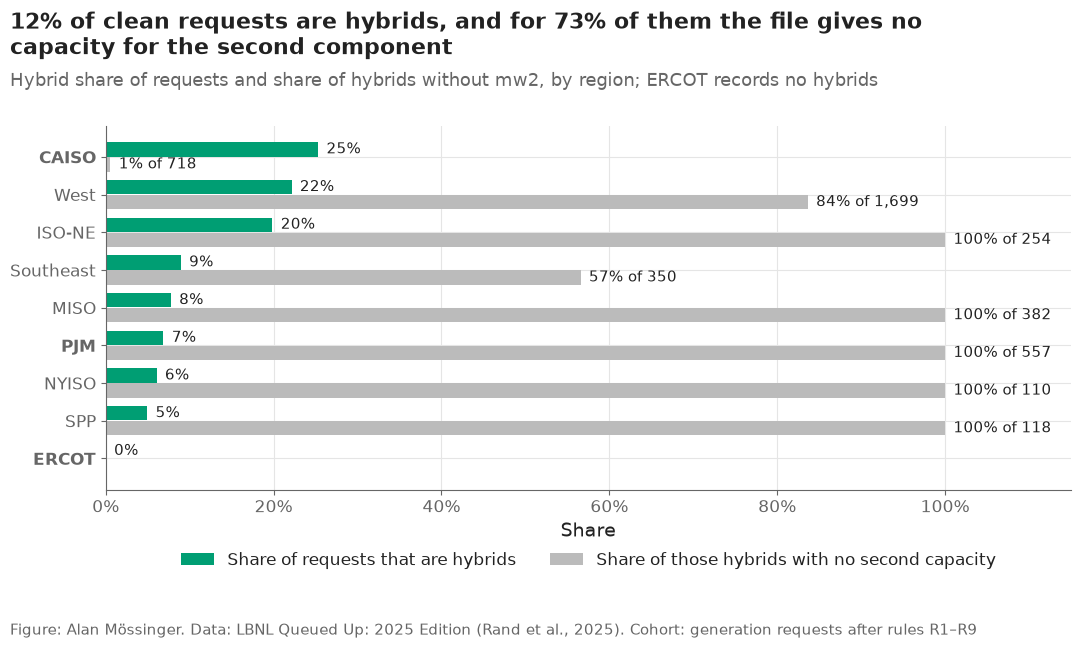

In [58]:
fig, ax = plt.subplots()
order = hyb.sort_values("hybrid share").index
y = np.arange(len(order))
ax.barh(y + 0.2, hyb.loc[order, "hybrid share"], height=0.38, color=config.TECH_COLORS["Solar+Battery"],
        label="Share of requests that are hybrids")
ax.barh(y - 0.2, hyb.loc[order, "share of hybrids without mw2"], height=0.38, color="#BBBBBB",
        label="Share of those hybrids with no second capacity")
for i, region in enumerate(order):
    ax.text(hyb.loc[region, "hybrid share"] + 0.01, i + 0.2, f"{hyb.loc[region, 'hybrid share']:.0%}",
            va="center", fontsize=11)
    if hyb.loc[region, "hybrids"] > 0:
        ax.text(hyb.loc[region, "share of hybrids without mw2"] + 0.01, i - 0.2,
                f"{hyb.loc[region, 'share of hybrids without mw2']:.0%} of {int(hyb.loc[region, 'hybrids']):,}",
                va="center", fontsize=11)
ax.set_yticks(y, order)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlim(0, 1.15)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Share")
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
total_share = step9["hybrid"].mean()
no_mw2 = (step9["hybrid"] & step9["mw2"].isna()).sum() / step9["hybrid"].sum()
plots.finish(fig,
             f"{total_share:.0%} of clean requests are hybrids, and for {no_mw2:.0%} of them the file gives "
             "no capacity for the second component",
             "Hybrid share of requests and share of hybrids without mw2, by region; ERCOT records no hybrids",
             "generation requests after rules R1–R9")
save(fig, "02_06_hybrids_by_region",
     "Share of requests that are hybrids, and share of hybrids without a second-component capacity, by region.")
plt.show()

**Reading this.** 4,188 clean requests are hybrids (12%). For 3,044 of them (73%) the file gives no capacity for the second component, so their `mw` is the first component only. The gap is regional: CAISO reports the second capacity for all but 4 of its 718 hybrids, the West lacks it for 84% (1,421 of 1,699), and PJM, MISO, SPP, NYISO and ISO-NE lack it for every hybrid. ERCOT records no hybrids at all. Together with LBNL's note that hybrid storage capacity is estimated for some projects, this makes `mw` a reliable size for single-technology projects but only a lower bound for most hybrids. For notebook 04 I propose using the first component's capacity for size and the hybrid flag for composition, rather than relying on hybrid totals.

## 11. Summary, save, and checks

The clean table is saved with text columns stored as text (some LBNL columns
mix numbers and names, which parquet cannot hold in one column). Then the
acceptance checks of PLAN.md §6 (notebook 02) are run and the rule counts are
compared with the rule table in PLAN.md §7.

In [59]:
clean = step9
clean_log = pd.DataFrame(log)
clean_log.to_csv(paths.RESULTS / "clean_log.csv", index=False)
text_columns = [c for c in clean.columns if clean[c].dtype == object]
clean.astype({c: "string" for c in text_columns}).to_parquet(
    paths.DATA_INTERIM / "queue_clean.parquet", index=False)
print(f"Rows in: {len(raw):,} → rows out: {len(clean):,} ({len(raw) - len(clean)} removed)")
print("Columns:", clean.shape[1])
clean_log[["rule", "item", "rows", "rows_in", "rows_out"]]

Rows in: 36,441 → rows out: 36,216 (225 removed)
Columns: 33


,rule,item,rows,rows_in,rows_out
0,R1,q_date converted,35834,36441,36441
1,R1,prop_date converted,29029,36441,36441
2,R1,on_date converted,2957,36441,36441
3,R1,wd_date converted,10138,36441,36441
4,R1,ia_date converted,2440,36441,36441
5,R2,q_date placeholder set to missing,204,36441,36441
6,R2,ia_date placeholder set to missing,56,36441,36441
7,R2,q_year changed by recomputing it from q_date,204,36441,36441
8,R3,on_date cleared: status is not operational,596,36441,36441
9,R3,on_date cleared: before the request date,69,36441,36441


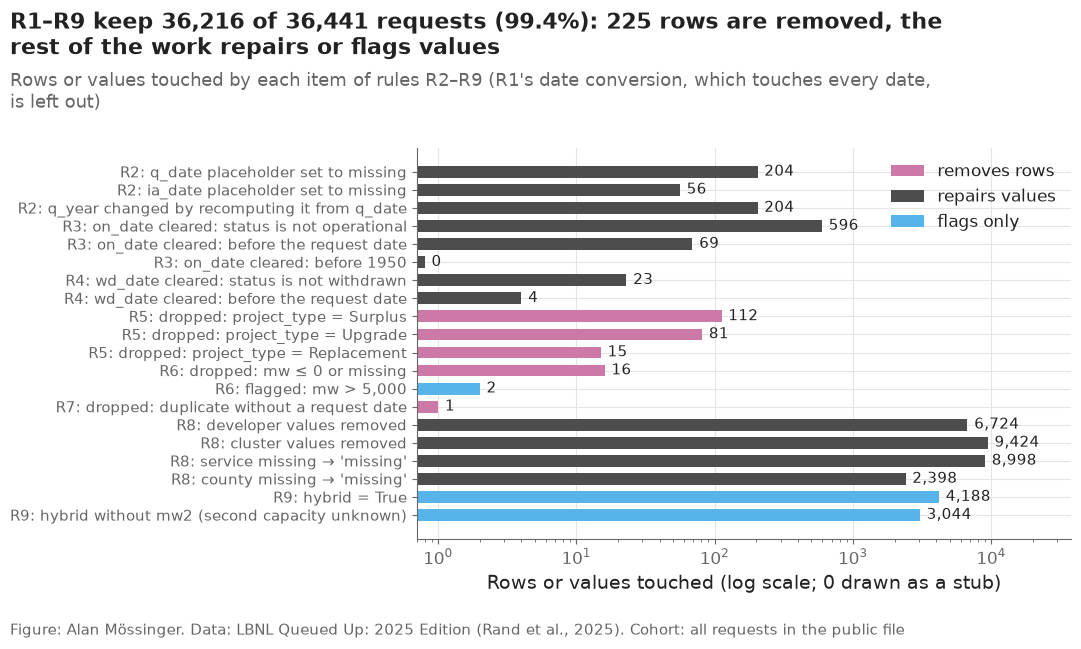

In [60]:
items = clean_log[(clean_log["rule"] != "R1") & (clean_log["item"] != "rows sharing a key")].copy()
items["kind"] = np.select([items["item"].str.startswith("dropped"),
                           items["item"].str.startswith(("flagged", "hybrid"))],
                          ["removes rows", "flags only"], default="repairs values")
items["label"] = items["rule"] + ": " + items["item"]
kind_colors = {"removes rows": config.OUTCOME_COLORS["withdrawal"], "repairs values": "#4D4D4D",
               "flags only": "#56B4E9"}

fig, ax = plt.subplots()
y = np.arange(len(items))[::-1]
ax.barh(y, items["rows"].clip(lower=0.8), color=items["kind"].map(kind_colors), height=0.65)
for yi, value in zip(y, items["rows"]):
    ax.text(max(value, 0.8) * 1.12, yi, f"{value:,}", va="center", fontsize=10.5)
ax.set_yticks(y, items["label"], fontsize=10.5)
ax.set_xscale("log")
ax.set_xlim(0.7, items["rows"].max() * 4)
ax.set_xlabel("Rows or values touched (log scale; 0 drawn as a stub)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in kind_colors.items()],
          loc="upper right")
plots.finish(fig,
             f"R1–R9 keep {len(clean):,} of {len(raw):,} requests ({len(clean) / len(raw):.1%}): "
             f"{len(raw) - len(clean)} rows are removed, the rest of the work repairs or flags values",
             "Rows or values touched by each item of rules R2–R9 (R1's date conversion, which touches every "
             "date, is left out)",
             "all requests in the public file")
save(fig, "02_07_rules_summary",
     "Number of rows or values touched by each item of cleaning rules R2–R9, by kind of action.")
plt.show()

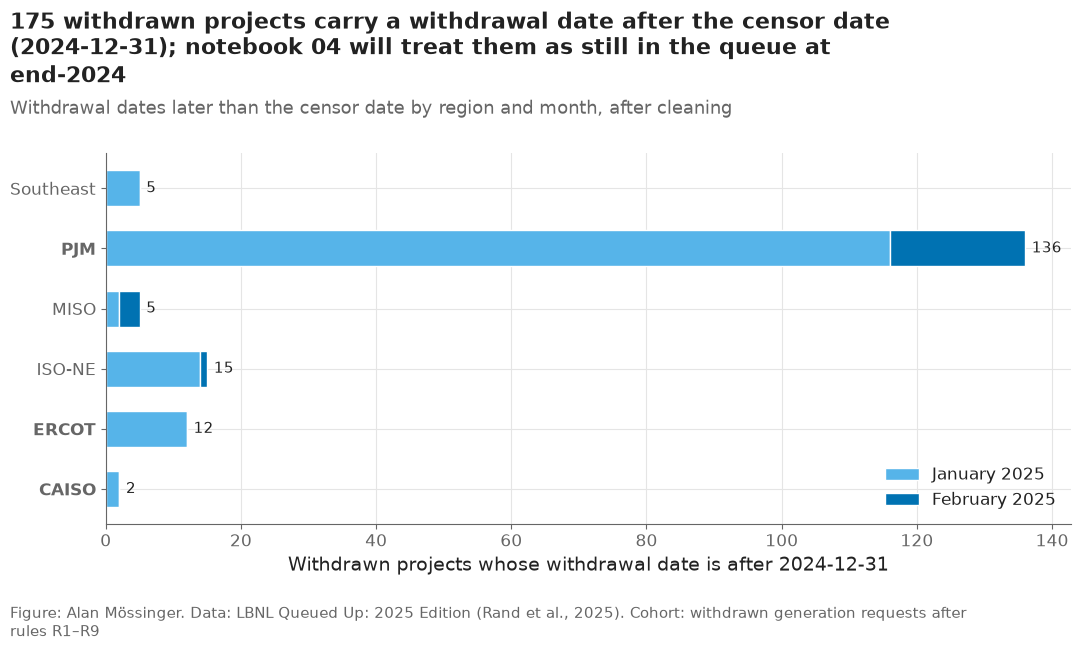

wd_date,2025-01,2025-02
region,,
CAISO,2,0
ERCOT,12,0
ISO-NE,14,1
MISO,2,3
PJM,116,20
Southeast,5,0


In [61]:
censor = pd.Timestamp(config.CENSOR_DATE)
late = clean[clean["wd_date"] > censor]
late_by = late.groupby([late["region"], late["wd_date"].dt.to_period("M")]).size().unstack(fill_value=0)

fig, ax = plt.subplots()
left = np.zeros(len(late_by))
month_colors = ["#56B4E9", "#0072B2", "#4D4D4D"]
for column, color in zip(late_by.columns, month_colors):
    ax.barh(late_by.index, late_by[column], left=left, color=color, height=0.6,
            label=column.strftime("%B %Y"), edgecolor="white", linewidth=1)
    left += late_by[column].values
for i, total in enumerate(late_by.sum(axis=1)):
    ax.text(total + 1, i, f"{total}", va="center", fontsize=11)
for label in ax.get_yticklabels():
    if label.get_text() in TRACK_A:
        label.set_fontweight("bold")
ax.set_xlabel("Withdrawn projects whose withdrawal date is after 2024-12-31")
ax.legend(loc="lower right")
plots.finish(fig,
             f"{len(late)} withdrawn projects carry a withdrawal date after the censor date (2024-12-31); "
             "notebook 04 will treat them as still in the queue at end-2024",
             "Withdrawal dates later than the censor date by region and month, after cleaning",
             "withdrawn generation requests after rules R1–R9")
save(fig, "02_08_withdrawals_after_censor_date",
     "Withdrawn projects whose withdrawal date falls after the 2024-12-31 censor date, by region and month.")
plt.show()
late_by

**Reading this.** 175 withdrawn projects (136 of them in PJM) have a withdrawal date in January or February 2025, after the censor date, although the file describes the queues at the end of 2024. On 2024-12-31 these projects were still in the queue, so notebook 04 will censor them at that date instead of counting a withdrawal; otherwise PJM's withdrawal hazard just before the censor date would be overstated.

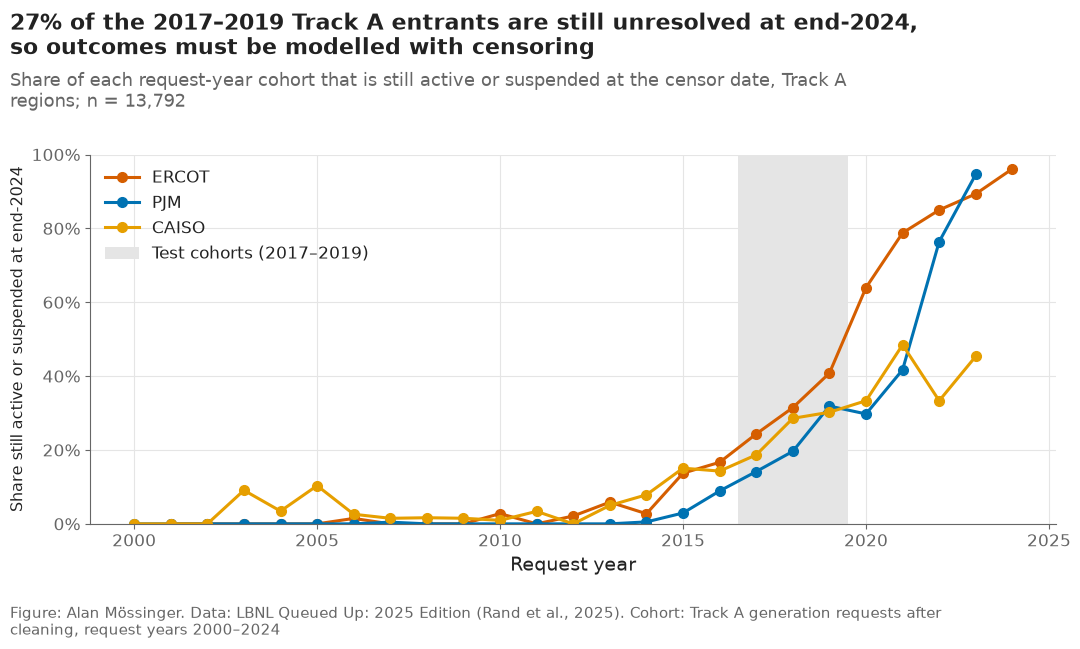

q_year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
region,,,,,,,,,,,,,,,
CAISO,0.9,3.4,0.0,5.0,7.9,15.1,14.3,18.7,28.6,30.2,33.3,48.5,33.3,45.4,NaN
ERCOT,2.8,0.0,2.1,5.9,2.7,13.7,16.7,24.3,31.5,40.8,64.0,78.8,85.0,89.3,96.1
PJM,0.0,0.0,0.0,0.0,0.5,2.9,8.9,14.2,19.6,31.9,29.8,41.7,76.4,94.6,NaN


In [62]:
track_a = clean[clean["region"].isin(TRACK_A) & clean["q_year"].between(2000, 2024)]
open_share = (track_a.assign(open=track_a["q_status"].isin(["active", "suspended", "unknown"]))
              .groupby(["q_year", "region"])["open"].mean().unstack())

fig, ax = plt.subplots()
for region in TRACK_A:
    ax.plot(open_share.index, open_share[region], color=plots.region_color(region), marker="o", label=region)
ax.axvspan(config.TEST_YEARS[0] - 0.5, config.TEST_YEARS[1] + 0.5, color="#E5E5E5", zorder=0,
           label="Test cohorts (2017–2019)")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.set_xlabel("Request year")
ax.set_ylabel("Share still active or suspended at end-2024")
ax.legend(loc="upper left")
test_open = track_a[track_a["q_year"].between(*config.TEST_YEARS)]
test_open_share = test_open["q_status"].isin(["active", "suspended", "unknown"]).mean()
plots.finish(fig,
             f"{test_open_share:.0%} of the 2017–2019 Track A entrants are still unresolved at end-2024, "
             "so outcomes must be modelled with censoring",
             "Share of each request-year cohort that is still active or suspended at the censor date, Track A "
             f"regions; n = {len(track_a):,}",
             "Track A generation requests after cleaning, request years 2000–2024")
save(fig, "02_09_unresolved_share_by_cohort",
     "Share of each request-year cohort still active or suspended at the end of 2024, for CAISO, ERCOT and PJM.")
plt.show()
(100 * open_share.loc[2010:]).round(1).T

**Reading this.** The share still unresolved rises steeply with the request year. Within the 2017–2019 test cohorts it is 18.7–30.2% in CAISO, 24.3–40.8% in ERCOT and 14.2–31.9% in PJM; 27% overall. Counting these projects as failures would bias completion downwards, and dropping them would bias it towards fast projects. This is the practical case for time-to-event methods with censoring (notebooks 03–06), and the reason the 7-year horizon can only be evaluated on the 2017 cohort.

The rule table in PLAN.md §7 states six counts, all measured on the raw file.
They are compared on the same rows: for R6 that means checking that all raw
rows with `mw ≤ 0` are gone (one of them is an Upgrade request, so R5 removes
it before R6 sees it). The ">5,000 MW" count is a flag, not a removal; it is
reported but not part of the pass condition, because the plan's "one row" is
simply a miscount that this notebook corrects.

In [63]:
observed = dict(zip(clean_log["item"], clean_log["rows"]))
raw_mw = raw[["mw1", "mw2", "mw3"]].sum(axis=1, min_count=1)
nonpositive_removed = int((~raw.index[raw_mw <= 0].isin(clean.index)).sum())
plan_table = pd.DataFrame([
    ("R2", "request dates that are the 1970-01-01 placeholder", 204,
     observed["q_date placeholder set to missing"], True, ""),
    ("R3", "operation dates on non-operational rows", 596,
     observed["on_date cleared: status is not operational"], True, ""),
    ("R3", "operation dates before the request date", 69,
     observed["on_date cleared: before the request date"], True, ""),
    ("R5–R6", "raw rows with mw ≤ 0 that are removed", 17, nonpositive_removed, True,
     f"{observed['dropped: mw ≤ 0 or missing']} by R6; the other is an Upgrade row removed by R5"),
    ("R7", "duplicate key pairs resolved", 1, observed["dropped: duplicate without a request date"], True, ""),
    ("R6", "requests flagged above 5,000 MW", 1, observed["flagged: mw > 5,000"], False,
     "flag only; the plan names the 16,875 MW row, but a 5,120 MW CAISO hybrid also exceeds 5,000"),
], columns=["rule", "item", "plan", "observed", "in pass condition", "note"])
plan_table["equal"] = plan_table["plan"] == plan_table["observed"]

checks = pd.DataFrame([
    ("no serial-number dates", all(pd.api.types.is_datetime64_any_dtype(clean[c]) for c in DATE_COLS)),
    ("no on_date on non-operational rows", bool(clean.loc[clean["q_status"] != "operational", "on_date"].isna().all())),
    ("no wd_date on non-withdrawn rows", bool(clean.loc[clean["q_status"] != "withdrawn", "wd_date"].isna().all())),
    ("no event date before its request date", not bool(((clean["on_date"] < clean["q_date"]) |
                                                        (clean["wd_date"] < clean["q_date"])).any())),
    ("no non-positive MW", bool((clean["mw"] > 0).all())),
    ("project_key unique", bool(clean["project_key"].is_unique)),
    ("row counts equal the plan's rule table",
     bool(plan_table.loc[plan_table["in pass condition"], "equal"].all())),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(paths.RESULTS / "clean_checks.csv", index=False)
print(checks[["check", "result"]].to_string(index=False))
plan_table

                                 check result
                no serial-number dates   PASS
    no on_date on non-operational rows   PASS
      no wd_date on non-withdrawn rows   PASS
 no event date before its request date   PASS
                    no non-positive MW   PASS
                    project_key unique   PASS
row counts equal the plan's rule table   PASS


,rule,item,plan,observed,in pass condition,note,equal
0,R2,request dates that are the 1970-01-01 placeholder,204,204,True,,True
1,R3,operation dates on non-operational rows,596,596,True,,True
2,R3,operation dates before the request date,69,69,True,,True
3,R5–R6,raw rows with mw ≤ 0 that are removed,17,17,True,16 by R6; the other is an Upgrade row removed ...,True
4,R7,duplicate key pairs resolved,1,1,True,,True
5,R6,"requests flagged above 5,000 MW",1,2,False,"flag only; the plan names the 16,875 MW row, b...",False


**Reading this.** All seven checks pass: dates are real dates, event dates agree with the status and never precede the request, every capacity is positive and the project key is unique. Of the six counts in the plan's rule table, the five that clear or remove something are reproduced exactly (204, 596, 69, 17 and 1). The sixth was a miscount in the plan: two requests exceed 5,000 MW, not one, and both are flagged rather than removed. `tests/test_cleaning.py` pins all of these counts.

## Takeaways — Part B

- R1–R9 keep 36,216 of 36,441 requests. 225 rows are removed (208 non-generation requests, 16 with non-positive capacity, 1 duplicate), and 692 event dates that contradicted the status or the request date are cleared.
- The plan's rule-table counts reproduce exactly (204, 596, 69, 17, 1); its "one request above 5,000 MW" is in fact two, both flagged and kept.
- Feature caveats for notebook 04: service type is empty in ERCOT and NYISO; 73% of hybrids have no second-component capacity (every hybrid in PJM, MISO, SPP, NYISO and ISO-NE); ERCOT records no hybrids.
- 175 withdrawal dates fall after the censor date (136 in PJM) and will be censored in notebook 04; 27% of the 2017–2019 Track A entrants are still unresolved, so censoring is central to every model.

**What goes to the report:** one paragraph on cleaning in the data section (rows in and out, the date conflicts R3–R4 resolve), 02_09 as the one-figure case for censoring if space allows, and the hybrid-capacity gap in the limitations.

# Part C — The LBNL 2026 data file beside the frozen 2025 file (was notebook 01b)

The project's registered results stand on the 2025 edition of the LBNL queue file (data through 2024, frozen; decision #2). The 2026 edition (data through 2025) is added alongside (decision #43) for two uses: to see how the same requests changed between editions — the file is a snapshot of snapshots, so statuses and even dates move — and to read the 1- and 2-year outcomes of the 2020–2022 entrants, the newest evidence on the level of completion that notebook 12 needs. No model is fitted on this file here.

## Setup

In [64]:
import hashlib
import re
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import cleaning, config, drift, events, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "01_problem_and_data"
TRACK_A = config.TRACK_A_REGIONS
CENSOR_2026 = "2025-12-31"  # end of data collection of the 2026 edition
KEY = ["q_id", "entity", "region"]


def save(fig, name, caption):
    """Save a figure of this notebook under figures/01_problem_and_data/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

## 1. Both files, as published

The 2026 file is checked against the SHA-256 recorded in `src/config.py` and loaded from the same sheet and header row as the 2025 file. The column differences are listed, and the 2026 names are mapped back to the 2025 names the pipeline uses (`config.LBNL_2026_RENAMES`).

In [65]:
path_2026 = paths.RAW_LBNL / config.LBNL_2026_FILENAME
digest = hashlib.sha256(path_2026.read_bytes()).hexdigest()
assert digest == config.LBNL_2026_SHA256, "the 2026 file on disk is not the one recorded in src/config.py"

raw_2025 = pd.read_excel(paths.RAW_LBNL / config.LBNL_FILENAME, sheet_name=config.LBNL_SHEET, header=config.LBNL_HEADER_ROW)
raw_2026 = pd.read_excel(path_2026, sheet_name=config.LBNL_SHEET, header=config.LBNL_HEADER_ROW)
layout = pd.DataFrame({
    "column": sorted(set(raw_2025.columns) | set(raw_2026.columns)),
}).assign(in_2025=lambda d: d["column"].isin(raw_2025.columns), in_2026=lambda d: d["column"].isin(raw_2026.columns))
layout["mapped_to"] = layout["column"].map(config.LBNL_2026_RENAMES)
layout.to_csv(paths.RESULTS / "lbnl_2026_layout.csv", index=False)
raw_2026 = raw_2026.rename(columns=config.LBNL_2026_RENAMES)
for column in config.LBNL_DATE_COLS:
    assert pd.api.types.is_datetime64_any_dtype(raw_2026[column]), f"{column} is not a date in the 2026 file"
print(f"2025: {raw_2025.shape}; 2026: {raw_2026.shape}; SHA-256 of the 2026 file verified")
layout[~(layout["in_2025"] & layout["in_2026"])]

2025: (36441, 31); 2026: (38201, 30); SHA-256 of the 2026 file verified


,column,in_2025,in_2026,mapped_to
0,IA_phase_clean,False,True,IA_status_clean
1,IA_phase_raw,False,True,IA_status_raw
2,IA_status_clean,True,False,NaN
3,IA_status_raw,True,False,NaN
6,county_state_pairs,True,False,NaN
9,fips_code,False,True,fips_codes
10,fips_codes,True,False,NaN
12,mw1,True,False,NaN
13,mw2,True,False,NaN
14,mw3,True,False,NaN


**Reading this.** The 2026 edition has 38,201 rows against 36,441, and the same sheet and header row. Nine columns were renamed (the interconnection-agreement status fields are now "phase", the FIPS and the type/MW components carry underscores), `county_state_pairs` is gone, and the five date columns arrive as dates rather than Excel serial numbers, so rule R1 has nothing to do. Nothing in the mapping changes a value.

## 2. Cleaning the 2026 file with the same rules

Rules R2–R9 of notebook 02 run unchanged (`src/cleaning.py`); R1 is skipped because the 2026 file stores real dates, not Excel serials. One step is particular to the 2026 file: it lists 135 operational NYISO and Southeast projects twice, the second copy appended at the end of the sheet without county or operation date, so the emptier copy of each pair is dropped before R7 (which would otherwise refuse the file, as it should for the frozen one). The rule log is written beside notebook 02's so the two can be compared.

In [66]:
log = []
# 2026-only: duplicate (q_id, entity) rows — keep the copy with the most filled fields
with_key = raw_2026.assign(_q=raw_2026["q_id"].astype(str), _filled=raw_2026.notna().sum(axis=1))
with_key = with_key.sort_values("_filled", ascending=False)
dup = with_key.duplicated(["_q", "entity"], keep="first")
dropped = with_key[dup]
log.append({"rule": "R7a", "function": "drop_appended_duplicates_2026", "item": "dropped: emptier copy of a duplicated key",
            "rows": int(dup.sum()), "rows_in": len(raw_2026), "rows_out": int((~dup).sum())})
print(f"appended duplicates dropped: {int(dup.sum())} rows, regions {dropped['region'].value_counts().to_dict()}, "
      f"status {dropped['q_status'].value_counts().to_dict()}")
frame = with_key[~dup].drop(columns=["_q", "_filled"]).sort_index()
for rule in cleaning.RULES[1:]:  # R2 … R9
    frame = cleaning.apply_rule(rule, frame, log)
clean_2026 = frame
for column in clean_2026.columns:
    if clean_2026[column].dtype == object:
        clean_2026[column] = clean_2026[column].astype("string")
clean_2026.to_parquet(paths.DATA_INTERIM / "queue_clean_2026.parquet")
log_2026 = pd.DataFrame(log)
log_2026.to_csv(paths.RESULTS / "clean_log_2026.csv", index=False)
log_2025 = pd.read_csv(paths.RESULTS / "clean_log.csv")
clean_2025 = pd.read_parquet(paths.DATA_INTERIM / "queue_clean.parquet")
compare = (log_2025.merge(log_2026, on=["rule", "item"], how="outer", suffixes=("_2025", "_2026"))
           [["rule", "item", "rows_2025", "rows_2026"]])
print(f"clean rows: 2025 {len(clean_2025):,}; 2026 {len(clean_2026):,}")
compare

appended duplicates dropped: 135 rows, regions {'NYISO': 104, 'Southeast': 31}, status {'operational': 135}


clean rows: 2025 36,216; 2026 37,849


,rule,item,rows_2025,rows_2026
0,R1,ia_date converted,2440.0,NaN
1,R1,on_date converted,2957.0,NaN
2,R1,prop_date converted,29029.0,NaN
3,R1,q_date converted,35834.0,NaN
4,R1,wd_date converted,10138.0,NaN
5,R2,ia_date placeholder set to missing,56.0,0.0
6,R2,q_date placeholder set to missing,204.0,0.0
7,R2,q_year changed by recomputing it from q_date,204.0,0.0
8,R3,on_date cleared: before 1950,0.0,0.0
9,R3,on_date cleared: before the request date,69.0,48.0


**Reading this.** The rules touch the two editions in the same places and in similar numbers: a few hundred operation dates cleared because the status is not operational (596 then, 420 now), the same 16 non-positive capacities, the same project-type drops. The 204 placeholder request dates of the 2025 file are gone. One step is new: 135 operational NYISO and Southeast projects appear twice in the 2026 sheet, the second copy without county or operation date, and the emptier copy is dropped. After cleaning: 36,216 rows in 2025, 37,849 in 2026.

## 3. The same requests in both editions

Requests are matched on (`q_id`, `entity`, `region`), the key the codebook names. Three things are counted: the share of 2025 requests found in 2026 (the readiness line asks for 95%), the status each request moved to, and — among requests whose status did not change — whether their recorded dates changed.

In [67]:
def keyed(frame):
    out = frame[KEY + ["q_status", "q_date", "on_date", "wd_date", "ia_date", "mw"]].copy()
    for column in KEY:
        out[column] = out[column].astype("string")
    return out.drop_duplicates(KEY)


a, b = keyed(clean_2025), keyed(clean_2026)
m = a.merge(b, on=KEY, how="left", suffixes=("_2025", "_2026"), indicator=True)
found = m["_merge"] == "both"
recon = (m.groupby("region").agg(requests_2025=("q_status_2025", "size"), found_in_2026=("_merge", lambda s: int((s == "both").sum())))
         .assign(share_found=lambda d: d["found_in_2026"] / d["requests_2025"]))
recon.loc["all"] = [len(m), int(found.sum()), found.mean()]
new_rows = b.merge(a, on=KEY, how="left", indicator=True).query("_merge == 'left_only'")
recon["new_in_2026"] = new_rows.groupby("region").size().reindex(recon.index).fillna(0).astype(int)
recon.loc["all", "new_in_2026"] = len(new_rows)
recon.to_csv(paths.RESULTS / "lbnl_2026_reconciliation.csv")
dup_2026 = int(clean_2026.duplicated(KEY).sum())
print(f"2025 requests found in 2026: {found.mean():.1%}; new 2026 rows: {len(new_rows):,}; duplicate keys in 2026: {dup_2026}")
recon.round(3)

2025 requests found in 2026: 96.9%; new 2026 rows: 2,759; duplicate keys in 2026: 0


,requests_2025,found_in_2026,share_found,new_in_2026
region,,,,
CAISO,2837.0,2698.0,0.951,170
ERCOT,3277.0,3263.0,0.996,489
ISO-NE,1279.0,1279.0,1.000,1
MISO,4929.0,4926.0,0.999,488
NYISO,1816.0,1811.0,0.997,21
PJM,8099.0,7524.0,0.929,89
SPP,2388.0,2388.0,1.000,330
Southeast,3916.0,3798.0,0.970,477
West,7675.0,7403.0,0.965,694


In [68]:
both = m[found]
transitions = pd.crosstab(both["q_status_2025"], both["q_status_2026"])
transitions.to_csv(paths.RESULTS / "lbnl_2026_status_transitions.csv")
moved_back = int(both[(both["q_status_2025"] == "withdrawn") & (both["q_status_2026"] == "operational")].shape[0])
reopened = int(both[(both["q_status_2025"] == "operational") & (both["q_status_2026"] == "active")].shape[0])
active_2024 = both[both["q_status_2025"] == "active"]
print(f"of {len(active_2024):,} requests active at end-2024: "
      + ", ".join(f"{k} {v:,}" for k, v in active_2024["q_status_2026"].value_counts().items()))
print(f"withdrawn → operational: {moved_back}; operational → active: {reopened}")
transitions

of 9,815 requests active at end-2024: active 6,336, withdrawn 2,963, operational 278, suspended 238
withdrawn → operational: 63; operational → active: 80


q_status_2026,active,operational,suspended,unknown,withdrawn
q_status_2025,,,,,
active,6336,278,238,0,2963
operational,80,4222,1,3,16
suspended,60,14,394,0,60
unknown,1,0,0,3,0
withdrawn,39,63,10,0,20309


In [69]:
same = both[both["q_status_2025"] == both["q_status_2026"]]
rows = []
for column in ["q_date", "on_date", "wd_date", "ia_date"]:
    x, y = same[f"{column}_2025"], same[f"{column}_2026"]
    had = x.notna()
    changed = had & y.notna() & (x != y)
    lost = had & y.isna()
    gained = x.isna() & y.notna()
    shift = (y[changed] - x[changed]).dt.days
    rows.append({"date": column, "requests with the date in 2025": int(had.sum()), "changed": int(changed.sum()),
                 "lost in 2026": int(lost.sum()), "gained in 2026": int(gained.sum()),
                 "median shift (days)": float(shift.median()) if changed.any() else np.nan,
                 "share changed": float(changed.sum() / max(had.sum(), 1))})
date_changes = pd.DataFrame(rows)
bulk = same[(same["region"] == "ERCOT") & (same["wd_date_2025"] == pd.Timestamp(config.ERCOT_BULK_WD_DATE))]
date_changes.loc[len(date_changes)] = ["ERCOT wd_date == 2018-08-29 (decision #21)", len(bulk),
                                       int((bulk["wd_date_2026"].notna() & (bulk["wd_date_2026"] != bulk["wd_date_2025"])).sum()),
                                       int(bulk["wd_date_2026"].isna().sum()), 0, np.nan, np.nan]
date_changes.to_csv(paths.RESULTS / "lbnl_2026_date_changes.csv", index=False)
date_changes

,date,requests with the date in 2025,changed,lost in 2026,gained in 2026,median shift (days),share changed
0,q_date,30575,926,1,249,-1.0,0.030286
1,on_date,2166,123,107,865,1.0,0.056787
2,wd_date,9898,54,476,3535,1.5,0.005456
3,ia_date,2152,115,187,2508,863.0,0.053439
4,ERCOT wd_date == 2018-08-29 (decision #21),441,0,441,0,NaN,NaN


**Reading this.** Of the 2025 requests, 96.9% are found in the 2026 file; PJM is the exception at 92.9%, and 2,759 rows are new (ERCOT 489, MISO 488, West 694). The 9,815 requests active at end-2024 went four ways in 2025: 6,336 still active, 2,963 withdrawn, 278 operational, 238 suspended — a 30% withdrawal rate in one year. The file is a snapshot of snapshots: 63 requests went from withdrawn to operational and 80 from operational back to active, which no forward process produces. Among requests whose status did not change, 3% of request dates and 6% of operation dates moved, mostly by a day; 3,535 withdrawal dates and 2,508 interconnection-agreement dates were added; and all 441 ERCOT withdrawals that shared the 2018-08-29 stamp (decision #21) lost their date, which is why ERCOT's withdrawal coverage falls in the next section.

## 4. Event-date coverage by region, both editions

The share of operational rows with an operation date and of withdrawn rows with a withdrawal date — the quantity that decided which regions could carry a timing model (decision #6).

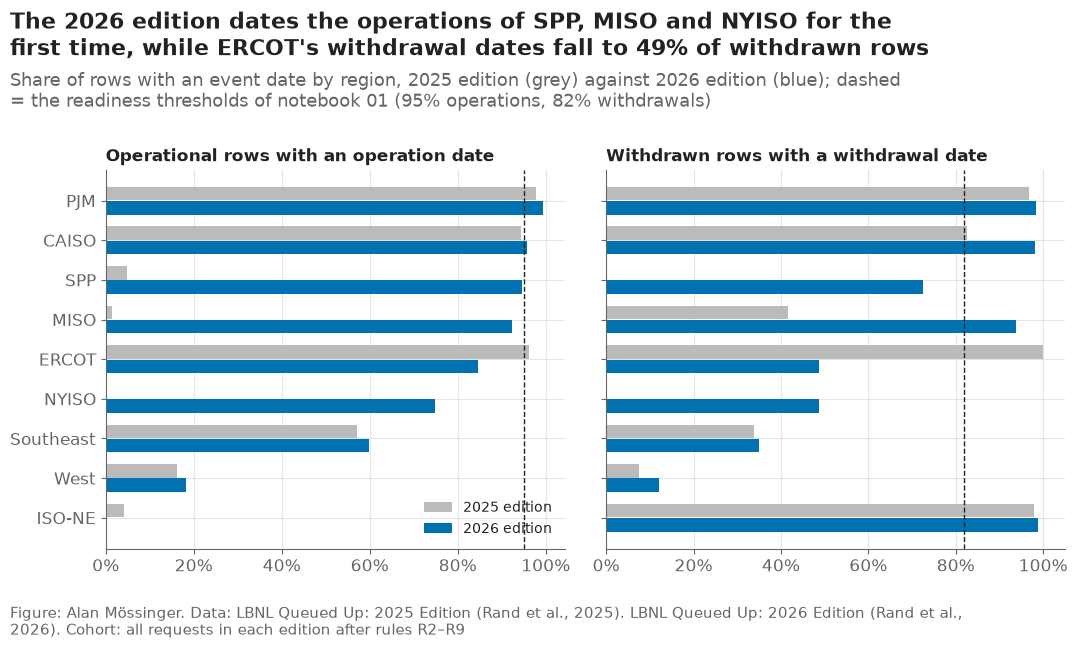

on_date_share        wd_date_share       
edition            2025   2026          2025   2026
region                                             
CAISO             0.943  0.957         0.826  0.982
ERCOT             0.963  0.847         1.000  0.487
ISO-NE            0.041  0.000         0.979  0.988
MISO              0.014  0.924         0.417  0.938
NYISO             0.000  0.748         0.000  0.487
PJM               0.977  0.993         0.969  0.983
SPP               0.049  0.946         0.000  0.726
Southeast         0.572  0.598         0.338  0.349
West              0.161  0.183         0.075  0.121

In [70]:
def coverage(frame, edition):
    op = frame[frame["q_status"] == "operational"].groupby("region")["on_date"].agg(lambda s: s.notna().mean())
    wd = frame[frame["q_status"] == "withdrawn"].groupby("region")["wd_date"].agg(lambda s: s.notna().mean())
    n_op = frame[frame["q_status"] == "operational"].groupby("region").size()
    n_wd = frame[frame["q_status"] == "withdrawn"].groupby("region").size()
    return pd.DataFrame({"edition": edition, "on_date_share": op, "wd_date_share": wd, "n_operational": n_op, "n_withdrawn": n_wd})


cov = pd.concat([coverage(clean_2025, 2025), coverage(clean_2026, 2026)]).reset_index().rename(columns={"index": "region"})
cov.to_csv(paths.RESULTS / "lbnl_2026_date_coverage.csv", index=False)
wide = cov.pivot(index="region", columns="edition", values=["on_date_share", "wd_date_share"])
order = wide.sort_values(("on_date_share", 2026), ascending=False).index

fig, axes = plt.subplots(1, 2, sharey=True)
for ax, what in zip(axes, ["on_date_share", "wd_date_share"]):
    y = np.arange(len(order))
    ax.barh(y - 0.18, wide.loc[order, (what, 2025)], height=0.34, color="#BBBBBB", label="2025 edition")
    ax.barh(y + 0.18, wide.loc[order, (what, 2026)], height=0.34, color="#0072B2", label="2026 edition")
    ax.axvline(config.COVERAGE_MIN_ON_DATE if what == "on_date_share" else config.COVERAGE_MIN_WD_DATE,
               color=plots.INK, linewidth=1, linestyle="--")
    ax.set_yticks(y, order)
    ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title({"on_date_share": "Operational rows with an operation date",
                  "wd_date_share": "Withdrawn rows with a withdrawal date"}[what], fontsize=12)
axes[0].invert_yaxis()
axes[0].legend(loc="lower right", fontsize=10)
newly = [r for r in order if wide.loc[r, ("on_date_share", 2025)] < 0.10 and wide.loc[r, ("on_date_share", 2026)] >= 0.70]
ercot_wd = wide.loc["ERCOT", ("wd_date_share", 2026)]
plots.finish(fig,
             f"The 2026 edition dates the operations of {', '.join(newly[:-1])} and {newly[-1]} for the first time, "
             f"while ERCOT's withdrawal dates fall to {ercot_wd:.0%} of withdrawn rows",
             "Share of rows with an event date by region, 2025 edition (grey) against 2026 edition (blue); dashed = the "
             "readiness thresholds of notebook 01 (95% operations, 82% withdrawals)",
             "all requests in each edition after rules R2–R9", lbnl_2026=True)
save(fig, "01b_01_date_coverage", "Event-date coverage by region in the 2025 and 2026 editions of the LBNL file.")
plt.show()
wide.round(3)

**Reading this.** The 2026 edition changes which regions can carry a timing model. MISO's operations go from 1% dated to 92% and its withdrawals from 42% to 94%; SPP from 5% to 95% and 0% to 73%; NYISO from nothing to 75% and 49%. ERCOT goes the other way: its withdrawal dates fall from 100% to 49% because the stamped block was removed, and its operation dates from 96% to 85%. PJM and CAISO improve slightly, CAISO's withdrawals from 83% to 98%. So the 2026 file supports MISO and SPP timing models (decision #49, notebook 19) and does not support replacing the 2025 file for ERCOT (decision #48). MISO's 92% is below the 95% threshold notebook 01 set for operations; notebook 19 states that and proceeds.

In [71]:
# The Track A rows of the 2026 edition, for the readiness line below. Their 1- and 2-year incidence — the newest
# evidence on the level — is computed in notebook 04 (part F), next to the level repair that uses it, because it is
# compared with the 2025 Track A sample that notebook 03 builds.
ev_2026 = events.code_events(clean_2026, censor_date=CENSOR_2026)
ta_2026 = ev_2026[ev_2026["region"].isin(TRACK_A) & (ev_2026["exclusion"] == "")]
YEARS = [2020, 2021, 2022]

## 6. Readiness lines and checks

The S6 lines of `PLAN.md §5.2`, written into `docs/data_readiness.md` (section "v3 sources") in place of the first-look table.

In [72]:
lines = [
    ("S6 loads and is the stated edition", f"{raw_2026.shape[0]:,} rows × {raw_2026.shape[1]} columns; sheet and header as in 2025; "
     f"{int((~layout['in_2025'] & layout['in_2026']).sum())} columns renamed, {int((layout['in_2025'] & ~layout['in_2026'] & layout['mapped_to'].isna()).sum())} dropped; SHA-256 verified",
     True),
    ("≥ 95% of 2025 requests found in 2026 by (q_id, entity, region)",
     f"{found.mean():.1%} (lowest region {recon.drop('all')['share_found'].idxmin()} {recon.drop('all')['share_found'].min():.1%}); "
     f"{len(new_rows):,} new rows; {dup_2026} duplicate keys", bool(found.mean() >= 0.95)),
    ("status transitions tabulated", f"active at end-2024 → " + ", ".join(f"{k} {v:,}" for k, v in active_2024["q_status_2026"].value_counts().items())
     + f"; withdrawn → operational {moved_back}; operational → active {reopened}", True),
    ("requests whose dates changed listed", "; ".join(f"{r.date}: {r.changed:,} changed, {r['lost in 2026']:,} lost" for _, r in date_changes.iterrows()), True),
    ("2020–2022 early outcomes available", f"{int(ta_2026['q_year'].isin(YEARS).sum()):,} entrants in the three ISOs (2026 edition)", True),
    ("the 2025 file is unchanged", "SHA-256 of the frozen file matches src/config.py",
     hashlib.sha256((paths.RAW_LBNL / config.LBNL_FILENAME).read_bytes()).hexdigest() == config.LBNL_SHA256),
]
table = "| Check (PLAN.md §5.2) | Value | Result |\n|---|---|---|\n" + "\n".join(
    f"| {name} | {value} | {'PASS' if ok else 'FAIL'} |" for name, value, ok in lines)
section = ("## v3 sources — S6, the LBNL 2026 data file (notebook 01, part C)\n\n"
           f"Written by `notebooks/01_problem_and_data.ipynb`. File `{config.LBNL_2026_FILENAME}`, "
           f"SHA-256 `{config.LBNL_2026_SHA256[:8]}…{config.LBNL_2026_SHA256[-5:]}`.\n\n" + table + "\n\n"
           "Event-date coverage by region in both editions: `results/lbnl_2026_date_coverage.csv` (figure 01b_01). "
           "The 2025 file stays the basis of every registered result (decisions #43, #48).\n")
readiness = paths.DOCS / "data_readiness.md"
text = readiness.read_text(encoding="utf-8")
head = text.split("\n## v3 sources")[0].rstrip("\n")
readiness.write_text(head + "\n\n" + section, encoding="utf-8")

checks = pd.DataFrame([{"check": name, "value": value, "pass": ok} for name, value, ok in lines])
checks.to_csv(paths.RESULTS / "lbnl_2026_checks.csv", index=False)
assert checks["pass"].all(), checks
checks[["check", "pass"]]

,check,pass
0,S6 loads and is the stated edition,True
1,"≥ 95% of 2025 requests found in 2026 by (q_id,...",True
2,status transitions tabulated,True
3,requests whose dates changed listed,True
4,2020–2022 early outcomes available,True
5,the 2025 file is unchanged,True


## Takeaways — Part C

- The 2026 edition (38,201 rows, data through 2025) loads with nine renamed columns and real dates; 96.9% of the 2025 requests are found in it, 2,759 rows are new, and 135 appended duplicates are dropped.
- Of 9,815 requests active at end-2024, 2,963 withdrew, 278 reached operation and 238 were suspended during 2025; 63 withdrawn requests reappear as operational and 80 operational ones as active — the file is a snapshot of snapshots.
- MISO, SPP and NYISO operations are dated for the first time (92%, 95%, 75%); ERCOT's withdrawal dates fall to 49% because the 441 stamped withdrawals lost their date.
- 2020–2022 entrants: 1.1%, 0.3% and 0.7% operated within two years (2026 edition); the yardstick for notebook 12.
- **What goes to the report:** the data section (two editions, why both), figure 01b_01, the status-transition table as the "snapshot of snapshots" evidence, and the early-incidence table for the level repair.

# Part D — The v5 energy sources: offshore production, Texas generation, prices, emissions (new, 2026-10-12)

The integrated portfolio (PLAN.md §14, decision #62) puts twenty Gulf of Mexico lease redevelopments and twenty ERCOT power candidates in one book. This part fetches, verifies and parses the public files that describe them — BSEE's OGOR-A production reports, EIA-923 generation for Texas plants, the WTI and Henry Hub spot prices, the ERCOT 2024 hourly prices from my Forecast-to-Dispatch pull, and EPA's eGRID emission rates — and writes the manifest with a SHA-256 for every file. Every figure carries a provenance label (OBSERVED, DERIVED, FORECAST or ASSUMED); where a figure mixes labels it carries the weakest of them and the subtitle says which part is which (decision #64).

## Setup

In [73]:
import json
import sys
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, eia_api, energy_data as ed, paths, plots, value

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

NOTEBOOK = "01_problem_and_data"
START = time.time()
TECHS = ["Gas CC", "Solar", "Wind", "Storage"]  # the four power technologies of the candidates
TECH_COLOR = {"Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"],
              "Storage": config.TECH_COLORS["Battery"], "Other": config.TECH_COLORS["Other"]}


def save(fig, name, caption):
    """Save a figure of this notebook under figures/01_problem_and_data/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)


def pct(x, digits=1):
    """Format a share as a percentage string."""
    return f"{100 * x:.{digits}f}%"


## D.1 BSEE OGOR-A: fifteen years of federal offshore production (S13)

One delimited file per production year, 2010–2024, downloaded by `energy_data.fetch_ogora` and hashed. Each row is a well completion in a month; `energy_data.lease_monthly` sums the completions of a lease, because the lease is the unit a redevelopment is decided on. The candidate pool of notebook 07 is the set of leases with at least 60 producing months (`config.V5_MIN_PRODUCING_MONTHS`).

In [74]:
bsee_log = ed.fetch_ogora()
completions = pd.concat([ed.read_ogora(paths.RAW_BSEE / f) for f in bsee_log["file"]], ignore_index=True)
lease = ed.lease_monthly(completions)
lease.to_parquet(paths.DATA_INTERIM / "upstream_monthly.parquet", index=False)
producing_months = lease[lease["producing"]].groupby("lease_number").size()
eligible = producing_months[producing_months >= config.V5_MIN_PRODUCING_MONTHS]
by_year = (lease[lease["producing"]].assign(year=lease["month"].dt.year)
           .groupby("year").agg(leases=("lease_number", "nunique"), oil_mmbbl=("oil_bbl", lambda s: s.sum() / 1e6),
                                gas_bcf=("gas_mcf", lambda s: s.sum() / 1e6), lease_months=("lease_number", "size")).reset_index())
by_year.to_csv(paths.RESULTS / "v5_bsee_by_year.csv", index=False)
print(f"{len(bsee_log)} files, {bsee_log['bytes'].sum() / 1e6:.1f} MB; {len(completions):,} completion-months -> {len(lease):,} lease-months; "
      f"{lease['lease_number'].nunique():,} leases, {len(eligible):,} with >= {config.V5_MIN_PRODUCING_MONTHS} producing months; "
      f"span {lease['month'].min():%Y-%m} to {lease['month'].max():%Y-%m}; {time.time() - START:.0f} s")
by_year.round(1)


15 files, 37.3 MB; 1,672,579 completion-months -> 203,963 lease-months; 2,229 leases, 1,041 with >= 60 producing months; span 2010-01 to 2024-12; 67 s


,year,leases,oil_mmbbl,gas_bcf,lease_months
0,2010,1532,566.7,2258.6,16180
1,2011,1437,481.9,1833.2,15315
2,2012,1331,465.0,1542.0,14090
3,2013,1202,459.2,1334.2,12873
4,2014,1135,510.7,1281.9,12055
5,2015,1062,553.2,1311.9,11280
6,2016,981,585.9,1224.5,10604
7,2017,922,613.9,1081.7,9974
8,2018,884,642.2,996.3,9532
9,2019,840,693.1,1037.5,8889


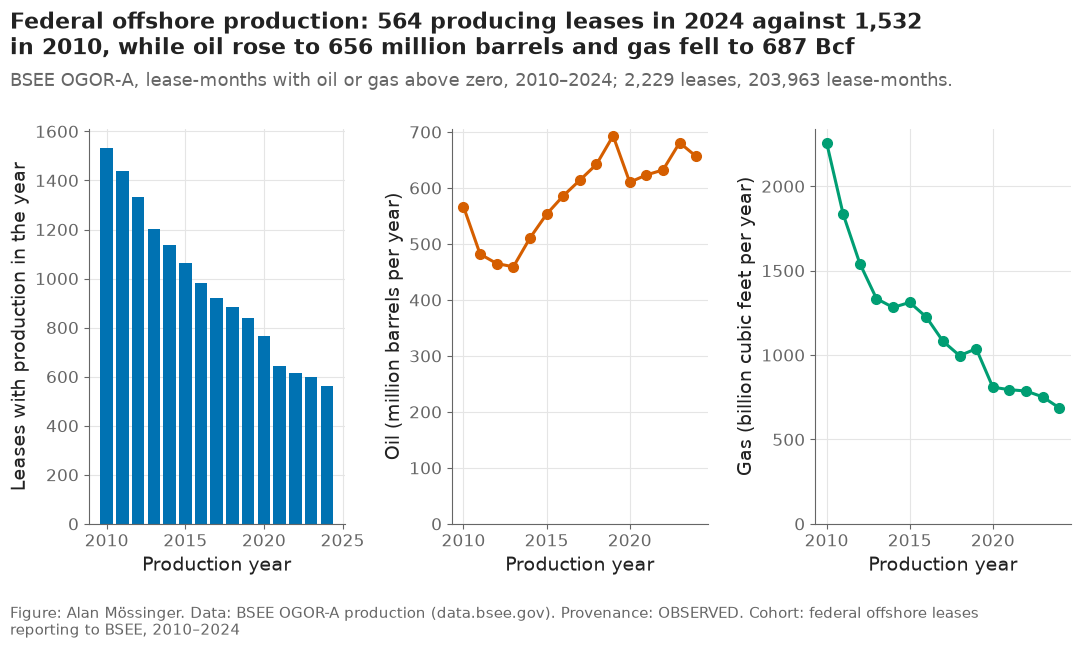

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
axes[0].bar(by_year["year"], by_year["leases"], color="#0072B2")
axes[0].set_ylabel("Leases with production in the year")
axes[1].plot(by_year["year"], by_year["oil_mmbbl"], marker="o", color="#D55E00")
axes[1].set_ylabel("Oil (million barrels per year)")
axes[2].plot(by_year["year"], by_year["gas_bcf"], marker="o", color="#009E73")
axes[2].set_ylabel("Gas (billion cubic feet per year)")
for ax in axes:
    ax.set_xlabel("Production year")
    ax.set_ylim(0, None)
first, last = by_year.iloc[0], by_year.iloc[-1]
plots.finish(fig,
             f"Federal offshore production: {int(last['leases']):,} producing leases in {int(last['year'])} against {int(first['leases']):,} "
             f"in {int(first['year'])}, while oil rose to {last['oil_mmbbl']:.0f} million barrels and gas fell to {last['gas_bcf']:.0f} Bcf",
             f"BSEE OGOR-A, lease-months with oil or gas above zero, {int(first['year'])}–{int(last['year'])}; "
             f"{lease['lease_number'].nunique():,} leases, {len(lease):,} lease-months.",
             f"federal offshore leases reporting to BSEE, {int(first['year'])}–{int(last['year'])}",
             lbnl=False, sources=[config.SOURCE_BSEE], provenance="OBSERVED")
save(fig, "01_D1_bsee_production_by_year", "Producing federal offshore leases, oil and gas volumes per year from BSEE OGOR-A, 2010–2024.")
plt.show()


**Reading this.** The number of producing leases falls through the period as shallow-water gas leases are plugged, while oil volumes rise with the deepwater fields: fewer, larger producers. For the portfolio that is the point of a redevelopment decision — the pool of leases with sixty or more producing months is large (the printed count above), but most of the oil sits in a few of them, so the candidate list of notebook 07 ranks by remaining production rather than by lease count. Gas volumes decline throughout; a gas-weighted redevelopment competes with Henry Hub prices that spent most of the period under $3/MMBtu (D.3). Volumes are as operators report them and BSEE revises them for about three months, which is the release lag the forecasts respect (Part E).

## D.2 EIA-923: Texas plant generation by prime mover, 2018–2024 (S14)

EIA's bulk workbooks returned HTTP 503 on 12 October; the API serves the same data (`electricity/facility-fuel`). `energy_data.pull_eia923` saves every page as returned and `generation_monthly` keeps EIA's grain — plant × prime mover × month — summing the fuel-specific rows so nothing is counted twice and nothing is split to generators. The prime mover gives the technology: combined-cycle parts (CA, CT, CS) are gas CC, PV solar, WT wind, BA batteries.

In [76]:
eia923, pull_923 = ed.pull_eia923()
generation = ed.generation_monthly(eia923)
generation.to_parquet(paths.DATA_INTERIM / "generation_monthly.parquet", index=False)
active = generation[generation["gross_generation_mwh"] > 0]
months_per_plant = active.groupby(["technology", "plant_code"])["month"].nunique()
plants = (months_per_plant.reset_index(name="months").groupby("technology")
          .agg(plants=("plant_code", "nunique"), plants_36_months=("months", lambda m: int((m >= config.V5_MIN_GENERATION_MONTHS).sum())))
          .reindex(TECHS + ["Other"]).reset_index())
plants.to_csv(paths.RESULTS / "v5_texas_plants_by_technology.csv", index=False)
gen_by_tech = generation.groupby(["month", "technology"])["generation_mwh"].sum().unstack("technology").fillna(0) / 1e6
print(f"{pull_923['rows']:,} API rows ({'cache' if pull_923['from_cache'] else 'live'}, {pull_923['pages']} pages) -> "
      f"{len(generation):,} plant × prime-mover months, {generation['plant_code'].nunique():,} plants, "
      f"{generation['month'].min():%Y-%m} to {generation['month'].max():%Y-%m}")
plants


186,744 API rows (cache, 38 pages) -> 61,136 plant × prime-mover months, 947 plants, 2018-01 to 2024-12


,technology,plants,plants_36_months
0,Gas CC,72,69
1,Solar,182,108
2,Wind,228,201
3,Storage,126,18
4,Other,347,295


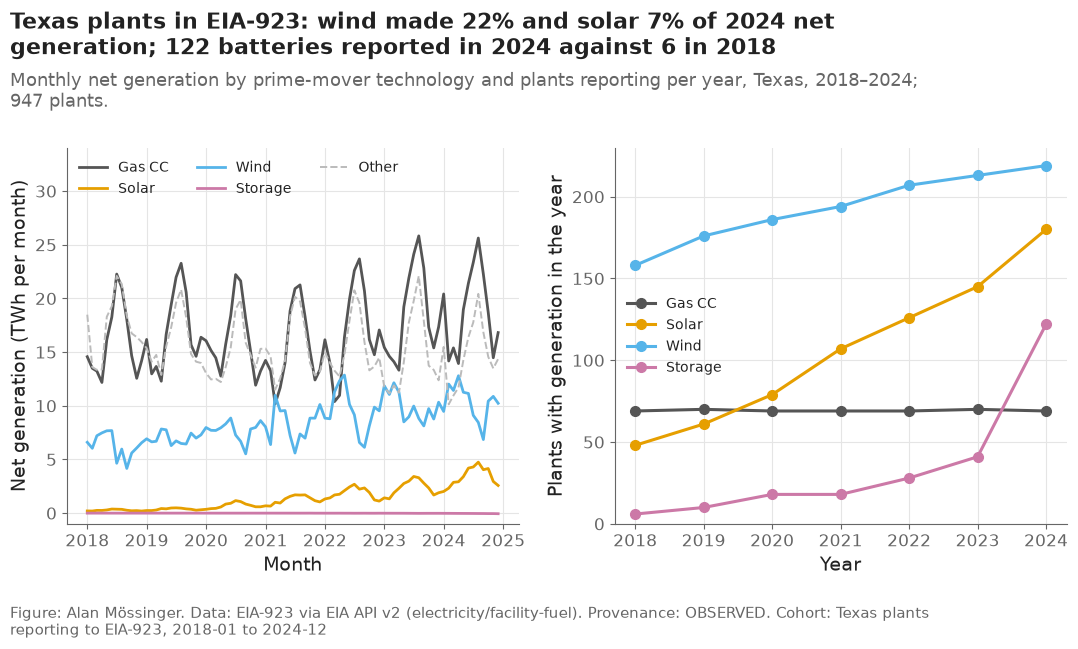

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5))
for tech in TECHS + ["Other"]:
    axes[0].plot(gen_by_tech.index, gen_by_tech[tech], color=TECH_COLOR[tech], label=tech, lw=2 if tech != "Other" else 1.4,
                 linestyle="-" if tech != "Other" else "--")
axes[0].set_ylabel("Net generation (TWh per month)")
axes[0].set_xlabel("Month")
axes[0].set_ylim(-1, 34)
axes[0].legend(loc="upper left", fontsize=10, ncol=3)
yearly_plants = (active.assign(year=active["month"].dt.year).groupby(["year", "technology"])["plant_code"].nunique()
                 .unstack("technology").reindex(columns=TECHS))
for tech in TECHS:
    axes[1].plot(yearly_plants.index, yearly_plants[tech], marker="o", color=TECH_COLOR[tech], label=tech)
axes[1].set_ylabel("Plants with generation in the year")
axes[1].set_xlabel("Year")
axes[1].set_ylim(0, None)
axes[1].legend(loc="center left", fontsize=10)
share_2024 = gen_by_tech.loc["2024"].sum() / gen_by_tech.loc["2024"].sum().sum()
plots.finish(fig,
             f"Texas plants in EIA-923: wind made {share_2024['Wind']:.0%} and solar {share_2024['Solar']:.0%} of 2024 net generation; "
             f"{int(yearly_plants.loc[2024, 'Storage'])} batteries reported in 2024 against {int(yearly_plants.loc[2018, 'Storage'])} in 2018",
             f"Monthly net generation by prime-mover technology and plants reporting per year, Texas, 2018–2024; "
             f"{generation['plant_code'].nunique():,} plants.",
             "Texas plants reporting to EIA-923, 2018-01 to 2024-12",
             lbnl=False, sources=[config.SOURCE_EIA923], provenance="OBSERVED")
save(fig, "01_D2_texas_generation_by_technology", "Monthly net generation by technology and plants reporting per year, Texas plants in EIA-923, 2018–2024.")
plt.show()


**Reading this.** The generation panel the forecasts will learn from is deep for wind and solar (hundreds of plants, most with the full 84 months), adequate for gas combined cycle (about seventy plants) and young for batteries: their net generation is negative by construction (they charge more than they discharge), so the storage target in notebook 05 is gross discharge, and their history is short. That is also why the storage candidates are valued on the 2024 hourly prices with a dispatch program (notebook 07) rather than on a learned generation curve. The 'Other' line (simple-cycle gas turbines, steam units, coal, nuclear, hydro) is kept in the panel for the Texas total but no candidate is drawn from it.

## D.3 Prices: WTI, Henry Hub and ERCOT (S15, S16)

WTI Cushing and Henry Hub are EIA's monthly spot averages (observed). ERCOT is three things stitched end to end and labelled: the 2024 months are the mean of the hourly day-ahead price at the North hub from my Forecast-to-Dispatch pull (observed); 2017–2019 are the annual means of ICE's ERCOT North peak trades that EIA republishes, repeated across the year's months (derived; the ICE files quote peak hours, the DAM mean is all hours — notebook 07 reconciles the two through capture factors); 2020–2023 are PJM West × 0.77, the assumption the value layer already uses (`results/value_assumptions.csv`). The hourly 2018–2023 pull through the ERCOT Public API replaces the assumed months when it runs (decision #64).

In [78]:
price_log = ed.fetch_eia_prices()
wti = ed.read_eia_monthly_price(paths.RAW_PRICES / config.EIA_PRICE_FILES["wti_usd_bbl"][1], "wti_usd_bbl")
hh = ed.read_eia_monthly_price(paths.RAW_PRICES / config.EIA_PRICE_FILES["hh_usd_mmbtu"][1], "hh_usd_mmbtu")
ercot_files = ed.verify_ercot_files()
assert ercot_files["sha256_ok"].all(), ercot_files
history = ed.verify_ercot_history()  # the 2018–2023 yearly files pulled on a U.S. runner (src/ercot_history.py), hashes pinned in config
assert history.loc[history["present"], "sha256_ok"].all(), history
dam_years = sorted(int(p.stem[-4:]) for p in paths.RAW_ERCOT.glob("ercot_dam_spp_*.parquet"))
dam = pd.concat([ed.ercot_dam_monthly(paths.RAW_ERCOT / f"ercot_dam_spp_{y}.parquet") for y in dam_years]).set_index("month")
ice = value.ice_hub_prices()
months = pd.date_range("2017-01-01", config.V5_COVERAGE[1] + "-01", freq="MS")
market = pd.DataFrame({"month": months}).merge(wti, how="left").merge(hh, how="left")
ercot_price, ercot_basis, ercot_prov = [], [], []
for m in months:
    if m in dam.index:  # 2024 from the gridstatus pull; 2018–2023 from ERCOT's yearly files when they are on disk
        ercot_price.append(dam.loc[m, config.ERCOT_PRICE_HUB]); ercot_basis.append(f"DAM {config.ERCOT_PRICE_HUB} monthly mean, all hours"); ercot_prov.append("OBSERVED")
    elif m.year <= 2019:
        ercot_price.append(ice.loc[config.ICE_HUB_ERCOT, m.year]); ercot_basis.append("ICE ERCOT North peak, annual mean"); ercot_prov.append("DERIVED")
    else:
        ercot_price.append(config.ERCOT_BRIDGE_RATIO * ice.loc[config.ICE_HUB_PJM_WEST, m.year]); ercot_basis.append(f"PJM West peak annual mean × {config.ERCOT_BRIDGE_RATIO}"); ercot_prov.append("ASSUMED")
market["ercot_usd_mwh"] = ercot_price
market["ercot_basis"] = ercot_basis
market["ercot_provenance"] = ercot_prov
print(f"WTI {wti['month'].min():%Y-%m}–{wti['month'].max():%Y-%m}, Henry Hub {hh['month'].min():%Y-%m}–{hh['month'].max():%Y-%m}; "
      f"ERCOT months by provenance: {market['ercot_provenance'].value_counts().to_dict()}; "
      f"ERCOT 2024 files verified: {int(ercot_files['sha256_ok'].sum())} of {len(ercot_files)}; hourly years on disk: {dam_years}")
market.groupby(market["month"].dt.year)[["wti_usd_bbl", "hh_usd_mmbtu", "ercot_usd_mwh"]].mean().round(1)


WTI 1986-01–2026-09, Henry Hub 1997-01–2026-09; ERCOT months by provenance: {'OBSERVED': 84, 'DERIVED': 12}; ERCOT 2024 files verified: 5 of 5; hourly years on disk: [2018, 2019, 2020, 2021, 2022, 2023, 2024]


,wti_usd_bbl,hh_usd_mmbtu,ercot_usd_mwh
month,,,
2017,50.9,3.0,27.6
2018,64.9,3.2,33.4
2019,57.0,2.6,37.7
2020,39.2,2.0,22.0
2021,68.0,3.9,156.3
2022,94.8,6.4,64.4
2023,77.6,2.5,55.1
2024,76.6,2.2,27.0


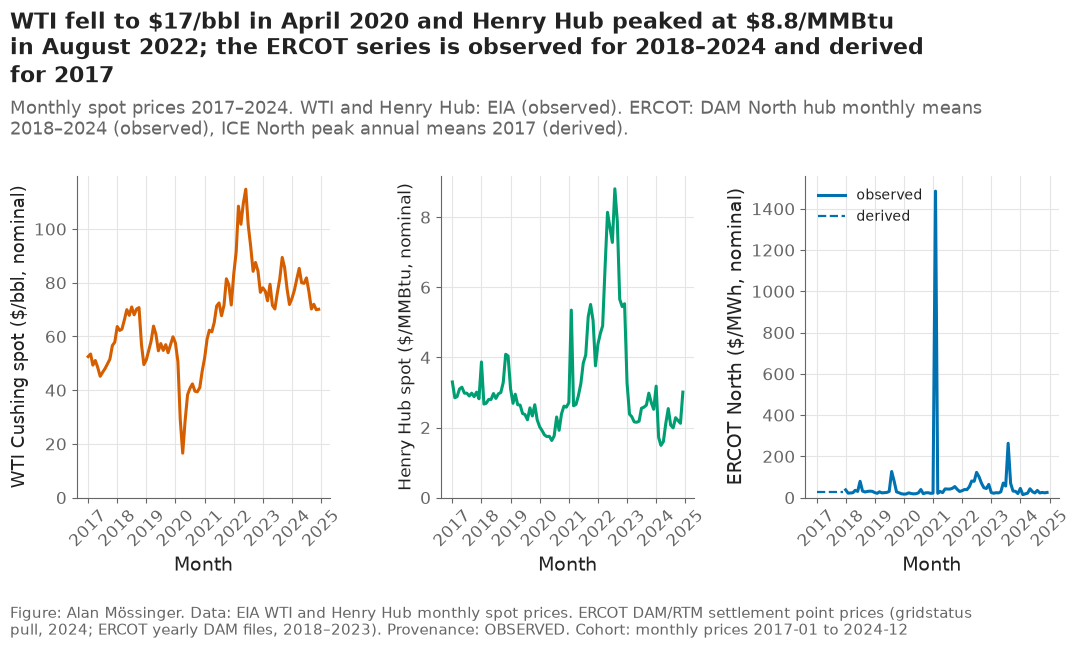

In [79]:
fig, axes = plt.subplots(1, 3, figsize=(11, 6.5))
axes[0].plot(market["month"], market["wti_usd_bbl"], color="#D55E00")
axes[0].set_ylabel("WTI Cushing spot ($/bbl, nominal)")
axes[1].plot(market["month"], market["hh_usd_mmbtu"], color="#009E73")
axes[1].set_ylabel("Henry Hub spot ($/MMBtu, nominal)")
for prov, style in [("OBSERVED", dict(color="#0072B2", lw=2.2)), ("DERIVED", dict(color="#0072B2", lw=1.6, linestyle="--")),
                    ("ASSUMED", dict(color="#999999", lw=1.6, linestyle=":"))]:
    part = market[market["ercot_provenance"] == prov]
    if len(part):  # no legend entry for a provenance with no months (the bridge, once the hourly files are on disk)
        axes[2].plot(part["month"], part["ercot_usd_mwh"], label=prov.lower(), **style)
assumed = market.loc[market["ercot_provenance"] == "ASSUMED", "month"]
if len(assumed):
    axes[2].axvspan(assumed.min(), assumed.max() + pd.offsets.MonthEnd(0), color="#EEEEEE", zorder=0)
axes[2].set_ylabel("ERCOT North ($/MWh, nominal)")
axes[2].legend(loc="upper left", fontsize=10)
for ax in axes:
    ax.set_ylim(0, None)
    ax.set_xlabel("Month")
    ax.tick_params(axis="x", labelrotation=45)
wti_low, hh_high = market.loc[market["wti_usd_bbl"].idxmin()], market.loc[market["hh_usd_mmbtu"].idxmax()]
span = lambda prov: (lambda s: f"{s.min():%Y}–{s.max():%Y}" if s.min().year != s.max().year else f"{s.min():%Y}")(market.loc[market["ercot_provenance"] == prov, "month"])
ercot_note = f"the ERCOT series is observed for {span('OBSERVED')} and derived for {span('DERIVED')}" + (f" and assumed for {span('ASSUMED')}" if len(assumed) else "")
ercot_sub = (f"ERCOT: DAM North hub monthly means {span('OBSERVED')} (observed), ICE North peak annual means {span('DERIVED')} (derived)"
             + (f", PJM West × {config.ERCOT_BRIDGE_RATIO} for {span('ASSUMED')} (assumed; shaded)." if len(assumed) else "."))
plots.finish(fig,
             f"WTI fell to \${wti_low['wti_usd_bbl']:.0f}/bbl in {wti_low['month']:%B %Y} and Henry Hub peaked at \${hh_high['hh_usd_mmbtu']:.1f}/MMBtu "
             f"in {hh_high['month']:%B %Y}; {ercot_note}",
             "Monthly spot prices 2017–2024. WTI and Henry Hub: EIA (observed). " + ercot_sub,
             "monthly prices 2017-01 to 2024-12",
             lbnl=False, sources=[config.SOURCE_EIA_PRICES, config.SOURCE_ERCOT], provenance="ASSUMED" if len(assumed) else "OBSERVED")
save(fig, "01_D3_prices_wti_hh_ercot", "WTI, Henry Hub and ERCOT North monthly prices 2017–2024 with the provenance of each ERCOT segment.")
plt.show()


**Reading this.** Two of the three price processes the scenarios need are fully observed at monthly grain for forty years. The third is the weakest input in the project: four of the eight ERCOT years are an assumption tied to PJM, and the figure says so with its label and shading. The oil collapse of spring 2020 and the gas spike of 2022 are both inside the development window, which is what makes the joint-scenario bootstrap of notebook 08 meaningful — the correlations it preserves include these episodes. Until the ERCOT hourly pull runs, every ERCOT number downstream of 2020–2023 inherits the ASSUMED label.

## D.4 eGRID 2023: emission rates of the Texas plants (S17)

The plant sheet of eGRID gives each Texas plant's CO₂ rate, capacity factor and nameplate for 2023, joined to EIA-923 by the plant code. The rates become the emission factors of the optional carbon constraint in notebook 09; they are not used as forecasts.

In [80]:
egrid_path = ed.fetch_egrid()
egrid = ed.read_egrid_plants(egrid_path)
egrid.to_parquet(paths.DATA_INTERIM / "egrid_plants_tx.parquet", index=False)
joined = generation.loc[(generation["month"].dt.year == 2023) & (generation["gross_generation_mwh"] > 0), "plant_code"].dropna().unique()
in_egrid = np.isin(joined, egrid["plant_code"].to_numpy())  # plants generating in 2023: eGRID2023 cannot hold later openings
egrid_summary = (egrid.groupby("fuel_category").agg(plants=("plant_code", "size"), nameplate_gw=("nameplate_mw", lambda s: s.sum() / 1e3),
                                                     co2_lb_per_mwh_median=("co2_lb_per_mwh", "median"))
                 .sort_values("nameplate_gw", ascending=False).reset_index())
egrid_summary.to_csv(paths.RESULTS / "v5_egrid_tx_summary.csv", index=False)
print(f"eGRID Texas plants: {len(egrid):,}; EIA-923 plants generating in 2023 found in eGRID: {int(in_egrid.sum()):,} of {len(joined):,} ({pct(in_egrid.mean())})")
egrid_summary.round(1)


eGRID Texas plants: 824; EIA-923 plants generating in 2023 found in eGRID: 742 of 751 (98.8%)


,fuel_category,plants,nameplate_gw,co2_lb_per_mwh_median
0,GAS,295,79.4,1396.3
1,WIND,216,40.4,NaN
2,COAL,15,20.6,2377.7
3,SOLAR,144,15.4,NaN
4,NUCLEAR,2,5.1,NaN
5,OTHF,82,3.2,1927.0
6,OFSL,3,1.1,736.8
7,HYDRO,24,0.7,NaN
8,BIOMASS,15,0.4,0.0
9,OIL,28,0.3,1519.0


**Reading this.** Nearly every plant that generated in 2023 has an eGRID record (plants that first reported in 2024, most of them batteries, cannot be in a 2023 file and take the technology median), so the carbon constraint can be built per plant rather than per technology. The median gas-plant rate is what a new combined-cycle candidate is given until its own heat rate from the ATB says otherwise; wind, solar and batteries carry zero. The join rate printed above is the number the readiness gate checks.

## D.5 The manifest

One record per source with the download URL, the retrieval date, the vintage, every file's SHA-256, the units and the grain (`data/raw/manifest_v5.json`). The ERCOT 2024 files are recorded with the hashes pinned in `src/config.py`; the CPI series of Part E is added there too.

In [81]:
cpi_path = ed.fetch_cpi()
manifest = [
    ed.manifest_entry("S13", "BSEE OGOR-A production", config.BSEE_URL, [paths.RAW_BSEE / f for f in bsee_log["file"]], "2010–2024 production years, files as served 2026-10-12",
                      "oil bbl, gas Mcf, water bbl, days", "completion-month (aggregated to lease-month)"),
    ed.manifest_entry("S14", "EIA-923 plant × fuel × prime-mover generation, Texas", f"{config.EIA_API_BASE}/{config.EIA923_ROUTE}/data/",
                      [paths.RAW_EIA923 / f"eia923_{config.EIA923_STATE}_{config.EIA923_START[:4]}-{config.EIA923_END[:4]}.parquet"],
                      f"{config.EIA923_START} to {config.EIA923_END}, API as of 2026-10-12", "MWh, MMBtu", "plant × prime mover × month"),
    ed.manifest_entry("S15", "EIA WTI Cushing and Henry Hub monthly spot prices", "; ".join(u for u, _ in config.EIA_PRICE_FILES.values()),
                      [paths.RAW_PRICES / f for _, f in config.EIA_PRICE_FILES.values()], "through 2026-09", "$/bbl, $/MMBtu, nominal", "month"),
    ed.manifest_entry("S16", "ERCOT 2024 DAM/RTM/MCPC prices, load, wind and solar (gridstatus pull, Forecast to Dispatch)", "https://www.ercot.com/mktinfo",
                      [paths.RAW_ERCOT / f for f in config.ERCOT_2024_FILES], "calendar 2024, pulled 2026-07-07", "$/MWh, MW", "hourly (DAM), 15-minute (RTM)"),
    ed.manifest_entry("S17", "EPA eGRID2023 plant sheet", config.EGRID_URL, [egrid_path], "eGRID2023 revision 1 (January 2025)", "lb CO2/MWh, MW, MWh", "plant-year"),
    ed.manifest_entry("S18", "BLS CPI-U all items, U.S. city average", config.BLS_API_URL, [cpi_path], f"{config.CPI_YEARS[0]}–{config.CPI_YEARS[1]}, pulled 2026-10-12",
                      "index 1982–84 = 100", "month"),
]
manifest_path = ed.write_manifest(manifest)
n_files = sum(len(e["files"]) for e in manifest)
print(f"{manifest_path.relative_to(paths.REPO)}: {len(manifest)} sources, {n_files} files hashed")
pd.DataFrame([{"source": e["source_id"], "name": e["name"], "files": len(e["files"]), "vintage": e["vintage"], "grain": e["grain"]} for e in manifest])


data\raw\manifest_v5.json: 6 sources, 25 files hashed


,source,name,files,vintage,grain
0,S13,BSEE OGOR-A production,15,"2010–2024 production years, files as served 20...",completion-month (aggregated to lease-month)
1,S14,"EIA-923 plant × fuel × prime-mover generation,...",1,"2018-01 to 2024-12, API as of 2026-10-12",plant × prime mover × month
2,S15,EIA WTI Cushing and Henry Hub monthly spot prices,2,through 2026-09,month
3,S16,"ERCOT 2024 DAM/RTM/MCPC prices, load, wind and...",5,"calendar 2024, pulled 2026-07-07","hourly (DAM), 15-minute (RTM)"
4,S17,EPA eGRID2023 plant sheet,1,eGRID2023 revision 1 (January 2025),plant-year
5,S18,"BLS CPI-U all items, U.S. city average",1,"2016–2024, pulled 2026-10-12",month


## Takeaways — Part D

- Five public sources are on disk, hashed and recorded: 15 BSEE files (2010–2024), the EIA-923 Texas pull (2018–2024), the WTI and Henry Hub workbooks, the five ERCOT 2024 files, eGRID 2023, plus the CPI series.
- The lease pool is far larger than the twenty candidates need; the Texas generation panel is deep for wind, solar and gas CC and short for batteries.
- The ERCOT price is the weakest input: observed for 2024, derived for 2017–2019, assumed for 2020–2023 until the hourly pull runs from a network ERCOT accepts.
- **What goes to the report:** figures 01_D1–01_D3 as data-section candidates, `results/v5_bsee_by_year.csv`, `results/v5_texas_plants_by_technology.csv`, the manifest.

# Part E — The energy panel: one grain per table, real dollars, release lags, audits (new, 2026-10-12)

The tables the forecasts and the economics read (PLAN.md §14.2): `upstream_monthly` (lease-month), `generation_monthly` (plant × prime mover × month), `market_monthly` (month, nominal and real 2024 dollars), `plant_generators_tx` (the EIA-860M generators behind the Texas plants) and `release_lags.csv` (what was observable at each forecast origin). Audit rules R10–R13 continue the numbering of the queue file's R1–R9; they count and never change the data.

## E.1 Real 2024 dollars with the CPI-U (S18)

In [82]:
cpi = ed.read_cpi(cpi_path)
cpi.to_parquet(paths.DATA_INTERIM / "cpi_monthly.parquet", index=False)
for column in ["wti_usd_bbl", "hh_usd_mmbtu", "ercot_usd_mwh"]:
    market[f"{column}_real{config.REAL_DOLLAR_YEAR}"] = ed.to_real(market[column], market["month"], cpi)
market.to_parquet(paths.DATA_INTERIM / "market_monthly.parquet", index=False)
cpi_2024 = cpi[cpi["month"].dt.year == config.REAL_DOLLAR_YEAR]["cpi_u"].mean()
cpi_2018 = cpi[cpi["month"].dt.year == 2018]["cpi_u"].mean()
print(f"CPI-U {cpi['month'].min():%Y-%m}–{cpi['month'].max():%Y-%m}; 2024 mean {cpi_2024:.1f}, 2018 mean {cpi_2018:.1f}: "
      f"a 2018 dollar is {cpi_2024 / cpi_2018:.3f} 2024 dollars")
market.groupby(market["month"].dt.year)[["wti_usd_bbl", f"wti_usd_bbl_real{config.REAL_DOLLAR_YEAR}", "hh_usd_mmbtu", f"hh_usd_mmbtu_real{config.REAL_DOLLAR_YEAR}"]].mean().round(1)


CPI-U 2016-01–2024-12; 2024 mean 313.7, 2018 mean 251.1: a 2018 dollar is 1.249 2024 dollars


,wti_usd_bbl,wti_usd_bbl_real2024,hh_usd_mmbtu,hh_usd_mmbtu_real2024
month,,,,
2017,50.9,65.1,3.0,3.8
2018,64.9,81.1,3.2,4.0
2019,57.0,69.9,2.6,3.2
2020,39.2,47.5,2.0,2.5
2021,68.0,78.6,3.9,4.5
2022,94.8,101.7,6.4,6.9
2023,77.6,79.9,2.5,2.6
2024,76.6,76.6,2.2,2.2


**Reading this.** Prices from 2018 are worth about a quarter more in 2024 purchasing power, which matters when a 2018 cash flow is set beside a 2024 one in the same NPV. Every cash flow in notebooks 07–09 is in 2024 dollars; the ATB costs, published in 2022 dollars, are converted with the same index.

## E.2 The generators behind the Texas plants (EIA-860M, S2)

In [83]:
generators = pd.read_parquet(sorted(paths.RAW_EIA860M.glob("eia860m_*.parquet"))[-1])
texas = generators[generators["stateid"] == config.EIA923_STATE].copy()
texas["plant_code"] = pd.to_numeric(texas["plantid"], errors="coerce").astype("Int64")
texas["technology_group"] = texas["prime_mover_code"].map(config.PRIME_MOVER_TECH).fillna("Other")
plant_generators = texas[["plant_code", "plantName", "generatorid", "technology", "technology_group", "prime_mover_code", "energy_source_code",
                          "nameplate-capacity-mw", "operating-year-month", "status", "county", "latitude", "longitude", "balancing_authority_code"]]
plant_generators = plant_generators.rename(columns={"plantName": "plant_name", "nameplate-capacity-mw": "nameplate_mw",
                                                    "operating-year-month": "operating_month", "balancing_authority_code": "balancing_authority"})
plant_generators.to_parquet(paths.DATA_INTERIM / "plant_generators_tx.parquet", index=False)
covered = generation["plant_code"].dropna().unique()
with_generators = np.isin(covered, plant_generators["plant_code"].dropna().unique())
print(f"{len(plant_generators):,} Texas generators at {plant_generators['plant_code'].nunique():,} plants (EIA-860M {generators['period'].iloc[0]}); "
      f"EIA-923 plants with a generator record: {int(with_generators.sum()):,} of {len(covered):,} ({pct(with_generators.mean())})")
plant_generators.groupby("technology_group").agg(generators=("generatorid", "size"), plants=("plant_code", "nunique"),
                                                 nameplate_gw=("nameplate_mw", lambda s: s.sum() / 1e3)).round(1)


2,480 Texas generators at 1,090 plants (EIA-860M 2026-07); EIA-923 plants with a generator record: 899 of 947 (94.9%)


,generators,plants,nameplate_gw
technology_group,,,
Gas CC,292,68,48.3
Other,1432,338,60.0
Solar,255,242,33.3
Storage,258,254,18.3
Wind,243,228,43.9


**Reading this.** The inventory supplies what the generation panel lacks — nameplate, operating month, coordinates — so a plant's capacity factor is its generation over its nameplate, and a candidate's site can be placed on the map. The table is at generator grain and is never joined to generation at that grain; only its plant-level sums are (PLAN.md §14.2).

## E.3 Release lags: what a forecast made on a given day could have seen

In [84]:
release_lags = pd.DataFrame([{"source": s, "lag_months": lag, "basis": "publisher's release schedule (documented in data/README.md)", "provenance": "ASSUMED"}
                             for s, lag in config.RELEASE_LAGS.items()])
release_lags.to_csv(paths.DATA_PROCESSED / "release_lags.csv", index=False)
release_lags


,source,lag_months,basis,provenance
0,BSEE OGOR-A,3,publisher's release schedule (documented in da...,ASSUMED
1,EIA-923 monthly,2,publisher's release schedule (documented in da...,ASSUMED
2,EIA-860M,2,publisher's release schedule (documented in da...,ASSUMED
3,"WTI, Henry Hub",0,publisher's release schedule (documented in da...,ASSUMED
4,ERCOT DAM/RTM,0,publisher's release schedule (documented in da...,ASSUMED
5,BLS CPI-U,1,publisher's release schedule (documented in da...,ASSUMED


**Reading this.** A forecast origin at the end of month *t* may use BSEE production through *t* − 3, EIA-923 through *t* − 2 and prices through *t*. Notebook 03 lags every feature by these months and proves with a truncation test that removing post-origin rows changes no feature. The lags are stated from the publishers' schedules, not measured, hence the label.

## E.4 Audits R10–R13 and the panel summary

In [85]:
audits = ed.panel_audits(lease, generation, market)
audits.to_csv(paths.RESULTS / "v5_panel_audits.csv", index=False)
summary = pd.DataFrame([
    {"table": "data/interim/upstream_monthly.parquet", "grain": "lease-month", "rows": len(lease), "keys": lease["lease_number"].nunique(),
     "span": f"{lease['month'].min():%Y-%m} to {lease['month'].max():%Y-%m}", "units": "bbl, Mcf, days", "provenance": "OBSERVED"},
    {"table": "data/interim/generation_monthly.parquet", "grain": "plant × prime mover × month", "rows": len(generation), "keys": generation["plant_code"].nunique(),
     "span": f"{generation['month'].min():%Y-%m} to {generation['month'].max():%Y-%m}", "units": "MWh, MMBtu", "provenance": "OBSERVED"},
    {"table": "data/interim/market_monthly.parquet", "grain": "month", "rows": len(market), "keys": 3,
     "span": f"{market['month'].min():%Y-%m} to {market['month'].max():%Y-%m}", "units": "$/bbl, $/MMBtu, $/MWh (nominal and real 2024)",
     "provenance": "OBSERVED; ERCOT " + ", ".join(f"{p.lower()} {n} months" for p, n in market["ercot_provenance"].value_counts().items())},
    {"table": "data/interim/plant_generators_tx.parquet", "grain": "generator", "rows": len(plant_generators), "keys": plant_generators["plant_code"].nunique(),
     "span": str(generators["period"].iloc[0]), "units": "MW", "provenance": "OBSERVED"},
    {"table": "data/interim/egrid_plants_tx.parquet", "grain": "plant-year", "rows": len(egrid), "keys": egrid["plant_code"].nunique(), "span": "2023",
     "units": "lb CO2/MWh, MW", "provenance": "OBSERVED"},
])
summary.to_csv(paths.DATA_PROCESSED / "energy_panel_summary.csv", index=False)
print(audits.to_string(index=False))
summary


rule                                                      item  rows                                      note
 R10                             duplicate (lease, month) keys     0                                 must be 0
 R10                duplicate (plant, prime mover, month) keys     0                                 must be 0
 R11                       lease-months with a negative volume     0                              not expected
 R11                        lease-months with zero oil and gas 51603           kept; flagged producing = False
 R12                 plant-months with negative net generation  2729 kept; storage and pumped hydro draw power
 R13            wti_usd_bbl: months missing in 2018-01→2024-12     0          must be 0 for every priced month
 R13           hh_usd_mmbtu: months missing in 2018-01→2024-12     0          must be 0 for every priced month
 R13          ercot_usd_mwh: months missing in 2018-01→2024-12     0          must be 0 for every priced month
 

,table,grain,rows,keys,span,units,provenance
0,data/interim/upstream_monthly.parquet,lease-month,203963,2229,2010-01 to 2024-12,"bbl, Mcf, days",OBSERVED
1,data/interim/generation_monthly.parquet,plant × prime mover × month,61136,947,2018-01 to 2024-12,"MWh, MMBtu",OBSERVED
2,data/interim/market_monthly.parquet,month,96,3,2017-01 to 2024-12,"$/bbl, $/MMBtu, $/MWh (nominal and real 2024)","OBSERVED; ERCOT observed 84 months, derived 12..."
3,data/interim/plant_generators_tx.parquet,generator,2480,1090,2026-07,MW,OBSERVED
4,data/interim/egrid_plants_tx.parquet,plant-year,824,824,2023,"lb CO2/MWh, MW",OBSERVED


**Reading this.** The joins are one-to-many by construction (no duplicate keys, R10), no volume is negative (R11), the negative plant-months are the batteries' charging (R12), and the only market series with a gap inside the window is none — the ERCOT bridge is filled, labelled, not missing (R13). The zero-production lease-months are kept with a flag: a lease that stops producing is a fact the decline features need.

## E.5 The v5 readiness gate

The lines of PLAN.md §14.1, scored from the tables above and written as a new section of `docs/data_readiness.md` ending in GO or NO-GO. The ERCOT hourly 2018–2023 line is reported and does not block: the plan accepts the labelled bridge until the pull runs (decision #64).

In [86]:
v5_checks = []


def v5_check(name, condition, observed, passed, blocking=True):
    v5_checks.append({"check": name, "pass condition": condition, "observed": observed, "result": "PASS" if passed else "FAIL",
                      "blocking": blocking})


window = (pd.Timestamp(config.V5_COVERAGE[0]), pd.Timestamp(config.V5_COVERAGE[1]))
lease_span = (lease["month"].min() <= window[0]) and (lease["month"].max() >= window[1])
v5_check("S13 BSEE files present and hashed", f"{config.BSEE_YEARS[1] - config.BSEE_YEARS[0] + 1} files, SHA-256 in SHA256.txt and the manifest",
         f"{len(bsee_log)} files, {len(manifest[0]['files'])} hashes", len(bsee_log) == config.BSEE_YEARS[1] - config.BSEE_YEARS[0] + 1)
v5_check("S13 lease-months cover the window", f"{config.V5_COVERAGE[0]} to {config.V5_COVERAGE[1]}",
         f"{lease['month'].min():%Y-%m} to {lease['month'].max():%Y-%m}", bool(lease_span))
v5_check("S13 candidate pool", f">= {config.V5_MIN_LEASES} leases with >= {config.V5_MIN_PRODUCING_MONTHS} producing months",
         f"{len(eligible):,} leases", len(eligible) >= config.V5_MIN_LEASES)
v5_check("S14 EIA-923 pull complete", "rows received = total reported; window covered",
         f"{pull_923['rows']:,} of {pull_923['total']:,}; {generation['month'].min():%Y-%m} to {generation['month'].max():%Y-%m}",
         pull_923["rows"] == pull_923["total"] and generation["month"].min() <= window[0] and generation["month"].max() >= window[1])
per_tech = plants.set_index("technology").loc[TECHS, "plants_36_months"]
v5_check("S14 Texas plants per technology", f">= {config.V5_MIN_PLANTS_PER_TECH} plants with >= {config.V5_MIN_GENERATION_MONTHS} generating months for each of {', '.join(TECHS)}",
         ", ".join(f"{t} {int(n)}" for t, n in per_tech.items()), bool((per_tech >= config.V5_MIN_PLANTS_PER_TECH).all()))
price_cover = {c: market.loc[market["month"].between(*window), c].notna().all() for c in ["wti_usd_bbl", "hh_usd_mmbtu", "ercot_usd_mwh"]}
v5_check("S15/S16 monthly prices cover the window", "WTI, Henry Hub and ERCOT present for every month (ERCOT: observed, derived or labelled assumed)",
         ", ".join(f"{k} {'complete' if v else 'gaps'}" for k, v in price_cover.items()), all(price_cover.values()))
v5_check("S16 ERCOT 2024 files verified", "five files, SHA-256 as pinned in src/config.py", f"{int(ercot_files['sha256_ok'].sum())} of {len(ercot_files)}",
         bool(ercot_files["sha256_ok"].all()))
ercot_hourly_years = sorted(int(p.stem[-4:]) for p in paths.RAW_ERCOT.glob("ercot_dam_spp_*.parquet"))
v5_check("S16 ERCOT hourly prices 2018–2023 on disk and hashed", "ercot_dam_spp_<year>.parquet for 2018–2023 from ERCOT's yearly files, SHA-256 as pinned in src/config.py",
         f"years on disk: {ercot_hourly_years}; verified: {int(history['sha256_ok'].sum())} of {len(history)}; assumed months: {int((market['ercot_provenance'] == 'ASSUMED').sum())}",
         bool(history["sha256_ok"].all()), blocking=False)
v5_check("S17 eGRID joins the generation panel", ">= 95% of the EIA-923 plants generating in 2023 found in eGRID2023", pct(in_egrid.mean()), bool(in_egrid.mean() >= 0.95))
v5_check("S18 CPI-U covers the window", f"{config.CPI_YEARS[0]}–{config.CPI_YEARS[1]} monthly", f"{cpi['month'].min():%Y-%m} to {cpi['month'].max():%Y-%m}, {len(cpi)} months",
         cpi["month"].min() <= window[0] and cpi["month"].max() >= window[1])
v5_check("Manifest complete", "every raw file of S13–S18 hashed with URL, vintage, units, grain", f"{len(manifest)} sources, {n_files} files",
         all(e["files"] and e["url"] and e["units"] for e in manifest))
v5_check("Audits R10–R13", "no duplicate keys, no negative volumes, no missing priced month", "; ".join(f"{r.rule} {r.item}: {r.rows}" for r in audits.itertuples() if r.rule != "R12"),
         int(audits.loc[audits["item"].str.contains("duplicate|negative volume|missing"), "rows"].sum()) == 0)
pages = list(paths.RAW_EIA923.glob("api_*.json"))
key_free = all(eia_api.load_api_key() not in p.read_text(encoding="utf-8") for p in pages)
v5_check("Secrets safe", "no API key in any saved page", f"{len(pages)} EIA-923 pages checked", key_free)
v5_table = pd.DataFrame(v5_checks)
v5_table.to_csv(paths.RESULTS / "v5_readiness_checks.csv", index=False)
go = bool(v5_table.loc[v5_table["blocking"], "result"].eq("PASS").all())
section = "\n\n".join([
    "## v5 sources — the energy panel (notebook 01, parts D and E)",
    f"*Written by `notebooks/01_problem_and_data.ipynb` on {date.today().isoformat()}. Every number below was computed by that notebook; "
    "thresholds are in `src/config.py` (PLAN.md §14.1).*",
    "| Check | Pass condition | Observed | Result |\n|---|---|---|---|\n" + "\n".join(
        f"| {r['check']} | {r['pass condition']} | {r['observed']} | {r['result']} |" for r in v5_checks),
    "Non-blocking lines are reported for the record; with the 2018–2023 hourly files on disk (decision #78) no ERCOT month is assumed, and without them the bridge of decision #64 fills 2020–2023.",
    f"**Outcome ({date.today().isoformat()}): {'GO' if go else 'NO-GO'}**",
])
readiness = paths.DOCS / "data_readiness.md"
text = readiness.read_text(encoding="utf-8")
head = text.split("\n## v5 sources")[0].rstrip("\n")
readiness.write_text(head + "\n\n" + section + "\n", encoding="utf-8")
print(f"v5 gate: {'GO' if go else 'NO-GO'} — {int(v5_table['result'].eq('PASS').sum())} of {len(v5_table)} lines pass "
      f"({int((~v5_table['blocking']).sum())} non-blocking); {(time.time() - START) / 60:.1f} min")
v5_table[["check", "observed", "result", "blocking"]]


v5 gate: GO — 13 of 13 lines pass (1 non-blocking); 1.5 min


,check,observed,result,blocking
0,S13 BSEE files present and hashed,"15 files, 15 hashes",PASS,True
1,S13 lease-months cover the window,2010-01 to 2024-12,PASS,True
2,S13 candidate pool,"1,041 leases",PASS,True
3,S14 EIA-923 pull complete,"186,744 of 186,744; 2018-01 to 2024-12",PASS,True
4,S14 Texas plants per technology,"Gas CC 69, Solar 108, Wind 201, Storage 18",PASS,True
5,S15/S16 monthly prices cover the window,"wti_usd_bbl complete, hh_usd_mmbtu complete, e...",PASS,True
6,S16 ERCOT 2024 files verified,5 of 5,PASS,True
7,S16 ERCOT hourly prices 2018–2023 on disk and ...,"years on disk: [2018, 2019, 2020, 2021, 2022, ...",PASS,False
8,S17 eGRID joins the generation panel,98.8%,PASS,True
9,S18 CPI-U covers the window,"2016-01 to 2024-12, 108 months",PASS,True


**Reading this.** Every blocking line passes, so the v5 gate reads **GO** and the modelling notebooks may start. The one failing line is the ERCOT hourly history for 2018–2023, which the plan accepts as a labelled assumption; it is the first thing to replace, and the gate will show it as PASS once the files are on disk. The battery count is the thinnest pass: eighteen Texas batteries have three years of history, enough for a pooled capacity-factor distribution but not for a plant-level model, which is why storage is valued by dispatch rather than by a learned curve.

## Takeaways — Part E

- Five interim tables at their native grain, in nominal and real 2024 dollars; no join below the plant level.
- Release lags are written down before any feature is built, so leakage is testable, not assumed.
- Audits R10–R13 touch nothing: zero duplicates, zero negative volumes, the batteries' negative months kept as physics.
- The v5 gate is GO; the ERCOT hourly history is the open non-blocking line.
- **What goes to the report:** `data/processed/energy_panel_summary.csv`, `data/processed/release_lags.csv`, the v5 section of `docs/data_readiness.md`.

## Takeaways

- **Part A** — Get the data and pass the readiness gate: the frozen LBNL file reproduces its audit and headlines; the EIA-860M pull works; the v1 gate is GO.
- **Part B** — Clean the queue data: rules R1–R9, each logged with the rows it touched.
- **Part C** — The LBNL 2026 file beside the frozen 2025 file: reconciliation, date changes, the v3 readiness lines.
- **Part D** — The v5 energy sources: BSEE production, EIA-923 Texas generation, WTI, Henry Hub and ERCOT prices, eGRID, the manifest.
- **Part E** — The energy panel: real 2024 dollars, the Texas generators, release lags, audits R10–R13, the v5 gate (GO).

**What goes to the report.** Report figures drawn here: none (the data section uses F9 and the tables); candidate figures 01_D1–01_D3. Every number the report cites from this notebook is read from `results/` by `src/report_numbers.py`.